<a href="https://colab.research.google.com/github/Fqrina/ai-archive/blob/main/2_Final_OSN_AI_2025.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 😄 *Computer Vision Task: Face or Flag*?

Bayangkan kamu seorang **kurator emoji di sebuah pameran besar**. Setiap ikon terlihat mirip, kecil, warna-warni, dan seragam ukurannya, tetapi sebenarnya mereka berasal dari **dua kelas** yang berbeda: *Face* (**wajah**) dan `Flag` (**bendera**). Tugasmu sederhana, yaitu membuat pemilah emoji otomatis untuk tiap-tiap emoji yang diberikan, memutuskan apakah sebuah emoji termasuk kelas *Face* atau *Flag* seakurat mungkin.

## Piksel dan Gambar Digital
**Gambar digital** disusun dari kotak-kotak kecil yang disebut **piksel** *(pixel)*. Setiap piksel menyimpan informasi warna. Untuk gambar digital, warna biasanya disimpan di dalam sebuah **model RGB**. RGB adalah singkatan dari *Red* (merah), *Green* (hijau), *Blue* (biru), sehingga **setiap piksel** direpresentasikan oleh tiga angka `[R, G, B]` untuk tiap-tiap *channel* (kanal). Ketiga angka itu menunjukkan seberapa terang warna merah, hijau, dan biru “menyala” di masing-masing kanal RGB secara bersamaan di piksel tersebut. Nilai pada masing-masing kanal RGB umumnya bernilai diantara `0-255`, dimana nilai `0` berarti kanal tersebut **mati** *(gelap)* sedangkan nilai `255` berarti kanal tersebut **menyala** *dengan intensitas maksimal.*

![Gambar RGB dan tiap-tiap kanal merah, biru, dan hijau](https://drive.google.com/uc?export=view&id=1Et521rYHQxdUDlqAhrquGuyxgo4EGe1D)

Contoh:
1. Hitam = `[0, 0, 0]` (semua mati)
2. Putih = `[255, 255, 255]` (semua menyala penuh)
3. Merah murni = `[255, 0, 0]`
4. Hijau murni = `[0, 255, 0]`
5. Biru murni = `[0, 0, 255]`
6. Kuning = `[255, 255, 0]`
7. Biru muda *(cyan)* = `[0, 255, 255]`
8. Ungu muda *(magenta)* = `[255, 0, 255]`
9. Oranye = `[255, 165, 0]`

![RGB Model](https://drive.google.com/uc?export=view&id=1FmoVfh2wKyb_LzzaJHfNzttCq3VqrI9g)

## Histogram dari gambar digital RGB

Histogram kanal RGB adalah ringkasan statistik yang menunjukkan seberapa sering setiap nilai intensitas warna R, G, dan B (umumnya pada rentang 0–255) muncul di seluruh piksel sebuah gambar. Sumbu-X mewakili nilai intensitas (dari gelap dengan nilai 0 sampai ke terang dengan nilai 255), sedangkan sumbu-Y menunjukkan jumlah kemunculan (atau probabilitas jika dinormalisasi, sehingga total area = 1). Dengan menggambarkan ketiga kanal untuk warna merah, hijau, dan biru secara bersama-sama, kita bisa melihat warna mana yang dominan (memiliki puncak tinggi), seberapa “kontras” gambar (sebaran intensitas yang sempit vs lebar), adanya pencahayaan berlebih/kurang (penumpukan di ujung kanan/kiri histogram), serta pola campuran warna (puncak ganda/multimodal). Perbandingan bentuk histogram antarkanal membantu memahami karakter warna gambar tanpa melihatnya secara visual, berguna untuk deskripsi data, pemilihan nilai ambang sederhana, dan deteksi perbedaan objek pada gambar.

![RGB Histogram](https://drive.google.com/uc?export=view&id=19fPe0PmM_Dlr7iLaqlZyDMHUp8pwbCAR)

## Dataset yang tersedia
* **Train:** Gambar emoji terdapat di dalam variabel `X_train` yang terdiri dari 160 gambar emoji dengan ukuran 64x64 dengan 3 *channel* RGB. Kelas untuk masing-masing gambar bisa ditemukan di variabel `y_train` dimana nilai `1 = Faces` dan `2 = Flags`.
* **Test:** Variabel `X_test` terdiri dari 310 gambar emoji dengan ukuran dan jumlah *channel* yang sama dengan `X_train`. Akan tetapi, gambar-gambar emoji di `X_test` tidak memiliki informasi kelas untuk masing-masing emoji. **Dataset Test akan diberikan sebelum 1 jam kontes berakhir.**

## Aturan
* Anda bebas memilih dan menggunakan pra-proses dan pendekatan pemodelan yang terbaik.
* Anda tidak diperkenankan untuk menggunakan data eksternal yang mengandung emoji serupa.
* Penilaian akhir akan menggunakan akurasi pada set uji `X_test`.


## Download data (TIDAK PERLU DIUBAH)

In [ ]:
# @title
!pip -q install gdown

FILE_ID = "1YC1i-DN3DOnV8MGqorKl6yTgSERah0wa"  # WITHOUT THE KEYS
!gdown --id {FILE_ID} -O OSNAI2025_public.zip
!unzip -o OSNAI2025_public.zip -d /content/

# Import path
import sys
sys.path.append("/content/OSNAI2025_pack")

from emoji_train import X_train, y_train
from emoji_test import X_test

print("Shapes:", X_train.shape, y_train.shape, X_test.shape)
print("Unique labels in train:", sorted(set(y_train.tolist())))

/usr/local/lib/python3.12/dist-packages/gdown/__main__.py:139: FutureWarning: Option `--id` was deprecated in version 4.3.1 and will be removed in 5.0. You don't need to pass it anymore to use a file ID.
  warnings.warn(
Downloading...
From: https://drive.google.com/uc?id=1YC1i-DN3DOnV8MGqorKl6yTgSERah0wa
To: /content/OSNAI2025_public.zip
100% 2.28M/2.28M [00:00<00:00, 245MB/s]
Archive:  OSNAI2025_public.zip
  inflating: /content/label_map.json  
  inflating: /content/emoji_train.py  
  inflating: /content/emoji_test.py  
  inflating: /content/build_stats.json  
Shapes: (160, 64, 64, 3) (160,) (310, 64, 64, 3)
Unique labels in train: [1, 2]


## Fungsi util untuk evaluasi (TIDAK PERLU DIUBAH)

In [ ]:
# ------------------------------
# Util sederhana untuk evaluasi
# ------------------------------
def _safe_div(a, b):
    return (a / b) if b != 0 else 0.0

def evaluate_binary_12(y_true, y_pred):
    """
    Evaluasi untuk label {1, 2}:
    - Akurasi
    - F1-score macro
    """
    C11 = C12 = C21 = C22 = 0
    n = min(len(y_true), len(y_pred))
    for i in range(n):
        t = int(y_true[i])
        p = int(y_pred[i])
        if   t == 1 and p == 1: C11 += 1
        elif t == 1 and p == 2: C12 += 1
        elif t == 2 and p == 1: C21 += 1
        elif t == 2 and p == 2: C22 += 1
        # jika nilai di luar {1,2}, otomatis tak terhitung

    support1 = C11 + C12
    support2 = C21 + C22
    total    = support1 + support2

    acc = _safe_div(C11 + C22, total)

    # Kelas 1
    prec1 = _safe_div(C11, (C11 + C21))   # TP1 / (TP1 + FP1)
    rec1  = _safe_div(C11, (C11 + C12))   # TP1 / (TP1 + FN1)
    f1_1  = _safe_div(2*prec1*rec1, (prec1 + rec1)) if (prec1 + rec1) > 0 else 0.0

    # Kelas 2
    prec2 = _safe_div(C22, (C22 + C12))   # TP2 / (TP2 + FP2)
    rec2  = _safe_div(C22, (C22 + C21))   # TP2 / (TP2 + FN2)
    f1_2  = _safe_div(2*prec2*rec2, (prec2 + rec2)) if (prec2 + rec2) > 0 else 0.0

    f1_macro = (f1_1 + f1_2) / 2.0

    return acc, f1_macro

## Memperlihatkan contoh gambar emoji dan kelasnya dalam grid (TIDAK PERLU DIUBAH)

Ukuran (shapes) dari dataset:
  X_train: (160, 64, 64, 3)  y_train: (160,)
  X_test : (310, 64, 64, 3)
Label unik yang tersedia di dataset: [1, 2]


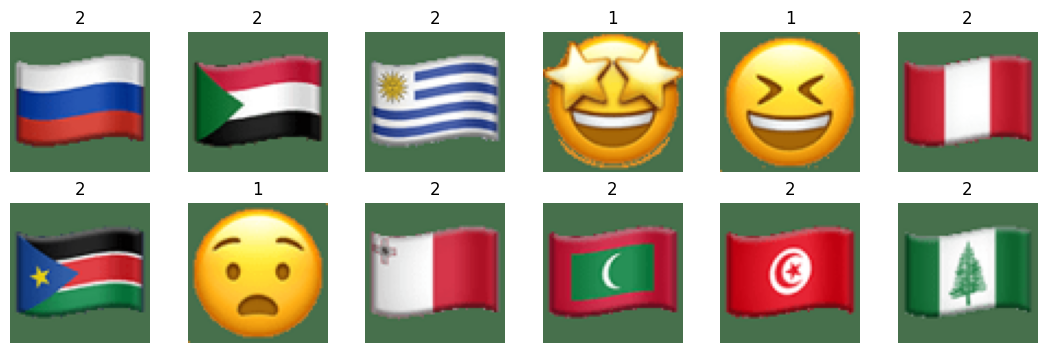

In [ ]:
print("Ukuran (shapes) dari dataset:")
print("  X_train:", X_train.shape, " y_train:", y_train.shape)
print("  X_test :", X_test.shape)

# Label yang tersedia di train (harus 1..5)
print("Label unik yang tersedia di dataset:", sorted(set(y_train.tolist())))

# Tampilkan beberapa contoh gambar + label (matplotlib)
import numpy as np
import matplotlib.pyplot as plt

def show_grid(images, labels=None, n=12, cols=6):
    n = min(n, len(images))
    rows = (n + cols - 1) // cols
    plt.figure(figsize=(1.8*cols, 1.8*rows))
    for i in range(n):
        ax = plt.subplot(rows, cols, i+1)
        ax.imshow(images[i])
        ax.axis("off")
        if labels is not None:
            ax.set_title(str(labels[i]))
    plt.tight_layout()
    plt.show()

# Acak indeks hanya untuk visualisasi
rng = np.random.RandomState(0)
idx = rng.choice(len(X_train), size=12, replace=False)
show_grid(X_train[idx], y_train[idx])

## CONTOH Mengakses 1 buah gambar emoji dan memperlihatkan masing-masing kanal RGB

Index: 0 | Label: 1 | Ukuran: 64x64 | Kanal: 3
Contoh piksel di (baris=10, kolom=20): R=255, G=252, B=190


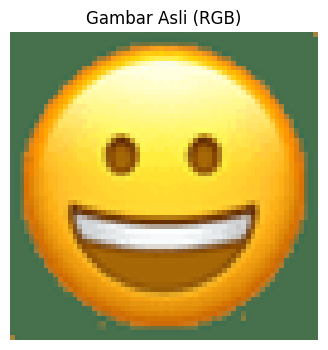

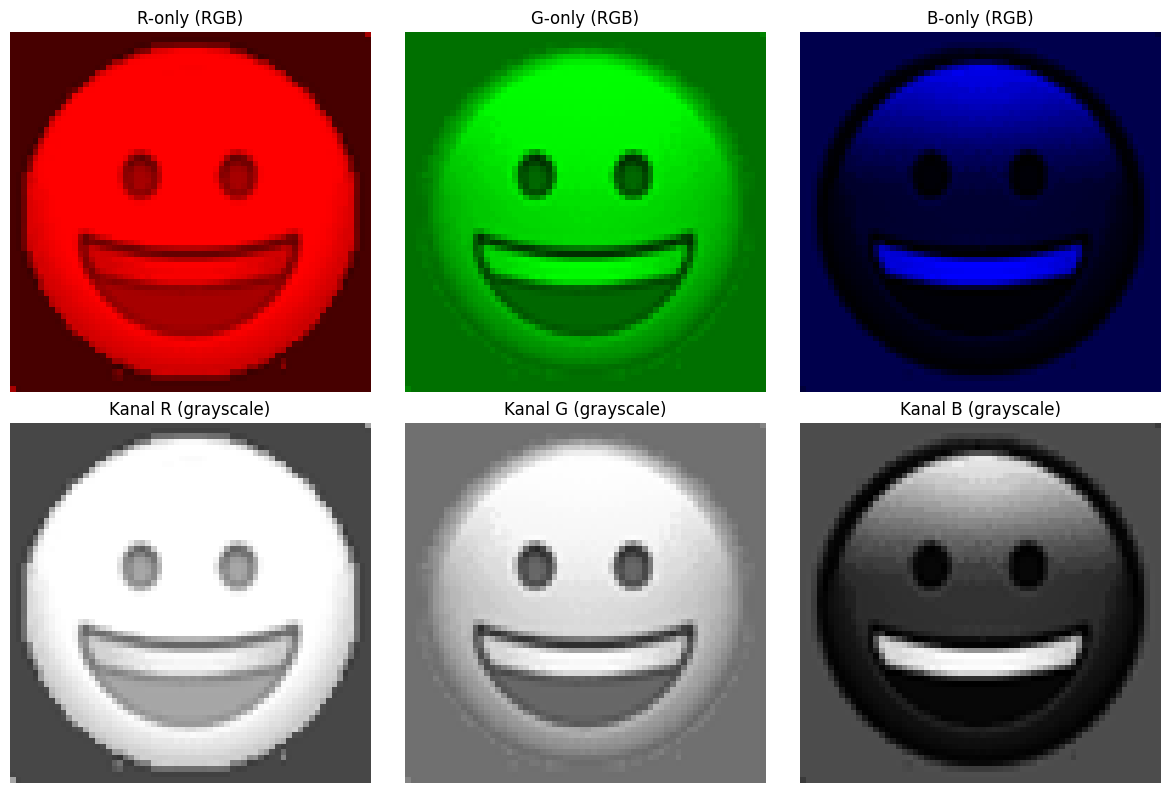

In [ ]:
# Contoh: melihat 1 gambar TRAIN + memecah kanal R, G, B
from emoji_train import X_train, y_train
import matplotlib.pyplot as plt

# --- Pilih indeks gambar yang ingin dilihat ---
INDEX = 0  # ganti sesuai kebutuhan, 0 <= INDEX < len(X_train)

# --- Ambil satu gambar & labelnya ---
# X_train[INDEX] adalah array (H, W, 3) bertipe uint8; kita ubah ke list bersarang agar mudah dipahami
img = X_train[INDEX].tolist()  # ukuran: H x W x 3; setiap piksel = [R, G, B] (0..255)
label = int(y_train[INDEX])    # label integer (1 atau 2)

# --- Informasi dimensi gambar ---
H = len(img)                                  # jumlah baris (tinggi)
W = len(img[0]) if H > 0 else 0               # jumlah kolom (lebar)
C = len(img[0][0]) if (H > 0 and W > 0) else 0  # jumlah kanal (harusnya 3 = R,G,B)

print(f"Index: {INDEX} | Label: {label} | Ukuran: {H}x{W} | Kanal: {C}")

# --- Akses contoh piksel (baris=10, kolom=20; sesuaikan agar masih dalam rentang) ---
y, x = min(10, H-1), min(20, W-1)
Rpx, Gpx, Bpx = img[y][x]  # ini adalah nilai RGB 0..255 pada piksel tersebut
print(f"Contoh piksel di (baris={y}, kolom={x}): R={Rpx}, G={Gpx}, B={Bpx}")

# --- Pecah kanal menjadi 2D (grayscale) ---
# Setiap kanal akan berupa list 2D berukuran H x W berisi angka 0..255
R_plane = [[img[r][c][0] for c in range(W)] for r in range(H)]
G_plane = [[img[r][c][1] for c in range(W)] for r in range(H)]
B_plane = [[img[r][c][2] for c in range(W)] for r in range(H)]

# --- Buat visualisasi berwarna "single-channel" ---
# R-only: salin nilai R ke kanal merah, nolkan G dan B
R_only_color = [[[img[r][c][0], 0, 0] for c in range(W)] for r in range(H)]
# G-only: salin nilai G ke kanal hijau, nolkan R dan B
G_only_color = [[[0, img[r][c][1], 0] for c in range(W)] for r in range(H)]
# B-only: salin nilai B ke kanal biru, nolkan R dan G
B_only_color = [[[0, 0, img[r][c][2]] for c in range(W)] for r in range(H)]


# Jika Anda juga ingin melihat B-only, tampilkan terpisah:
# Gambar asli
plt.figure(figsize=(4, 4))
plt.imshow(img)
plt.axis('off')
plt.title("Gambar Asli (RGB)")
plt.show()

# --- Tampilkan semuanya dalam grid subplot ---
fig, axes = plt.subplots(2, 3, figsize=(12, 8))

# (a) Visualisasi R-only berwarna
axes[0, 0].imshow(R_only_color)
axes[0, 0].set_title("R-only (RGB)")
axes[0, 0].axis("off")

# (b) Visualisasi G-only & B-only
axes[0, 1].imshow(G_only_color)
axes[0, 1].set_title("G-only (RGB)")
axes[0, 1].axis("off")

# (c) Visualisasi B-only
axes[0, 2].imshow(B_only_color)
axes[0, 2].set_title("B-only (RGB)")
axes[0, 2].axis("off")

# (d) Kanal R sebagai grayscale
axes[1, 0].imshow(R_plane, cmap="gray", vmin=0, vmax=255)
axes[1, 0].set_title("Kanal R (grayscale)")
axes[1, 0].axis("off")

# (e) Kanal G sebagai grayscale
axes[1, 1].imshow(G_plane, cmap="gray", vmin=0, vmax=255)
axes[1, 1].set_title("Kanal G (grayscale)")
axes[1, 1].axis("off")

# (f) Kanal B sebagai grayscale
axes[1, 2].imshow(B_plane, cmap="gray", vmin=0, vmax=255)
axes[1, 2].set_title("Kanal B (grayscale)")
axes[1, 2].axis("off")

plt.tight_layout()
plt.show()

## CONTOH Mengakses 1 buah emoji dan menampilkan histogram intensitas untuk tiap-tiap channel (kanal)

Index: 0 | Label: 1 | Ukuran: 64x64 | Kanal: 3


/tmp/ipykernel_728/785755323.py:70: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


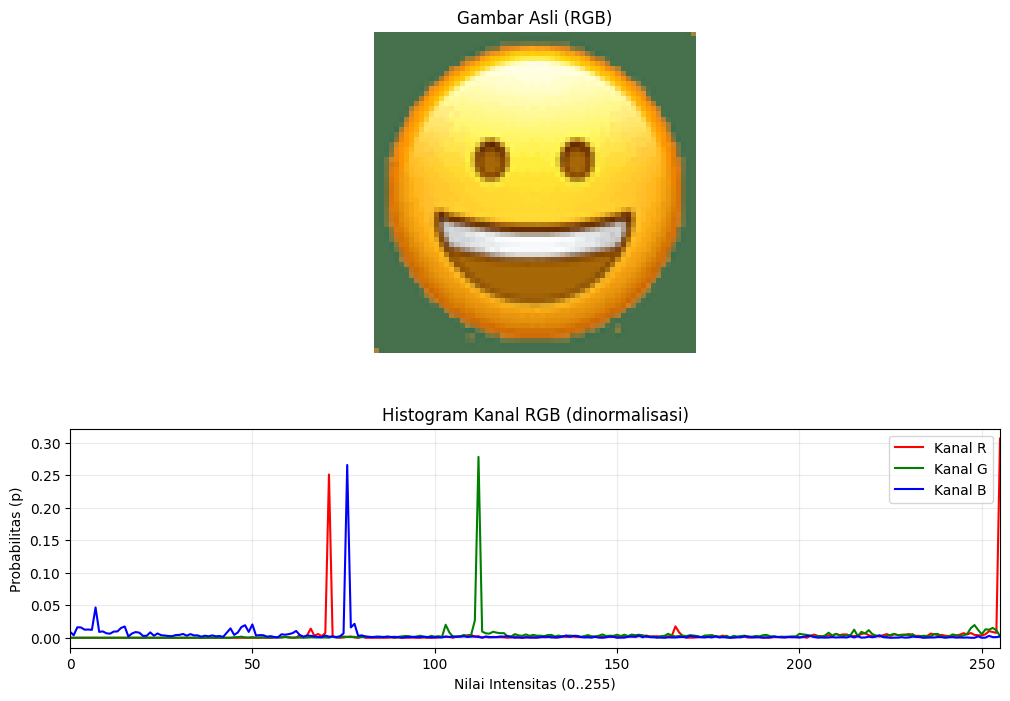

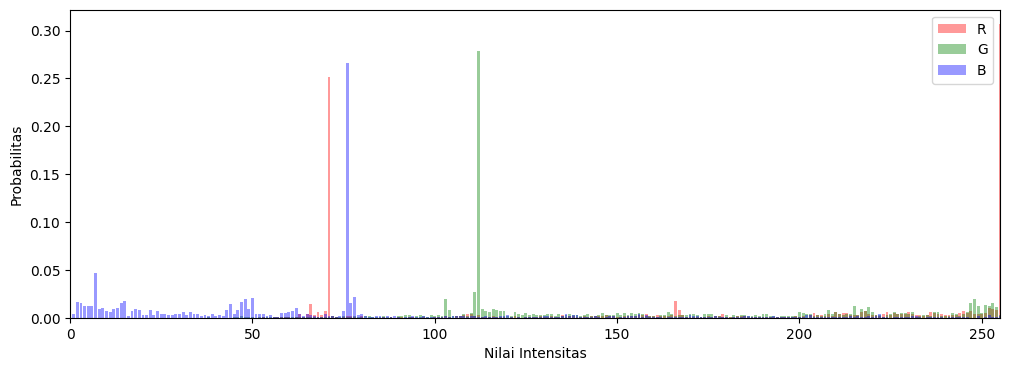

In [ ]:
# Tampilkan 1 emoji + histogram kanal R/G/B dalam satu figur
# - Data gambar diperlakukan sebagai list bersarang: img[baris][kolom] -> [R, G, B] (0..255)
# - Histogram dihitung manual (tanpa NumPy)

from emoji_train import X_train, y_train
import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec

# --- Pilih indeks gambar yang ingin dilihat ---
INDEX = 0  # ubah sesuai kebutuhan (0 <= INDEX < len(X_train))

# Ambil gambar & label; ubah ke list bersarang (HxWx3)
img = X_train[INDEX].tolist()
label = int(y_train[INDEX])

# Info dimensi
H = len(img)
W = len(img[0]) if H > 0 else 0
C = len(img[0][0]) if (H > 0 and W > 0) else 0
print(f"Index: {INDEX} | Label: {label} | Ukuran: {H}x{W} | Kanal: {C}")

# --- Hitung histogram kanal R/G/B (0..255) dengan loop murni ---
def channel_histograms(img_3d):
    """Kembalikan (histR, histG, histB) — masing2 list panjang 256."""
    H = len(img_3d)
    W = len(img_3d[0]) if H > 0 else 0
    histR = [0]*256
    histG = [0]*256
    histB = [0]*256
    for r in range(H):
        row = img_3d[r]
        for c in range(W):
            R, G, B = row[c]  # [R,G,B] 0..255
            histR[int(R)] += 1
            histG[int(G)] += 1
            histB[int(B)] += 1
    return histR, histG, histB

histR, histG, histB = channel_histograms(img)

# (Opsional) Normalisasi ke probabilitas agar skala ketiganya sebanding
total_pixels = H * W if (H > 0 and W > 0) else 1
probR = [h/total_pixels for h in histR]
probG = [h/total_pixels for h in histG]
probB = [h/total_pixels for h in histB]
bins  = list(range(256))  # 0..255

# --- Tata letak figur: atas gambar RGB, bawah satu axes berisi 3 kurva histogram ---
fig = plt.figure(figsize=(12, 8))
gs = GridSpec(nrows=2, ncols=1, height_ratios=[2.2, 1.5], hspace=0.28)

# Atas: gambar asli
ax_img = fig.add_subplot(gs[0, 0])
ax_img.imshow(img)
ax_img.set_title("Gambar Asli (RGB)")
ax_img.axis("off")

# Bawah: histogram kanal R/G/B (dioverlay)
ax_hist = fig.add_subplot(gs[1, 0])
ax_hist.plot(bins, probR, label="Kanal R", color="red")
ax_hist.plot(bins, probG, label="Kanal G", color="green")
ax_hist.plot(bins, probB, label="Kanal B", color="blue")
ax_hist.set_xlim(0, 255)
ax_hist.set_xlabel("Nilai Intensitas (0..255)")
ax_hist.set_ylabel("Probabilitas (p)")
ax_hist.set_title("Histogram Kanal RGB (dinormalisasi)")
ax_hist.grid(alpha=0.25)
ax_hist.legend()

plt.tight_layout()
plt.show()

# (Opsional) Jika ingin versi 'bar' (batang) bukan garis — hati-hati bisa padat:
plt.figure(figsize=(12,4))
plt.bar(bins, probR, color="red", alpha=0.4, label="R")
plt.bar(bins, probG, color="green", alpha=0.4, label="G")
plt.bar(bins, probB, color="blue", alpha=0.4, label="B")
plt.xlim(0, 255); plt.xlabel("Nilai Intensitas"); plt.ylabel("Probabilitas"); plt.legend(); plt.show()

<font color="red"><h2>TUGAS ANDA</h2></font>

Lengkapilah fungsi ini untuk memprediksi apakah sebuah gambar emoji termasuk ke dalam kelas *Faces* (kelas = 1) atau *Flags* (kelas = 2).

In [ ]:
import numpy as np


def compute_roundness_from_image(img, bg_color=[71, 112, 76]):
    """Computes scale-invariant roundness by masking out the specific green background."""
    # Convert input to numpy array if passed as a list
    if not isinstance(img, np.ndarray):
        img = np.array(img)

    # Convert normalized float image (0-1) to standard 0-255 RGB if needed
    if img.dtype != np.uint8 and img.max() <= 1.0:
        img_rgb = (img * 255).astype(np.uint8)
    else:
        img_rgb = img.astype(np.uint8)

    # Target background color array
    target_bg = np.array(bg_color, dtype=float)

    # Calculate Euclidean color distance from the green background
    color_diff = np.linalg.norm(
        img_rgb[..., :3].astype(float) - target_bg, axis=-1
    )

    # Foreground is everything distinct from the background color
    binary_mask = color_diff > 30.0

    # 1. Area
    area = np.sum(binary_mask)
    if area == 0:
        return {"Roundness_Perimeter": 0.0, "Roundness_Axis": 0.0}

    # 2. Get boundary points
    boundary = get_boundary_from_mask(binary_mask)
    if len(boundary) == 0:
        return {"Roundness_Perimeter": 0.0, "Roundness_Axis": 0.0}

    # 3. Major Axis via maximum pairwise boundary distance
    diffs = boundary[:, np.newaxis, :] - boundary[np.newaxis, :, :]
    dist_matrix = np.sqrt(np.sum(diffs**2, axis=-1))
    major_axis = np.max(dist_matrix)

    # 4. Perimeter
    perimeter = len(boundary)

    # Roundness calculations
    roundness_perimeter = (4 * np.pi * area) / (perimeter**2)
    roundness_axis = (4 * area) / (np.pi * (major_axis**2))

    return {
        "Area": area,
        "Perimeter": perimeter,
        "Major_Axis": major_axis,
        "Roundness_Perimeter": roundness_perimeter,
        "Roundness_Axis": roundness_axis,
    }

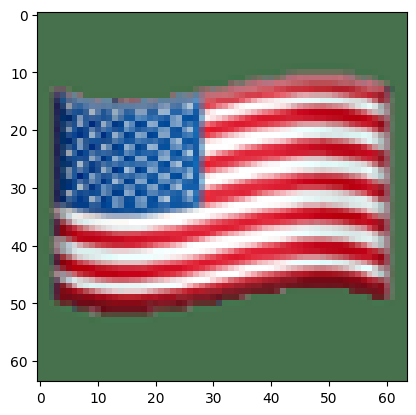

2

In [ ]:
def prediksi_gambar_img(img):
    imgans = compute_roundness_from_image(img)
    if hasattr(img, "tolist"):
        img = img.tolist()

    # Validasi bentuk data dasar
    H = len(img)
    W = len(img[0]) if H > 0 else 0
    C = len(img[0][0]) if (H > 0 and W > 0) else 0
    if H == 0 or W == 0 or C != 3:
        raise ValueError(f"Bentuk gambar tidak valid. Ditemukan: H={H}, W={W}, C={C} (harus HxWx3)")

    histR, histG, histB = channel_histograms(img)
    scoreR, scoreG, scoreB = 0,0,0
    for i in range(256):
      scoreR+=histR[i]*i
      scoreG+=histG[i]*i
      scoreB+=histB[i]*i
    # print(histR, histG, histB)
    # print(scoreR, scoreG, scoreB)
    probR = scoreR/(255*255)
    probG = scoreG/(255*255)
    probB = scoreB/(255*255)
    # print(probR, probG, probB)

    if imgans["Roundness_Axis"] > 0.5 and imgans["Roundness_Axis"] < 0.7:
      pred_label = 2
    else:
      pred_label =1
    # if probR*probG > 100:
    #   pred_label = 1 #udah fix dia emoji kuning
    # else:
    #   if probR*probG/probB <=11:
    #     if probR*probG/probB <= 4:
    #       pred_label = 1
    #     else:
    #       pred_label = 2
    #   else:
    #     pred_label = 1
    # print("prediction:", pred_label)


    # -------------------- KODE ANDA SELESAI DI SINI ------------------

    # Validasi & kembalikan label
    try:
        pred_label
    except NameError:
        raise RuntimeError("Anda belum menetapkan variabel 'pred_label' di blok KODE ANDA.")

    if pred_label not in (1, 2):
        raise ValueError("pred_label harus bernilai 1 atau 2.")

    return int(pred_label)

ans = prediksi_gambar_img(X_train[140])
plt.imshow(X_train[140])
plt.show()
ans

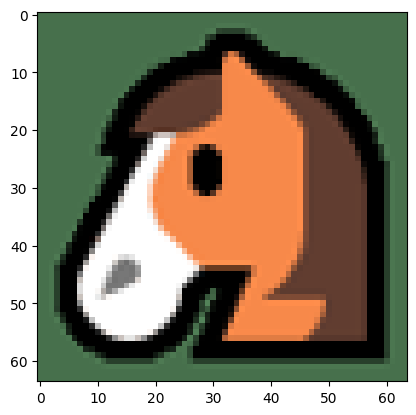

1

In [ ]:
ans = prediksi_gambar_img(X_test[165])
plt.imshow(X_test[165])
plt.show()
ans

In [ ]:
compute_roundness_from_image(X_test[165])

{'Area': np.int64(2666),
 'Perimeter': 204,
 'Major_Axis': np.float64(64.03124237432849),
 'Roundness_Perimeter': np.float64(0.8050255684804295),
 'Roundness_Axis': np.float64(0.827916250308279)}

In [ ]:
compute_roundness_from_image(X_test[140])

{'Area': np.int64(2193),
 'Perimeter': 187,
 'Major_Axis': np.float64(67.95586803212802),
 'Roundness_Perimeter': np.float64(0.7880708844201911),
 'Roundness_Axis': np.float64(0.6046371419671313)}

array([[[ 71, 112,  76],
        [ 71, 112,  76],
        [ 71, 112,  76],
        ...,
        [ 71, 112,  76],
        [ 71, 112,  76],
        [ 71, 112,  76]],

       [[ 71, 112,  76],
        [ 71, 112,  76],
        [ 71, 112,  76],
        ...,
        [ 71, 112,  76],
        [ 71, 112,  76],
        [ 71, 112,  76]],

       [[ 71, 112,  76],
        [ 71, 112,  76],
        [ 71, 112,  76],
        ...,
        [ 71, 112,  76],
        [ 71, 112,  76],
        [ 71, 112,  76]],

       ...,

       [[ 71, 112,  76],
        [ 71, 112,  76],
        [ 71, 112,  76],
        ...,
        [ 71, 112,  76],
        [ 71, 112,  76],
        [ 71, 112,  76]],

       [[ 71, 112,  76],
        [ 71, 112,  76],
        [ 71, 112,  76],
        ...,
        [ 71, 112,  76],
        [ 71, 112,  76],
        [ 71, 112,  76]],

       [[ 71, 112,  76],
        [ 71, 112,  76],
        [ 71, 112,  76],
        ...,
        [ 71, 112,  76],
        [ 71, 112,  76],
        [ 71, 112,  76]]], dtype=uint8)
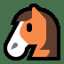

In [ ]:
X_test[165]

array([[[ 71, 112,  76],
        [ 71, 112,  76],
        [ 71, 112,  76],
        ...,
        [ 71, 112,  76],
        [ 71, 112,  76],
        [ 71, 112,  76]],

       [[ 71, 112,  76],
        [ 71, 112,  76],
        [ 71, 112,  76],
        ...,
        [ 71, 112,  76],
        [ 71, 112,  76],
        [ 71, 112,  76]],

       [[ 71, 112,  76],
        [ 71, 112,  76],
        [ 71, 112,  76],
        ...,
        [ 71, 112,  76],
        [ 71, 112,  76],
        [ 71, 112,  76]],

       ...,

       [[ 71, 112,  76],
        [ 71, 112,  76],
        [ 71, 112,  76],
        ...,
        [ 71, 112,  76],
        [ 71, 112,  76],
        [ 71, 112,  76]],

       [[ 71, 112,  76],
        [ 71, 112,  76],
        [ 71, 112,  76],
        ...,
        [ 71, 112,  76],
        [ 71, 112,  76],
        [ 71, 112,  76]],

       [[ 71, 112,  76],
        [ 71, 112,  76],
        [ 71, 112,  76],
        ...,
        [ 71, 112,  76],
        [ 71, 112,  76],
        [ 71, 112,  76]]], dtype=uint8)
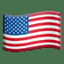

In [ ]:
X_train[140]

In [ ]:
compute_roundness_from_image(X_train[159])

{'Area': np.int64(2112),
 'Perimeter': 300,
 'Major_Axis': np.float64(67.4166151627327),
 'Roundness_Perimeter': np.float64(0.2948908304169619),
 'Roundness_Axis': np.float64(0.5916571877845245)}

array([[[ 71, 112,  76],
        [ 71, 112,  76],
        [ 71, 112,  76],
        ...,
        [ 71, 112,  76],
        [ 71, 112,  76],
        [ 71, 112,  76]],

       [[ 71, 112,  76],
        [ 71, 112,  76],
        [ 71, 112,  76],
        ...,
        [ 71, 112,  76],
        [ 71, 112,  76],
        [ 71, 112,  76]],

       [[ 71, 112,  76],
        [ 71, 112,  76],
        [ 71, 112,  76],
        ...,
        [ 71, 112,  76],
        [ 71, 112,  76],
        [ 71, 112,  76]],

       ...,

       [[ 71, 112,  76],
        [ 71, 112,  76],
        [ 71, 112,  76],
        ...,
        [ 71, 112,  76],
        [ 71, 112,  76],
        [ 71, 112,  76]],

       [[ 71, 112,  76],
        [ 71, 112,  76],
        [ 71, 112,  76],
        ...,
        [ 71, 112,  76],
        [ 71, 112,  76],
        [ 71, 112,  76]],

       [[ 71, 112,  76],
        [ 71, 112,  76],
        [ 71, 112,  76],
        ...,
        [ 71, 112,  76],
        [ 71, 112,  76],
        [ 71, 112,  76]]], dtype=uint8)
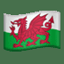

In [ ]:
X_train[159]

array([[[ 71, 112,  76],
        [ 71, 112,  76],
        [ 71, 112,  76],
        ...,
        [ 71, 112,  76],
        [ 71, 112,  76],
        [ 71, 112,  76]],

       [[ 71, 112,  76],
        [ 71, 112,  76],
        [ 71, 112,  76],
        ...,
        [ 71, 112,  76],
        [ 71, 112,  76],
        [ 71, 112,  76]],

       [[ 71, 112,  76],
        [ 71, 112,  76],
        [ 71, 112,  76],
        ...,
        [ 71, 112,  76],
        [ 71, 112,  76],
        [ 71, 112,  76]],

       ...,

       [[ 71, 112,  76],
        [ 71, 112,  76],
        [ 71, 112,  76],
        ...,
        [ 71, 112,  76],
        [ 71, 112,  76],
        [ 71, 112,  76]],

       [[ 71, 112,  76],
        [ 71, 112,  76],
        [ 71, 112,  76],
        ...,
        [ 71, 112,  76],
        [ 71, 112,  76],
        [ 71, 112,  76]],

       [[ 71, 112,  76],
        [ 71, 112,  76],
        [ 71, 112,  76],
        ...,
        [ 71, 112,  76],
        [ 71, 112,  76],
        [ 71, 112,  76]]], dtype=uint8)
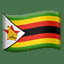

In [ ]:
X_train[156]

In [ ]:
compute_roundness_from_image(X_train[156])

{'Area': np.int64(2212),
 'Perimeter': 192,
 'Major_Axis': np.float64(68.26419266350405),
 'Roundness_Perimeter': np.float64(0.7540367784006752),
 'Roundness_Axis': np.float64(0.60437894269403)}

[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 13, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 1, 12, 1, 4, 3, 3, 11, 29, 6, 10, 8, 5, 5, 1, 3, 9, 10, 7, 11, 11, 10, 6, 9, 6, 6, 7, 9, 7, 2, 6, 15, 3, 5, 3, 5, 10, 20, 30, 33, 121, 33, 1630, 51, 8, 4, 0, 1, 3, 3, 2, 2, 2, 4, 16, 5, 6, 36, 22, 3, 5, 9, 5, 4, 16, 10, 1, 5, 1, 1, 5, 5, 1, 1, 2, 6, 1, 3, 2, 3, 5, 10, 13, 7, 9, 6, 4, 3, 5, 3, 6, 8, 7, 8, 4, 8, 5, 6, 8, 1, 17, 7, 7, 6, 2, 2, 4, 5, 2, 2, 5, 53, 6, 1, 3, 3, 3, 1, 3, 1, 2, 0, 2, 6, 0, 3, 2, 0, 0, 1, 3, 4, 3, 2, 3, 2, 11, 34, 2, 1, 3, 3, 18, 0, 3, 1, 2, 1, 2, 9, 4, 3, 1, 2, 0, 2, 4, 4, 2, 1, 4, 0, 1, 6, 34, 3, 7, 23, 10, 5, 79, 26, 27, 17, 80, 12, 5, 7, 15, 22, 62, 35, 10, 7, 8, 42, 54, 38, 4, 3, 6, 4, 42, 9, 30, 12, 3, 9, 40, 8, 23, 20, 49, 16, 14, 30, 57, 14, 26, 16, 28, 159, 7, 1, 2, 1, 1, 0, 3, 1, 0, 1, 2, 4, 1, 10, 1] [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 4, 1, 5, 2, 3, 1, 10, 54, 7, 4, 5, 9, 29, 49, 103, 18, 32, 29, 83, 12, 15, 15, 31, 125, 12, 1

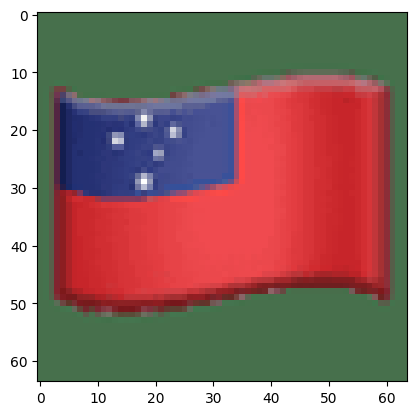

2

In [ ]:
index = 150
ans = prediksi_gambar_img(X_train[index])
plt.imshow(X_train[index])
plt.show()
ans

<h2>Melakukan Prediksi Pada Data Latih</h2>

Jawaban Anda akan dinilai sebagian terhadap data latih yang terdiri dari 160 gambar emoji. Data latih ini bisa digunakan untuk menentukan ekstraksi fitur pada gambar emoji dan membuat aturan untuk memprediksi apakah sebuah gambar termasuk emoji *Faces* atau *Flags*. Ekstraksi fitur dan aturan prediksi untuk sebuah gambar bisa diimplementasikan di fungsi `prediksi_gambar_img` (*cell* sebelum ini).


**Catatan:**
1. **Anda tidak perlu mengubah bagian kode di bawah ini, selama Anda mengimplementasikan fungsi** `prediksi_gambar_img` **di atas.** Kode di bawah ini akan otomatis berjalan dengan baik selama Anda mengimplementasikan fungsi `prediksi_gambar_img`.

[TRAIN] idx=0 | size=64x64 | channels=3 | label=1 | prediksi=1


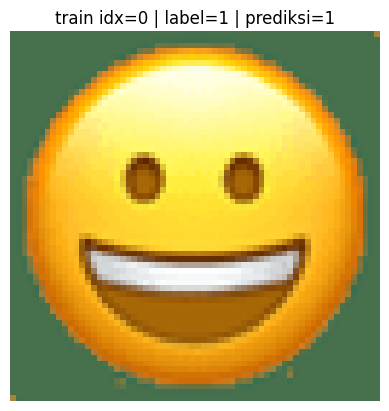

[TRAIN] idx=1 | size=64x64 | channels=3 | label=1 | prediksi=1


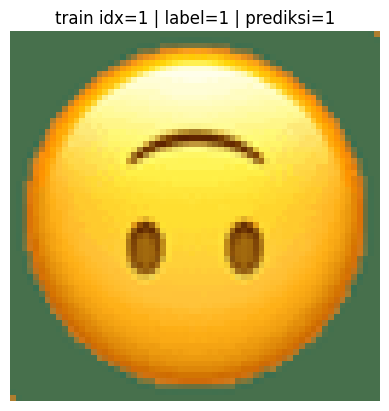

[TRAIN] idx=2 | size=64x64 | channels=3 | label=1 | prediksi=1


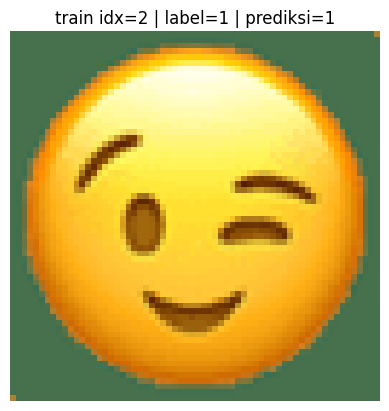

[TRAIN] idx=3 | size=64x64 | channels=3 | label=1 | prediksi=1


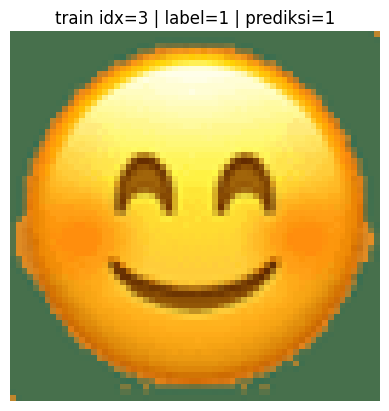

[TRAIN] idx=4 | size=64x64 | channels=3 | label=1 | prediksi=2


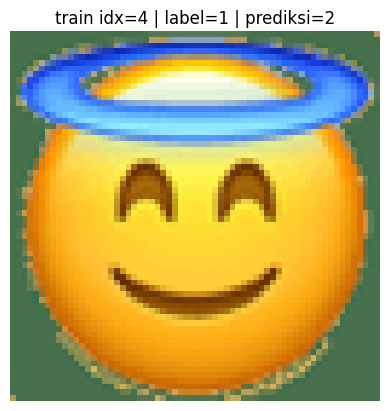

[TRAIN] idx=5 | size=64x64 | channels=3 | label=1 | prediksi=1


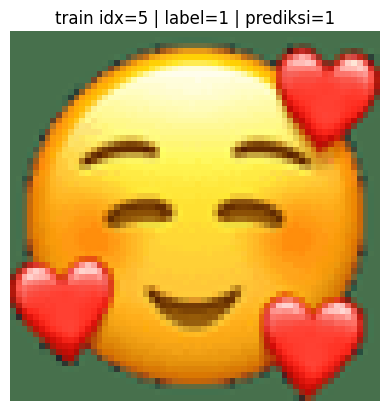

[TRAIN] idx=6 | size=64x64 | channels=3 | label=1 | prediksi=1


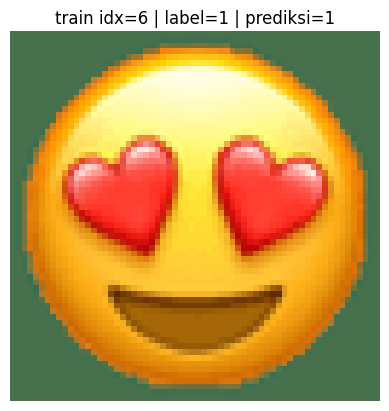

[TRAIN] idx=7 | size=64x64 | channels=3 | label=1 | prediksi=1


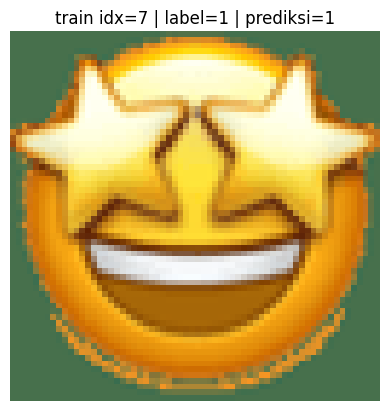

[TRAIN] idx=8 | size=64x64 | channels=3 | label=1 | prediksi=1


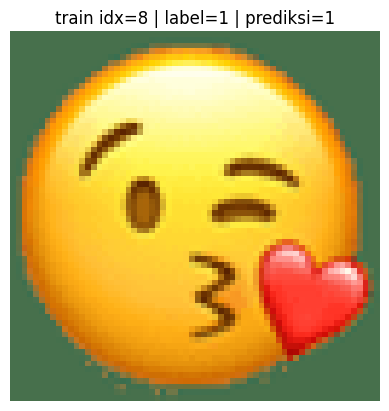

[TRAIN] idx=9 | size=64x64 | channels=3 | label=1 | prediksi=1


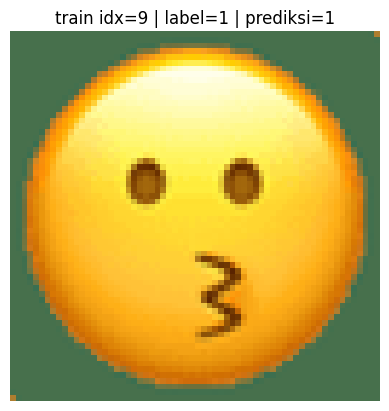

[TRAIN] idx=10 | size=64x64 | channels=3 | label=1 | prediksi=1


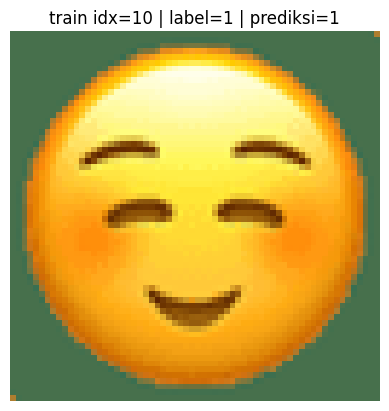

[TRAIN] idx=11 | size=64x64 | channels=3 | label=1 | prediksi=1


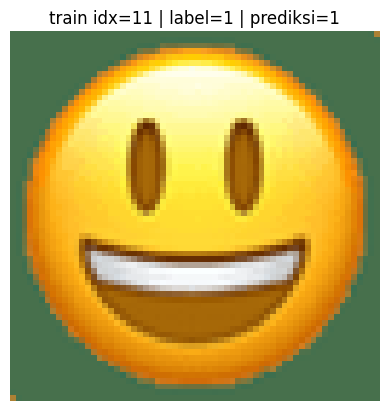

[TRAIN] idx=12 | size=64x64 | channels=3 | label=1 | prediksi=1


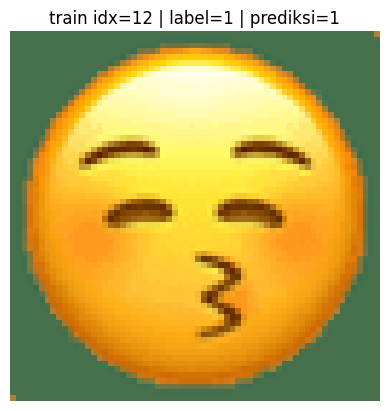

[TRAIN] idx=13 | size=64x64 | channels=3 | label=1 | prediksi=1


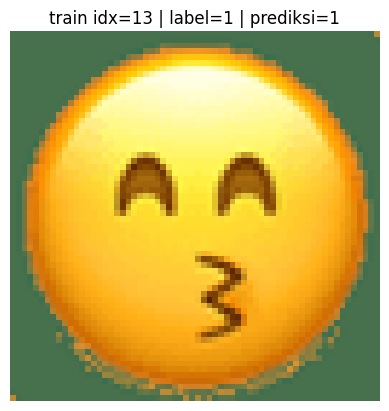

[TRAIN] idx=14 | size=64x64 | channels=3 | label=1 | prediksi=1


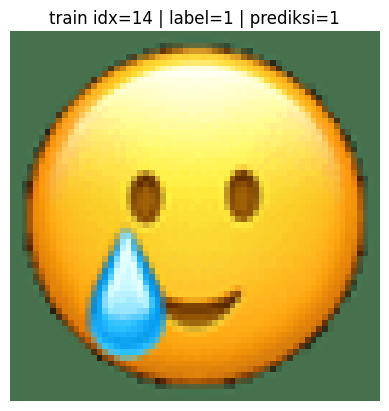

[TRAIN] idx=15 | size=64x64 | channels=3 | label=1 | prediksi=1


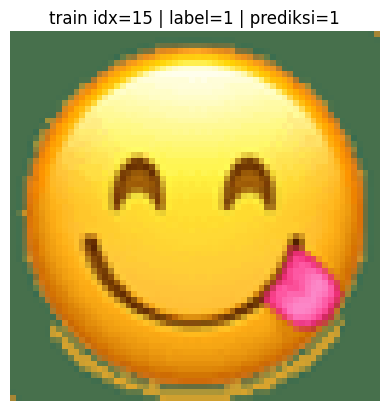

[TRAIN] idx=16 | size=64x64 | channels=3 | label=1 | prediksi=1


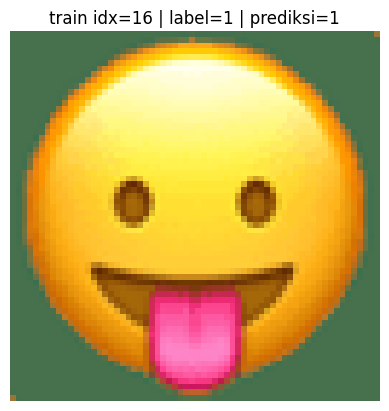

[TRAIN] idx=17 | size=64x64 | channels=3 | label=1 | prediksi=1


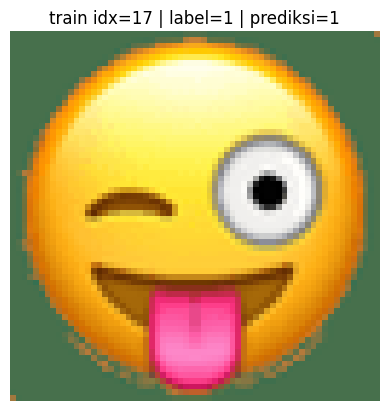

[TRAIN] idx=18 | size=64x64 | channels=3 | label=1 | prediksi=1


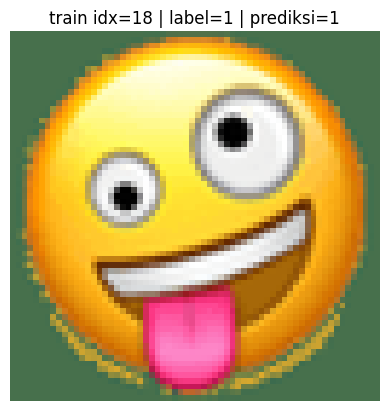

[TRAIN] idx=19 | size=64x64 | channels=3 | label=1 | prediksi=1


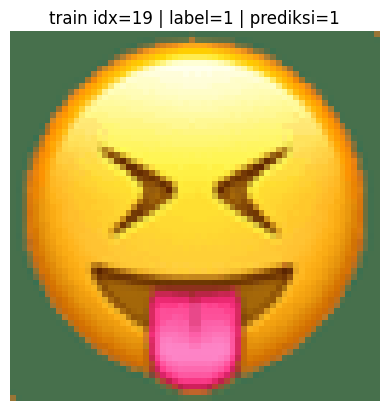

[TRAIN] idx=20 | size=64x64 | channels=3 | label=1 | prediksi=1


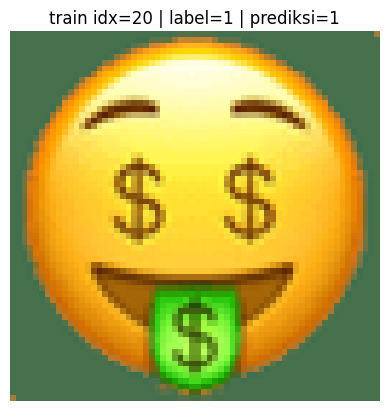

[TRAIN] idx=21 | size=64x64 | channels=3 | label=1 | prediksi=2


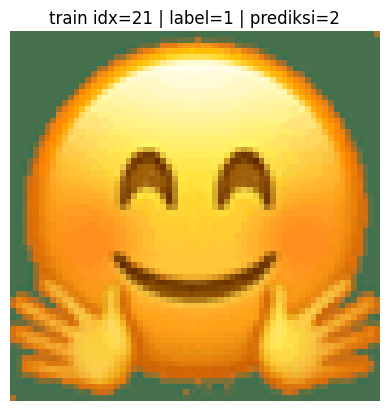

[TRAIN] idx=22 | size=64x64 | channels=3 | label=1 | prediksi=1


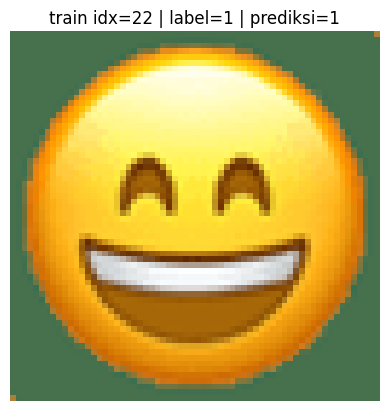

[TRAIN] idx=23 | size=64x64 | channels=3 | label=1 | prediksi=1


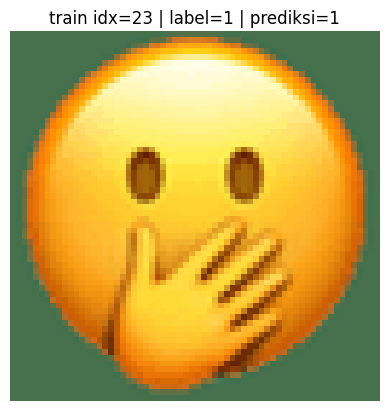

[TRAIN] idx=24 | size=64x64 | channels=3 | label=1 | prediksi=1


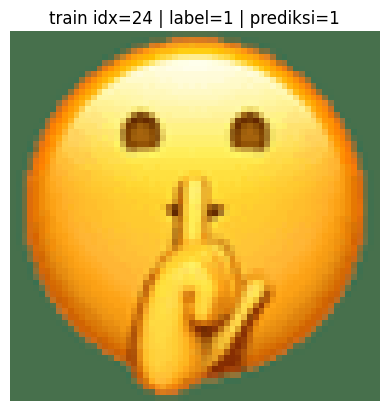

[TRAIN] idx=25 | size=64x64 | channels=3 | label=1 | prediksi=1


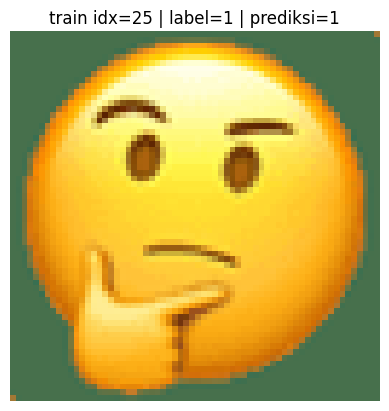

[TRAIN] idx=26 | size=64x64 | channels=3 | label=1 | prediksi=1


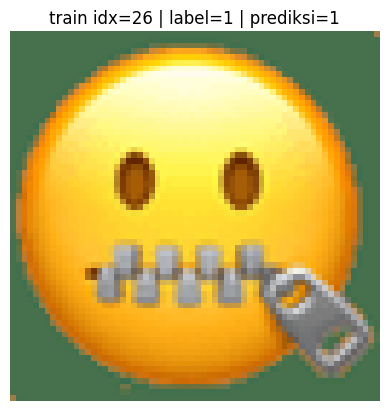

[TRAIN] idx=27 | size=64x64 | channels=3 | label=1 | prediksi=1


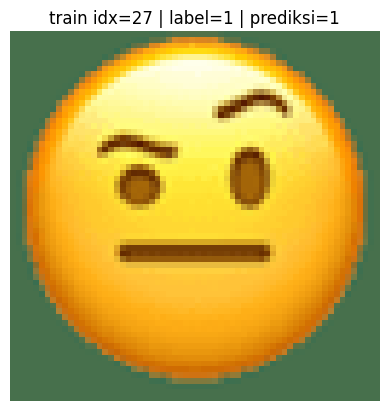

[TRAIN] idx=28 | size=64x64 | channels=3 | label=1 | prediksi=1


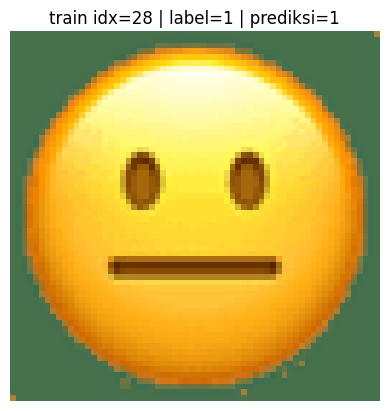

[TRAIN] idx=29 | size=64x64 | channels=3 | label=1 | prediksi=1


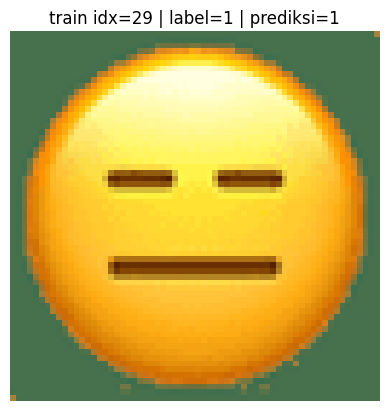

[TRAIN] idx=30 | size=64x64 | channels=3 | label=1 | prediksi=1


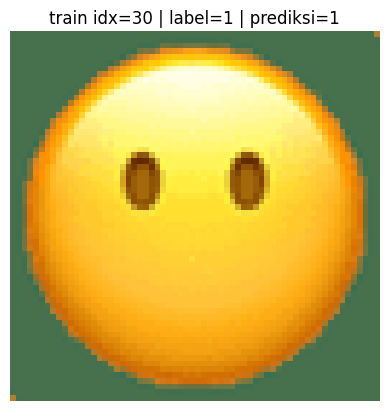

[TRAIN] idx=31 | size=64x64 | channels=3 | label=1 | prediksi=2


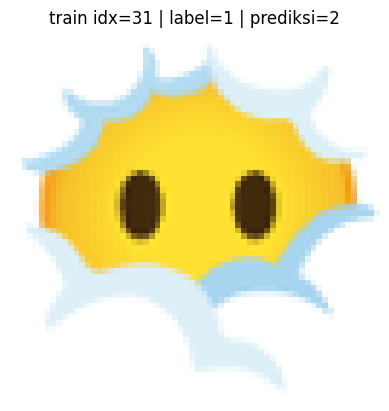

[TRAIN] idx=32 | size=64x64 | channels=3 | label=1 | prediksi=1


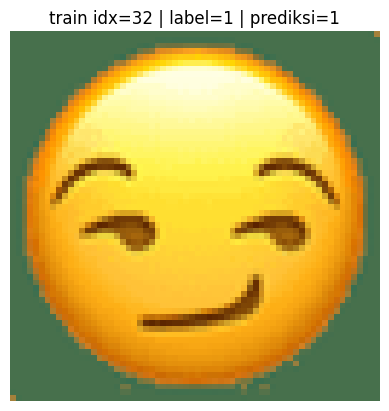

[TRAIN] idx=33 | size=64x64 | channels=3 | label=1 | prediksi=1


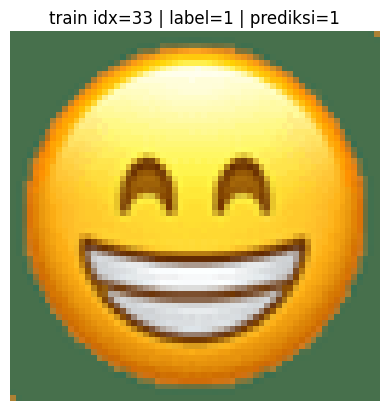

[TRAIN] idx=34 | size=64x64 | channels=3 | label=1 | prediksi=1


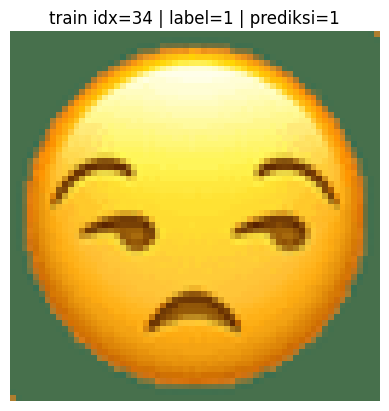

[TRAIN] idx=35 | size=64x64 | channels=3 | label=1 | prediksi=1


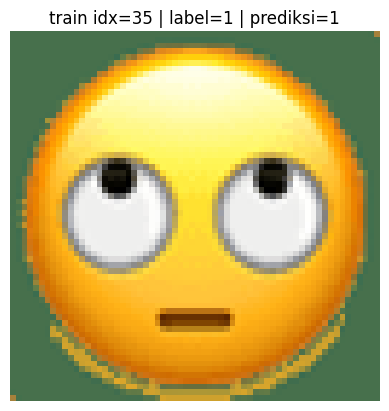

[TRAIN] idx=36 | size=64x64 | channels=3 | label=1 | prediksi=1


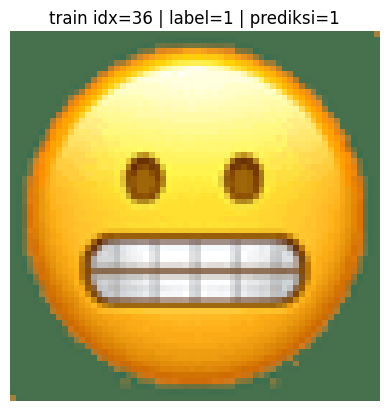

[TRAIN] idx=37 | size=64x64 | channels=3 | label=1 | prediksi=2


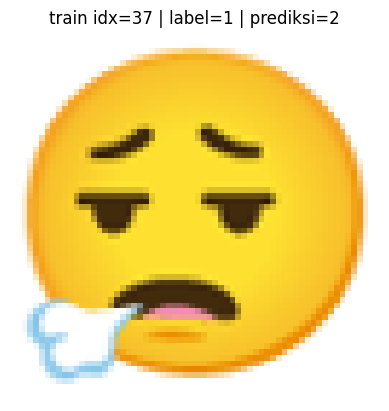

[TRAIN] idx=38 | size=64x64 | channels=3 | label=1 | prediksi=1


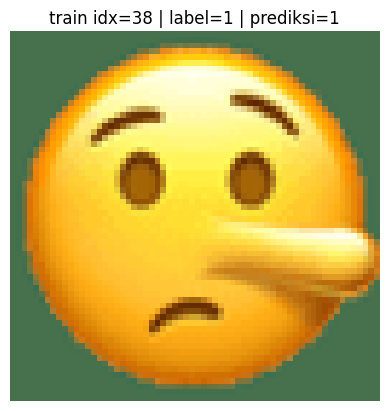

[TRAIN] idx=39 | size=64x64 | channels=3 | label=1 | prediksi=1


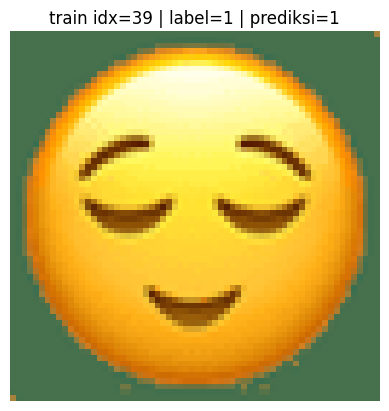

[TRAIN] idx=40 | size=64x64 | channels=3 | label=1 | prediksi=1


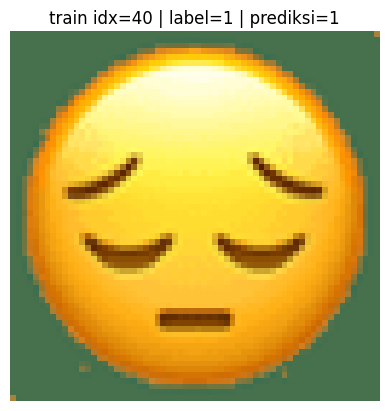

[TRAIN] idx=41 | size=64x64 | channels=3 | label=1 | prediksi=1


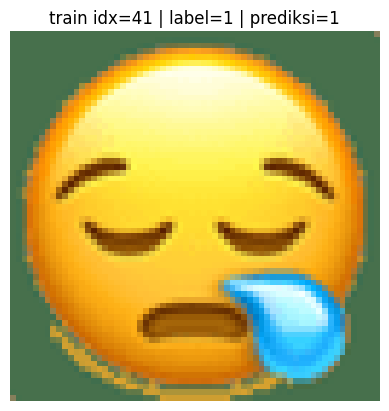

[TRAIN] idx=42 | size=64x64 | channels=3 | label=1 | prediksi=1


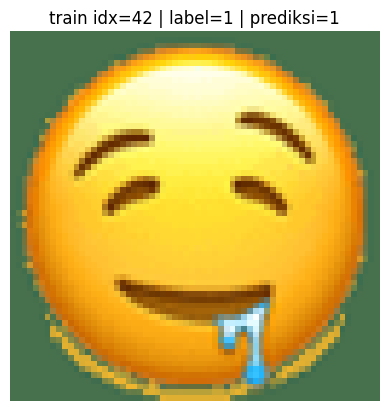

[TRAIN] idx=43 | size=64x64 | channels=3 | label=1 | prediksi=1


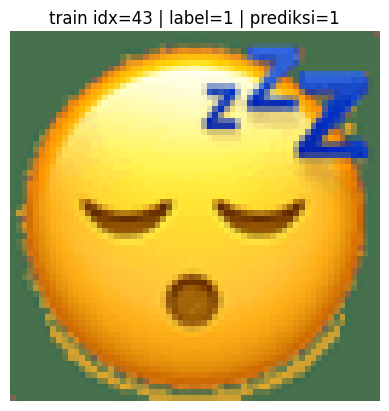

[TRAIN] idx=44 | size=64x64 | channels=3 | label=1 | prediksi=1


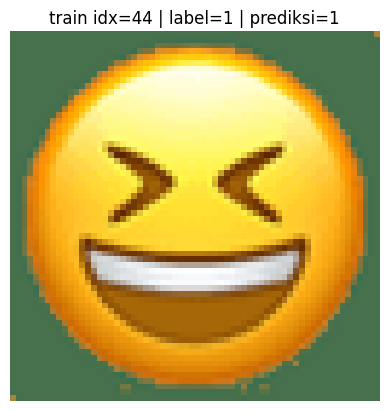

[TRAIN] idx=45 | size=64x64 | channels=3 | label=1 | prediksi=1


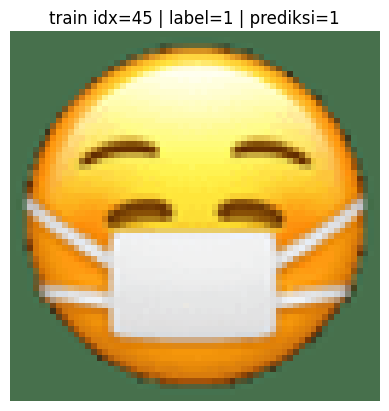

[TRAIN] idx=46 | size=64x64 | channels=3 | label=1 | prediksi=1


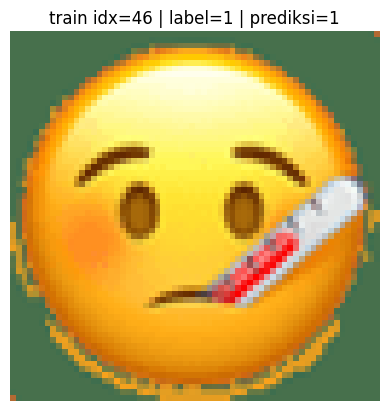

[TRAIN] idx=47 | size=64x64 | channels=3 | label=1 | prediksi=1


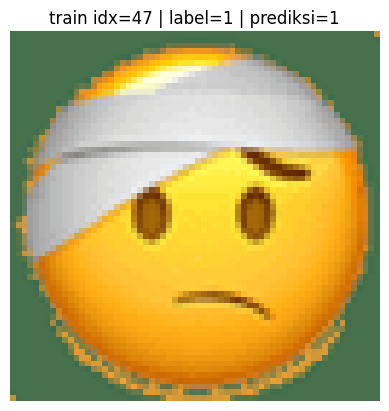

[TRAIN] idx=48 | size=64x64 | channels=3 | label=1 | prediksi=1


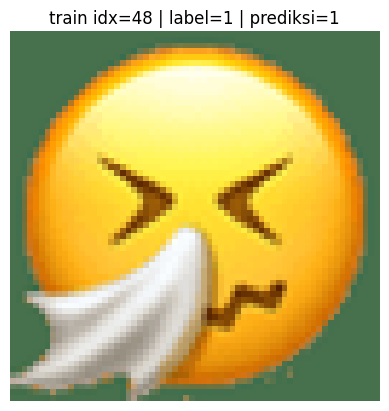

[TRAIN] idx=49 | size=64x64 | channels=3 | label=1 | prediksi=1


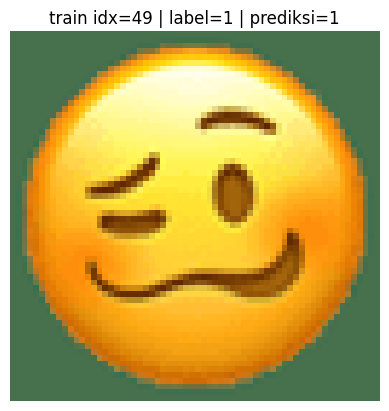

[TRAIN] idx=50 | size=64x64 | channels=3 | label=1 | prediksi=1


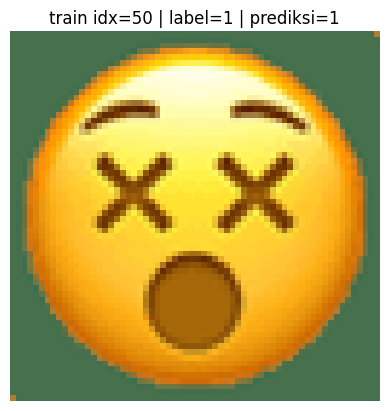

[TRAIN] idx=51 | size=64x64 | channels=3 | label=1 | prediksi=1


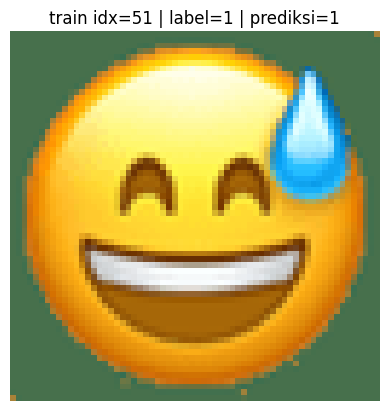

[TRAIN] idx=52 | size=64x64 | channels=3 | label=1 | prediksi=2


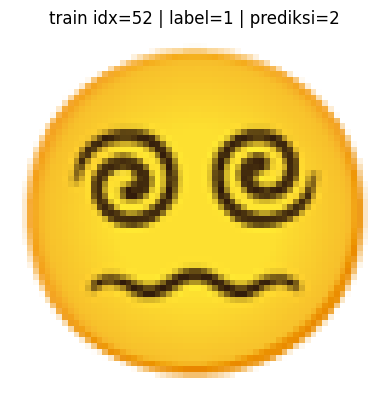

[TRAIN] idx=53 | size=64x64 | channels=3 | label=1 | prediksi=1


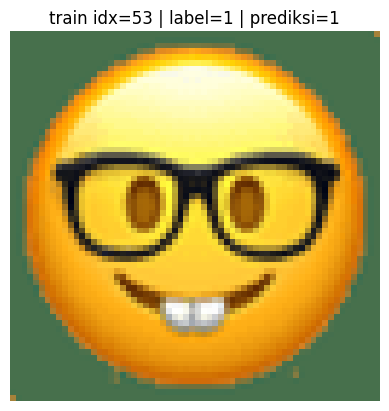

[TRAIN] idx=54 | size=64x64 | channels=3 | label=1 | prediksi=1


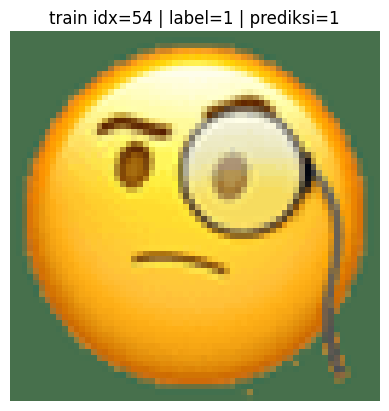

[TRAIN] idx=55 | size=64x64 | channels=3 | label=1 | prediksi=1


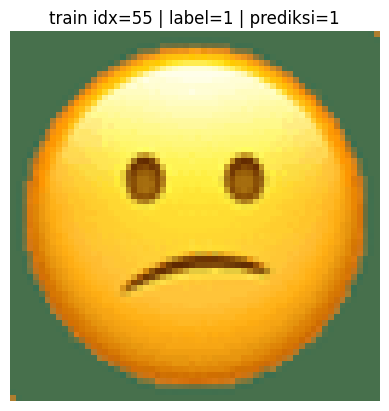

[TRAIN] idx=56 | size=64x64 | channels=3 | label=1 | prediksi=1


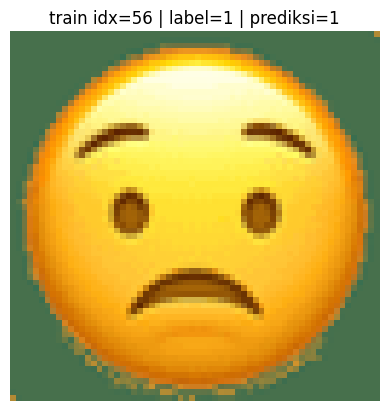

[TRAIN] idx=57 | size=64x64 | channels=3 | label=1 | prediksi=1


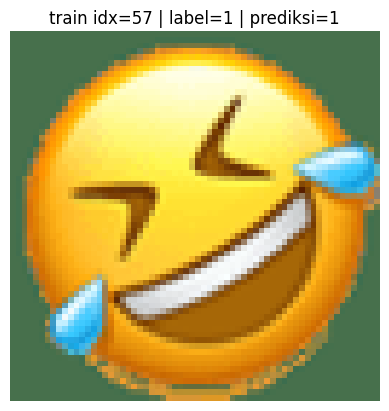

[TRAIN] idx=58 | size=64x64 | channels=3 | label=1 | prediksi=1


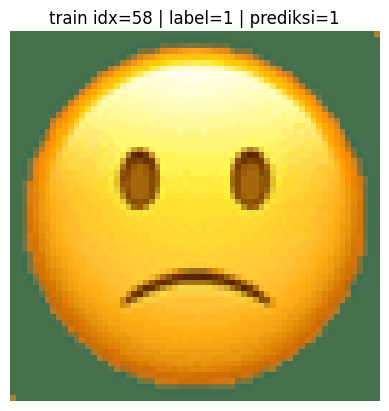

[TRAIN] idx=59 | size=64x64 | channels=3 | label=1 | prediksi=1


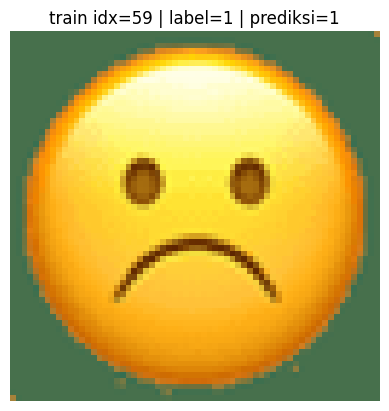

[TRAIN] idx=60 | size=64x64 | channels=3 | label=1 | prediksi=1


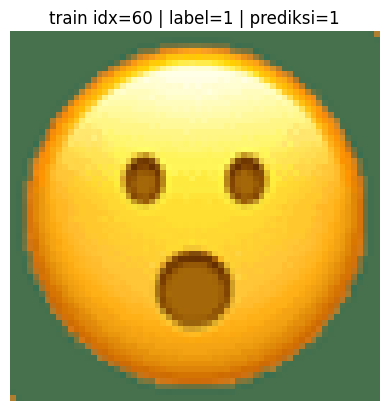

[TRAIN] idx=61 | size=64x64 | channels=3 | label=1 | prediksi=1


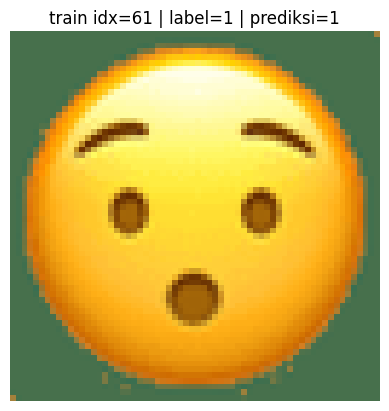

[TRAIN] idx=62 | size=64x64 | channels=3 | label=1 | prediksi=1


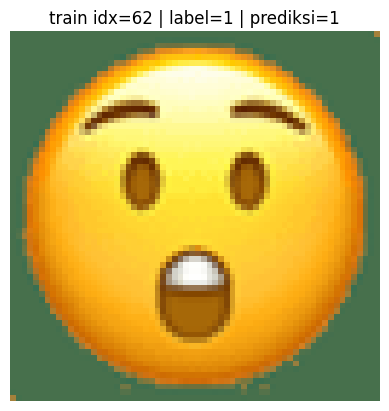

[TRAIN] idx=63 | size=64x64 | channels=3 | label=1 | prediksi=1


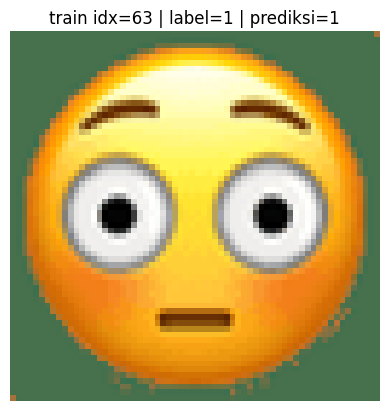

[TRAIN] idx=64 | size=64x64 | channels=3 | label=1 | prediksi=1


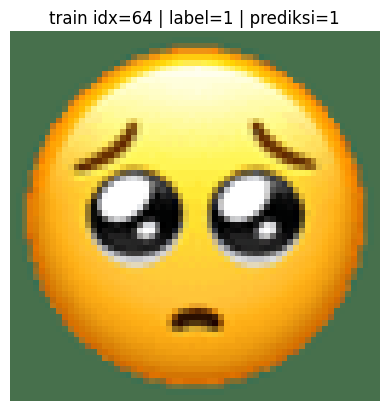

[TRAIN] idx=65 | size=64x64 | channels=3 | label=1 | prediksi=1


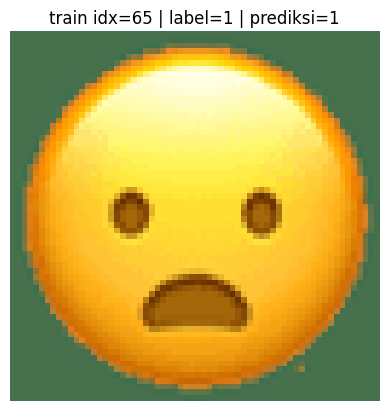

[TRAIN] idx=66 | size=64x64 | channels=3 | label=1 | prediksi=1


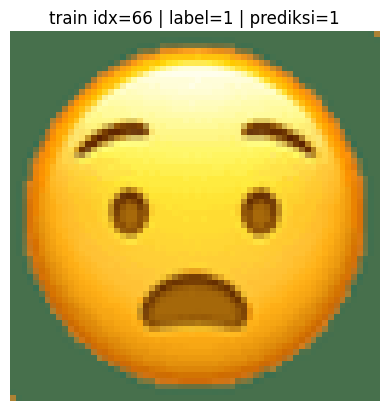

[TRAIN] idx=67 | size=64x64 | channels=3 | label=1 | prediksi=1


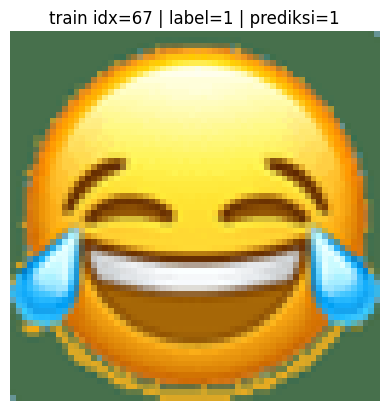

[TRAIN] idx=68 | size=64x64 | channels=3 | label=1 | prediksi=1


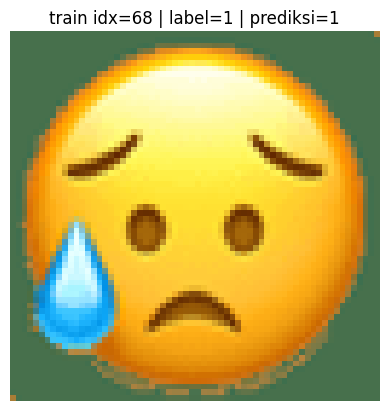

[TRAIN] idx=69 | size=64x64 | channels=3 | label=1 | prediksi=1


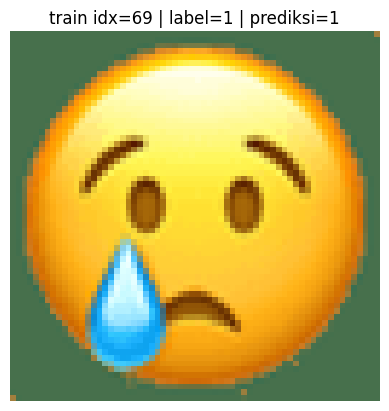

[TRAIN] idx=70 | size=64x64 | channels=3 | label=1 | prediksi=1


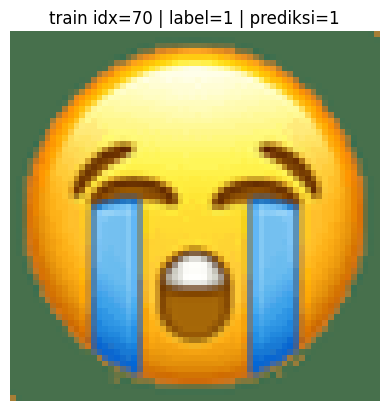

[TRAIN] idx=71 | size=64x64 | channels=3 | label=1 | prediksi=1


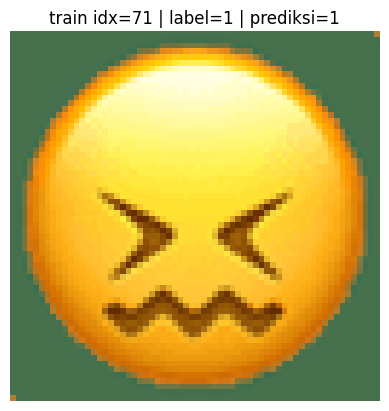

[TRAIN] idx=72 | size=64x64 | channels=3 | label=1 | prediksi=1


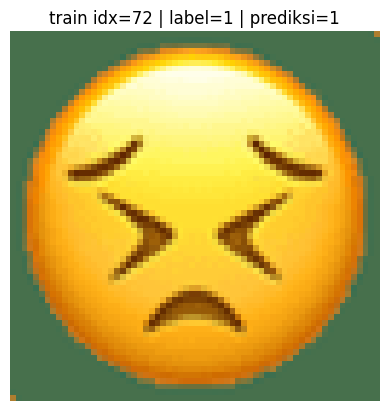

[TRAIN] idx=73 | size=64x64 | channels=3 | label=1 | prediksi=1


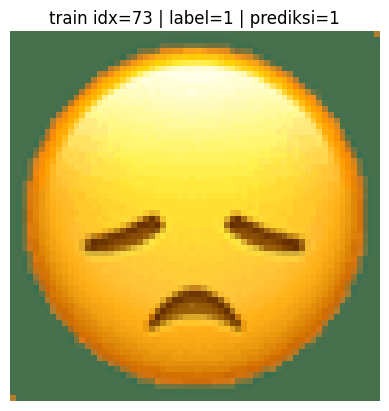

[TRAIN] idx=74 | size=64x64 | channels=3 | label=1 | prediksi=1


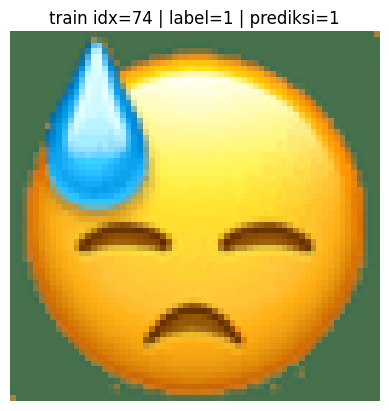

[TRAIN] idx=75 | size=64x64 | channels=3 | label=1 | prediksi=1


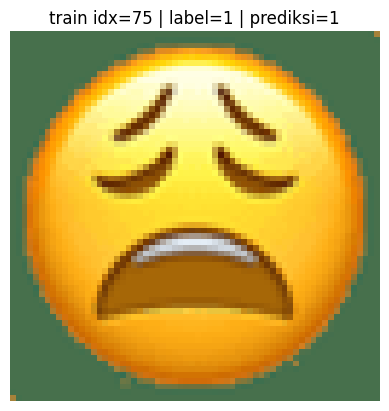

[TRAIN] idx=76 | size=64x64 | channels=3 | label=1 | prediksi=1


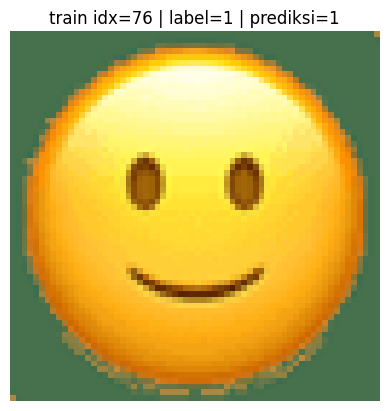

[TRAIN] idx=77 | size=64x64 | channels=3 | label=1 | prediksi=1


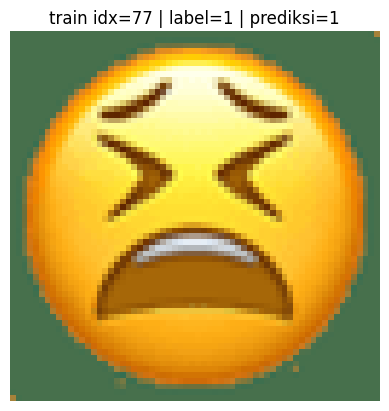

[TRAIN] idx=78 | size=64x64 | channels=3 | label=1 | prediksi=1


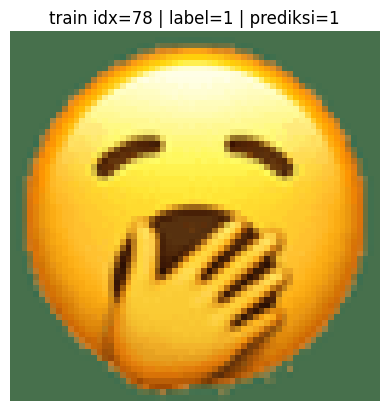

[TRAIN] idx=79 | size=64x64 | channels=3 | label=1 | prediksi=1


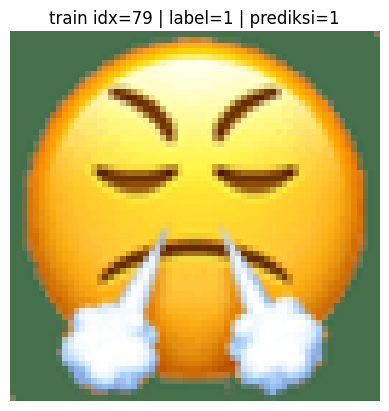

[TRAIN] idx=80 | size=64x64 | channels=3 | label=2 | prediksi=2


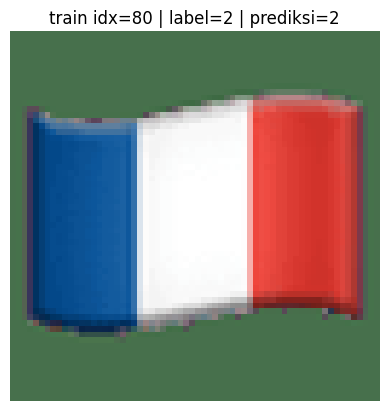

[TRAIN] idx=81 | size=64x64 | channels=3 | label=2 | prediksi=2


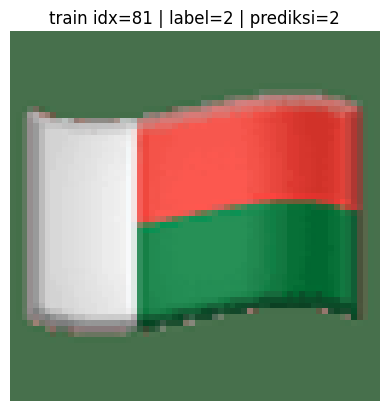

[TRAIN] idx=82 | size=64x64 | channels=3 | label=2 | prediksi=2


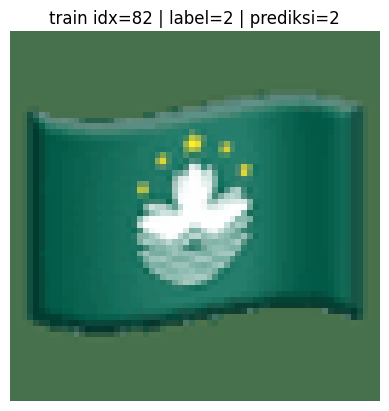

[TRAIN] idx=83 | size=64x64 | channels=3 | label=2 | prediksi=2


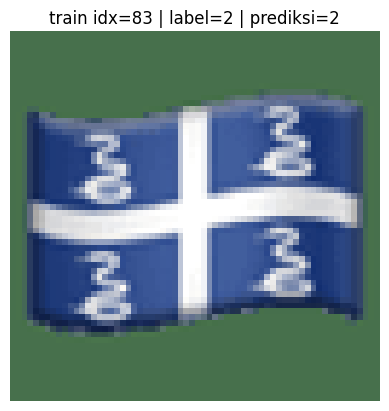

[TRAIN] idx=84 | size=64x64 | channels=3 | label=2 | prediksi=2


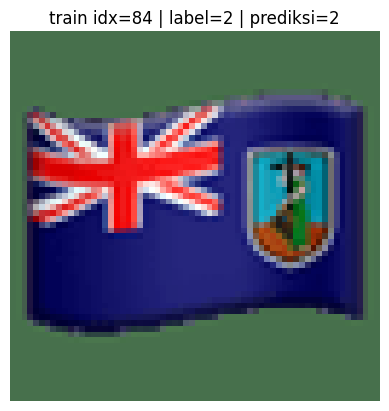

[TRAIN] idx=85 | size=64x64 | channels=3 | label=2 | prediksi=2


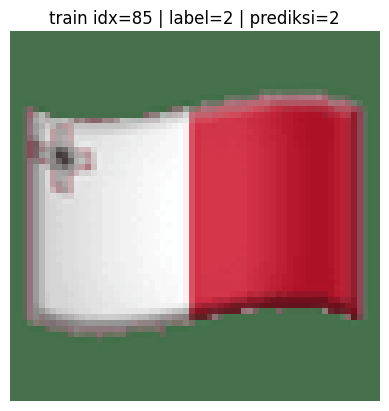

[TRAIN] idx=86 | size=64x64 | channels=3 | label=2 | prediksi=2


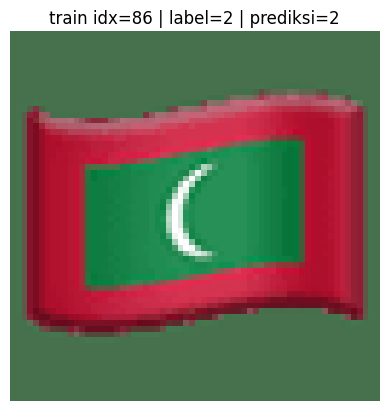

[TRAIN] idx=87 | size=64x64 | channels=3 | label=2 | prediksi=2


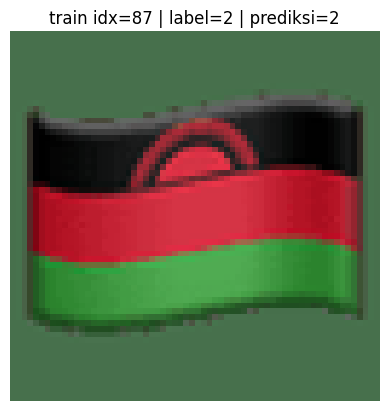

[TRAIN] idx=88 | size=64x64 | channels=3 | label=2 | prediksi=2


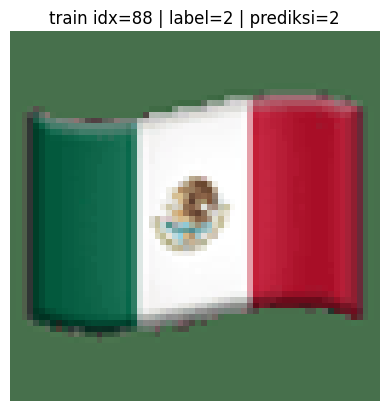

[TRAIN] idx=89 | size=64x64 | channels=3 | label=2 | prediksi=2


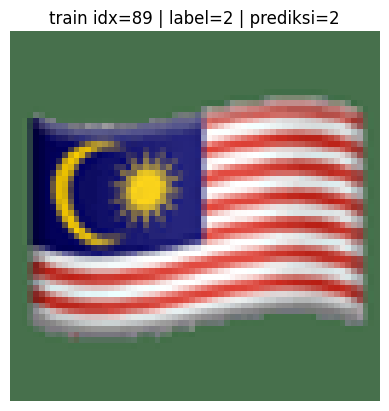

[TRAIN] idx=90 | size=64x64 | channels=3 | label=2 | prediksi=2


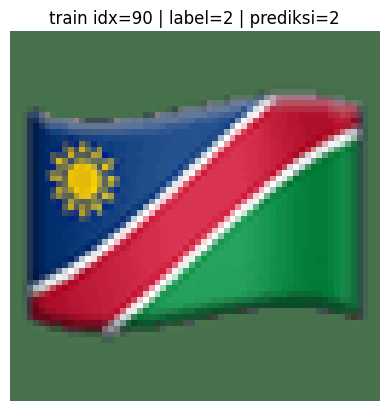

[TRAIN] idx=91 | size=64x64 | channels=3 | label=2 | prediksi=2


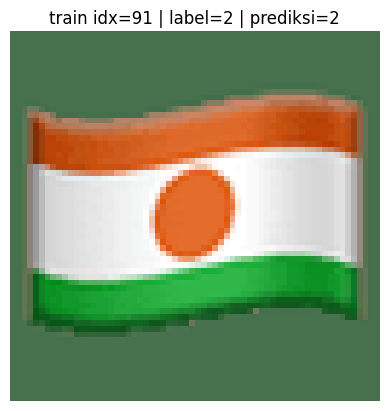

[TRAIN] idx=92 | size=64x64 | channels=3 | label=2 | prediksi=2


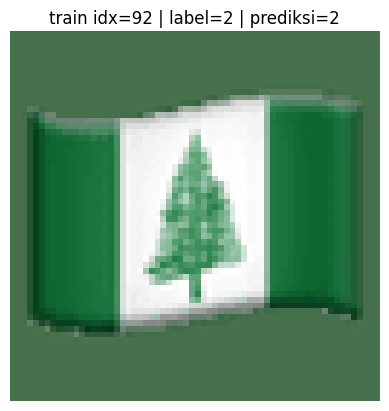

[TRAIN] idx=93 | size=64x64 | channels=3 | label=2 | prediksi=2


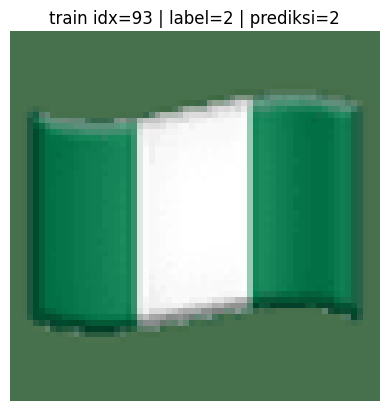

[TRAIN] idx=94 | size=64x64 | channels=3 | label=2 | prediksi=2


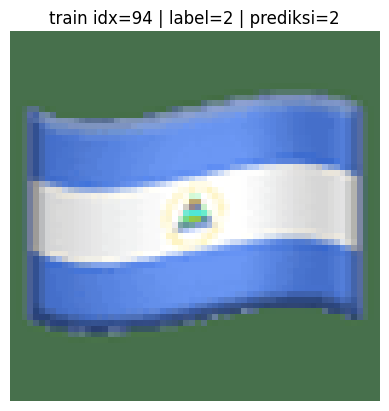

[TRAIN] idx=95 | size=64x64 | channels=3 | label=2 | prediksi=2


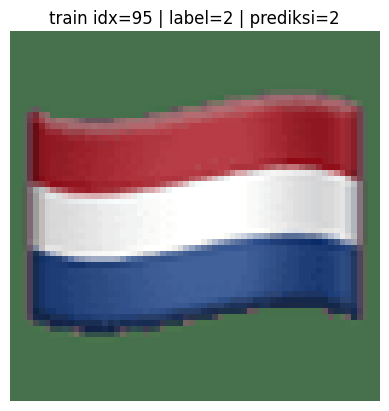

[TRAIN] idx=96 | size=64x64 | channels=3 | label=2 | prediksi=2


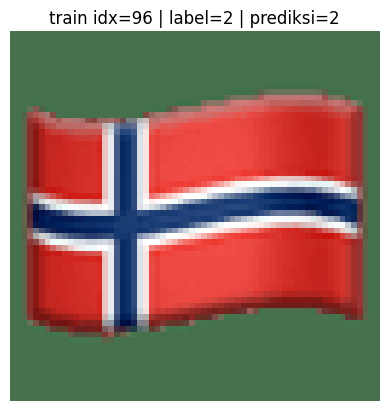

[TRAIN] idx=97 | size=64x64 | channels=3 | label=2 | prediksi=1


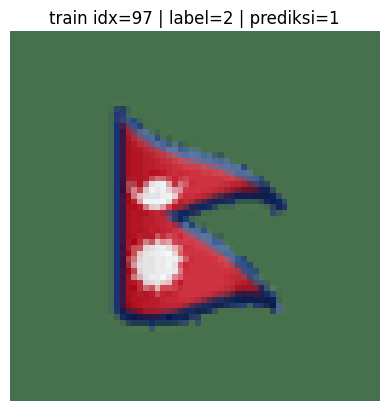

[TRAIN] idx=98 | size=64x64 | channels=3 | label=2 | prediksi=2


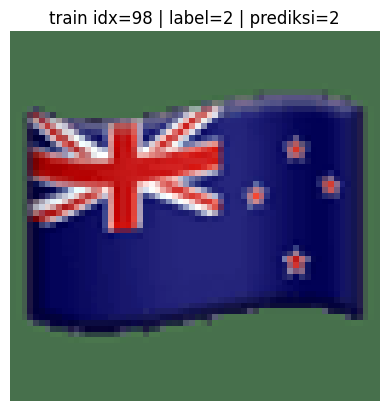

[TRAIN] idx=99 | size=64x64 | channels=3 | label=2 | prediksi=2


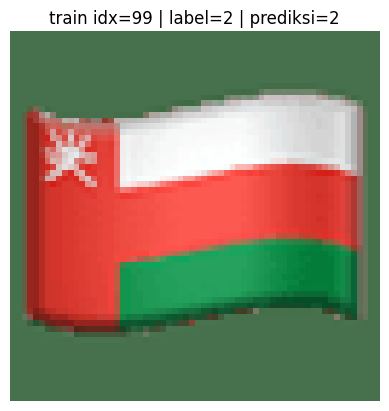

[TRAIN] idx=100 | size=64x64 | channels=3 | label=2 | prediksi=2


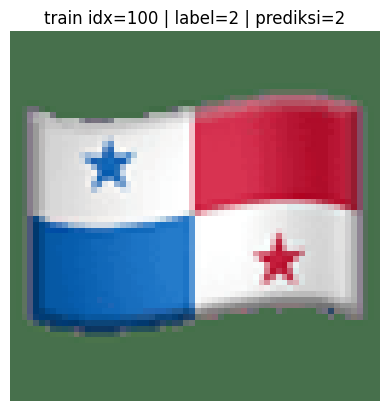

[TRAIN] idx=101 | size=64x64 | channels=3 | label=2 | prediksi=2


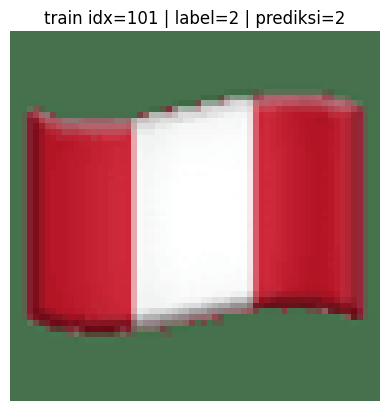

[TRAIN] idx=102 | size=64x64 | channels=3 | label=2 | prediksi=2


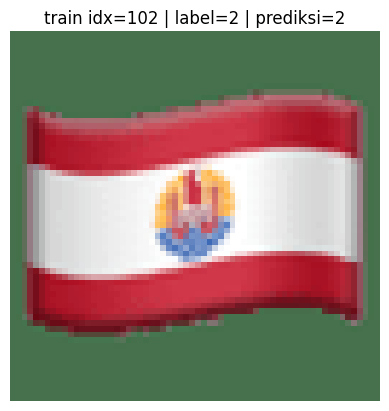

[TRAIN] idx=103 | size=64x64 | channels=3 | label=2 | prediksi=2


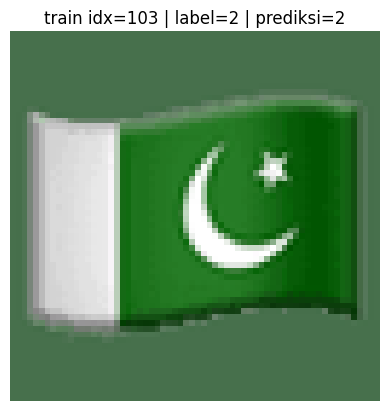

[TRAIN] idx=104 | size=64x64 | channels=3 | label=2 | prediksi=2


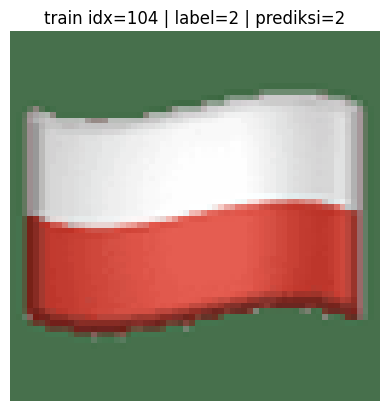

[TRAIN] idx=105 | size=64x64 | channels=3 | label=2 | prediksi=2


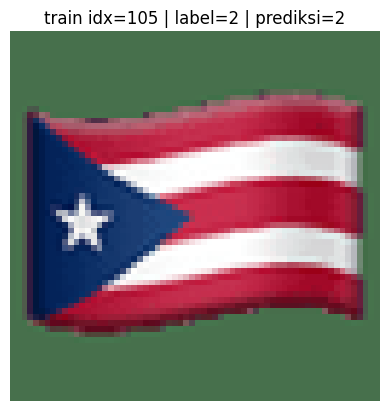

[TRAIN] idx=106 | size=64x64 | channels=3 | label=2 | prediksi=2


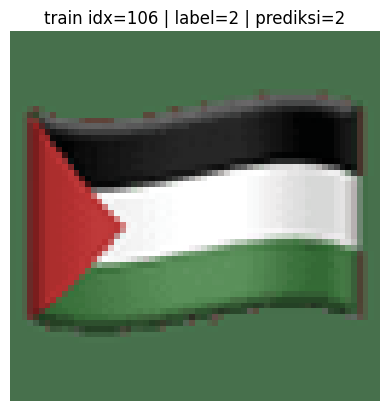

[TRAIN] idx=107 | size=64x64 | channels=3 | label=2 | prediksi=2


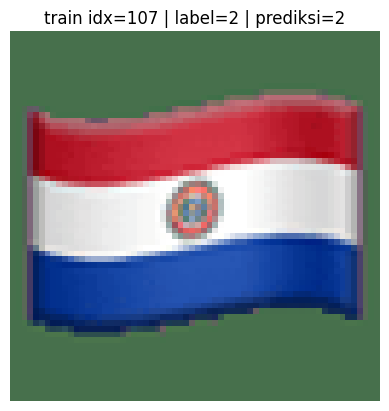

[TRAIN] idx=108 | size=64x64 | channels=3 | label=2 | prediksi=2


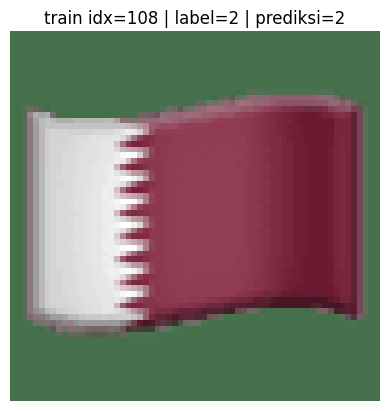

[TRAIN] idx=109 | size=64x64 | channels=3 | label=2 | prediksi=2


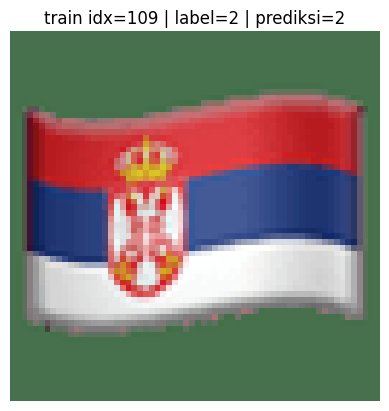

[TRAIN] idx=110 | size=64x64 | channels=3 | label=2 | prediksi=2


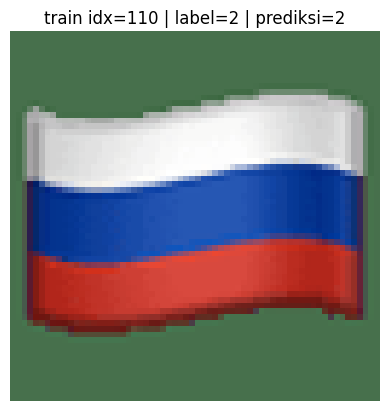

[TRAIN] idx=111 | size=64x64 | channels=3 | label=2 | prediksi=2


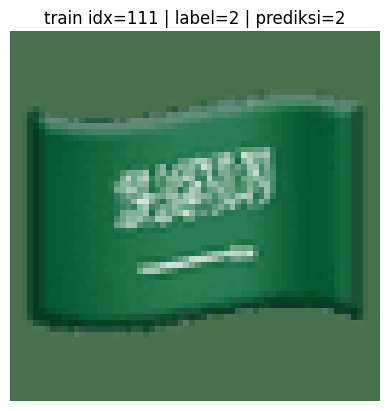

[TRAIN] idx=112 | size=64x64 | channels=3 | label=2 | prediksi=2


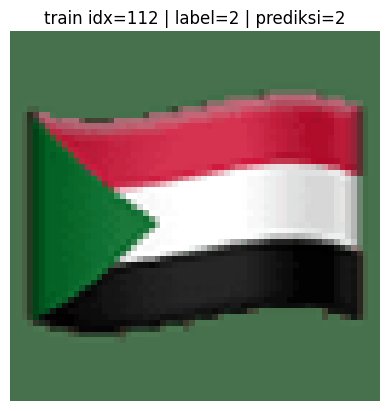

[TRAIN] idx=113 | size=64x64 | channels=3 | label=2 | prediksi=2


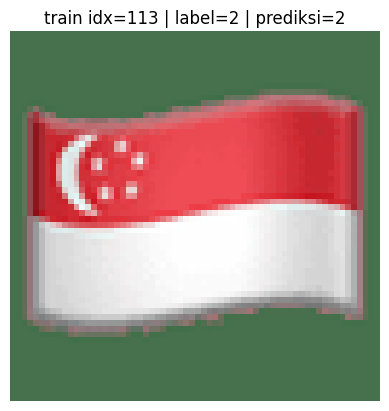

[TRAIN] idx=114 | size=64x64 | channels=3 | label=2 | prediksi=2


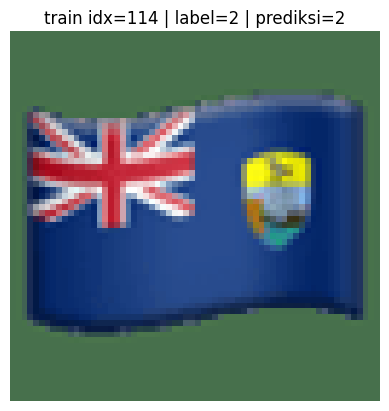

[TRAIN] idx=115 | size=64x64 | channels=3 | label=2 | prediksi=2


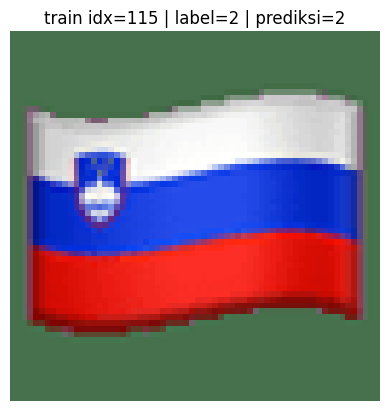

[TRAIN] idx=116 | size=64x64 | channels=3 | label=2 | prediksi=2


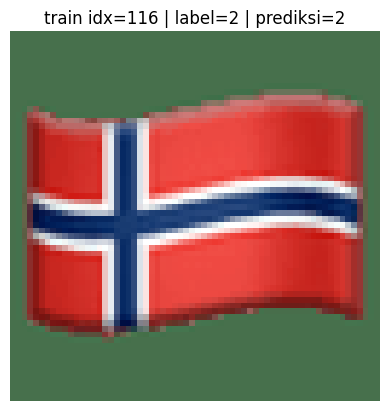

[TRAIN] idx=117 | size=64x64 | channels=3 | label=2 | prediksi=2


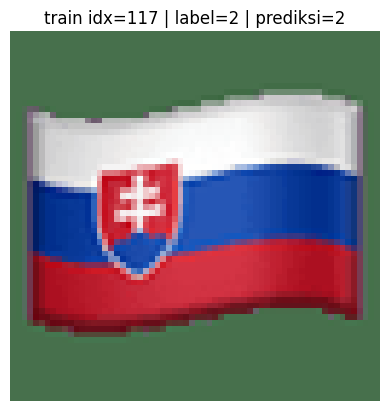

[TRAIN] idx=118 | size=64x64 | channels=3 | label=2 | prediksi=2


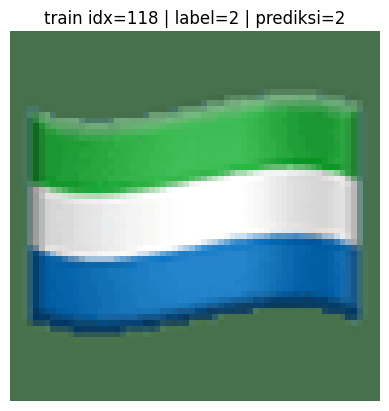

[TRAIN] idx=119 | size=64x64 | channels=3 | label=2 | prediksi=2


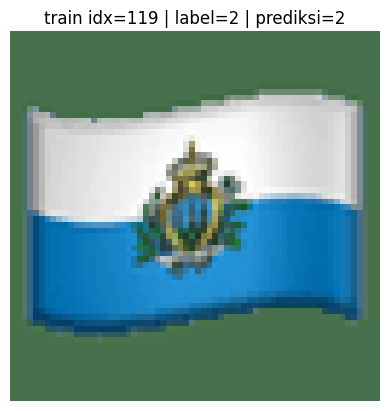

[TRAIN] idx=120 | size=64x64 | channels=3 | label=2 | prediksi=2


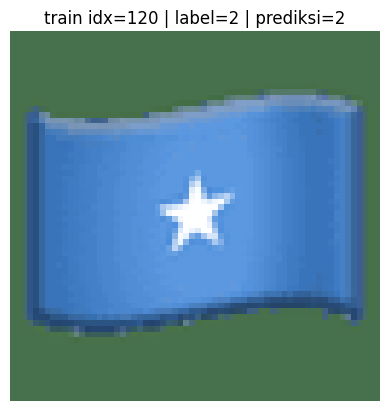

[TRAIN] idx=121 | size=64x64 | channels=3 | label=2 | prediksi=2


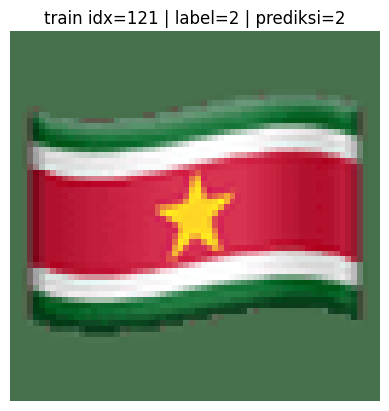

[TRAIN] idx=122 | size=64x64 | channels=3 | label=2 | prediksi=2


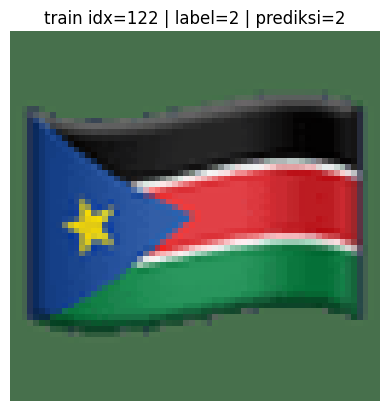

[TRAIN] idx=123 | size=64x64 | channels=3 | label=2 | prediksi=2


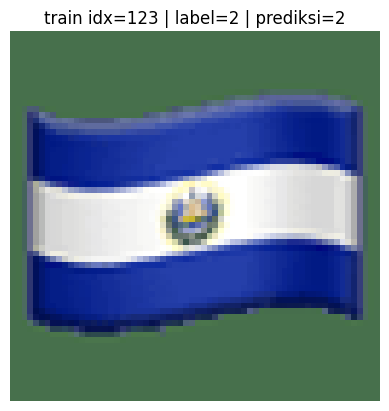

[TRAIN] idx=124 | size=64x64 | channels=3 | label=2 | prediksi=2


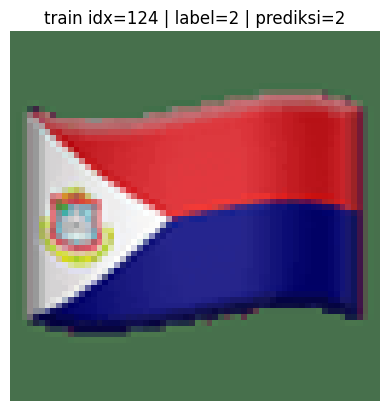

[TRAIN] idx=125 | size=64x64 | channels=3 | label=2 | prediksi=2


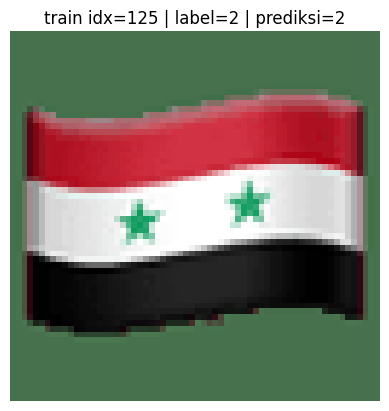

[TRAIN] idx=126 | size=64x64 | channels=3 | label=2 | prediksi=2


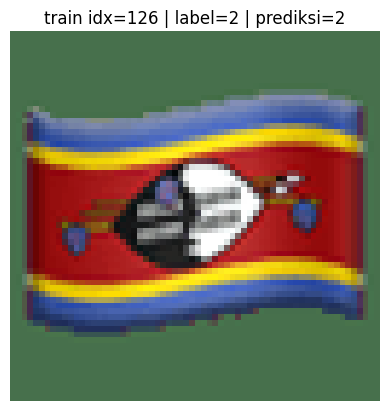

[TRAIN] idx=127 | size=64x64 | channels=3 | label=2 | prediksi=2


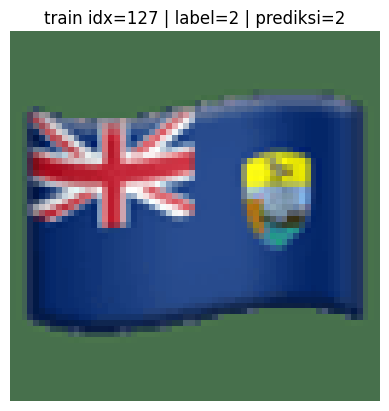

[TRAIN] idx=128 | size=64x64 | channels=3 | label=2 | prediksi=2


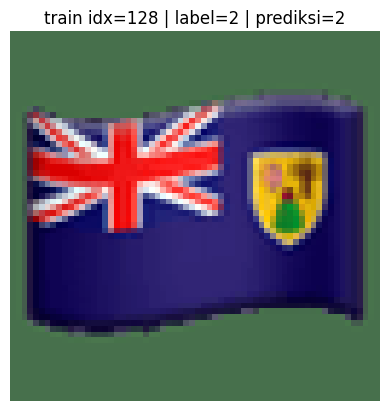

[TRAIN] idx=129 | size=64x64 | channels=3 | label=2 | prediksi=2


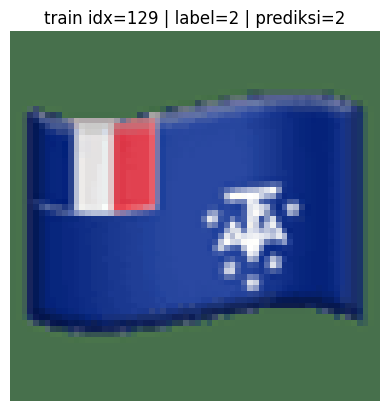

[TRAIN] idx=130 | size=64x64 | channels=3 | label=2 | prediksi=2


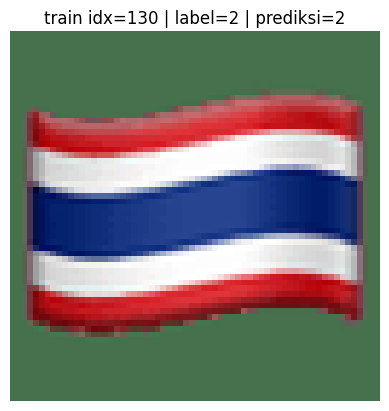

[TRAIN] idx=131 | size=64x64 | channels=3 | label=2 | prediksi=2


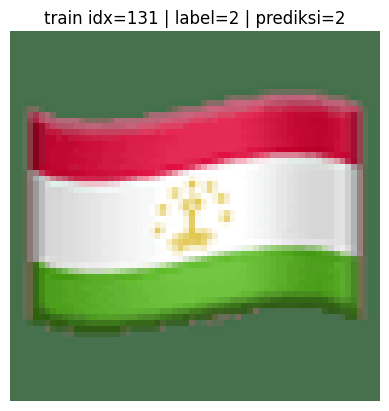

[TRAIN] idx=132 | size=64x64 | channels=3 | label=2 | prediksi=2


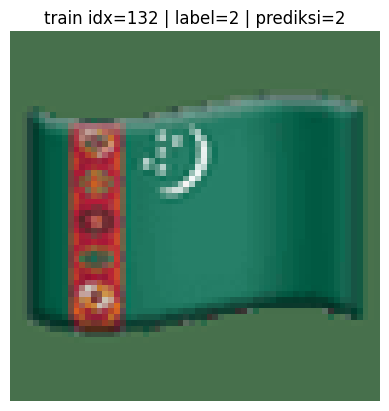

[TRAIN] idx=133 | size=64x64 | channels=3 | label=2 | prediksi=2


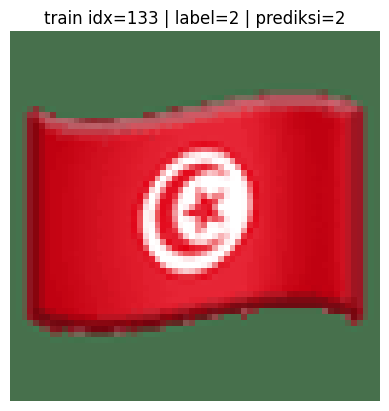

[TRAIN] idx=134 | size=64x64 | channels=3 | label=2 | prediksi=2


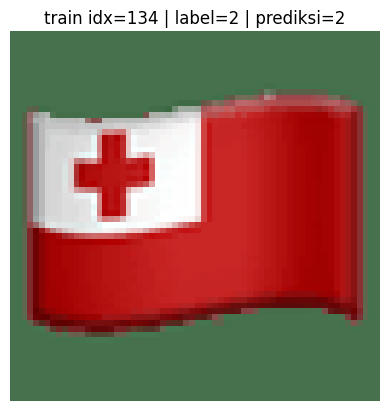

[TRAIN] idx=135 | size=64x64 | channels=3 | label=2 | prediksi=2


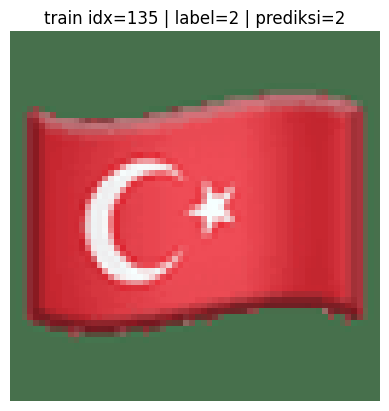

[TRAIN] idx=136 | size=64x64 | channels=3 | label=2 | prediksi=2


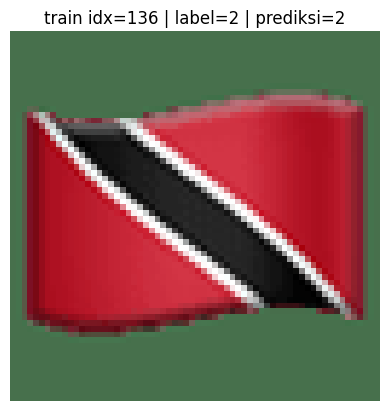

[TRAIN] idx=137 | size=64x64 | channels=3 | label=2 | prediksi=2


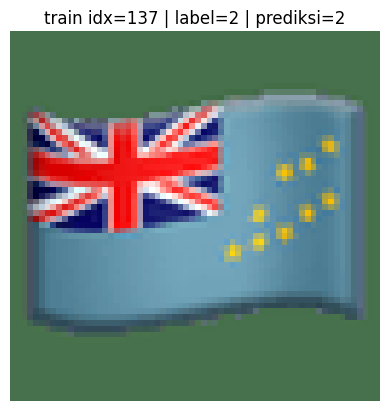

[TRAIN] idx=138 | size=64x64 | channels=3 | label=2 | prediksi=2


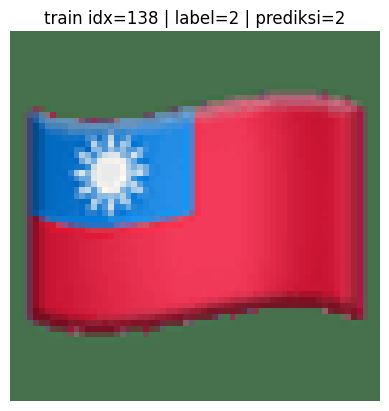

[TRAIN] idx=139 | size=64x64 | channels=3 | label=2 | prediksi=2


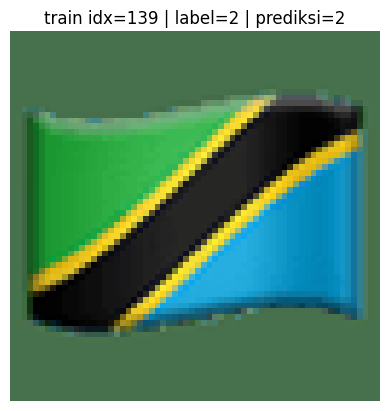

[TRAIN] idx=140 | size=64x64 | channels=3 | label=2 | prediksi=2


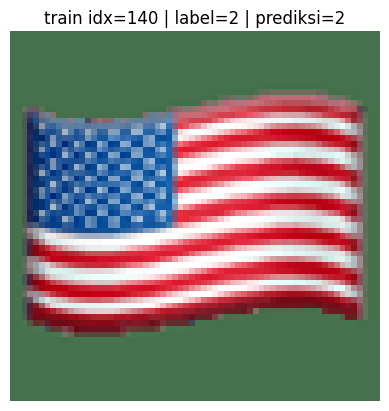

[TRAIN] idx=141 | size=64x64 | channels=3 | label=2 | prediksi=2


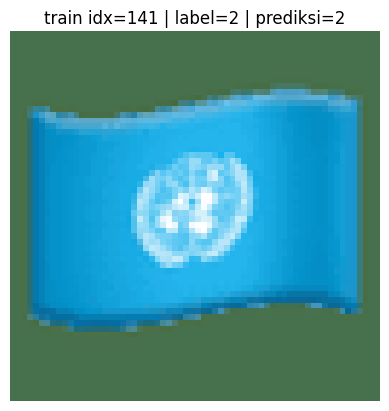

[TRAIN] idx=142 | size=64x64 | channels=3 | label=2 | prediksi=2


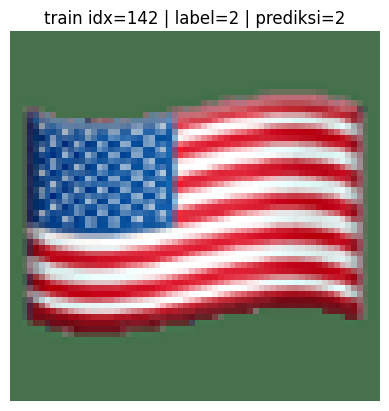

[TRAIN] idx=143 | size=64x64 | channels=3 | label=2 | prediksi=2


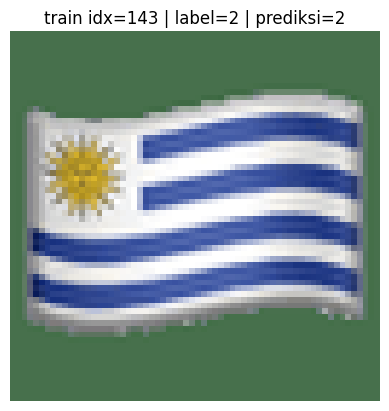

[TRAIN] idx=144 | size=64x64 | channels=3 | label=2 | prediksi=2


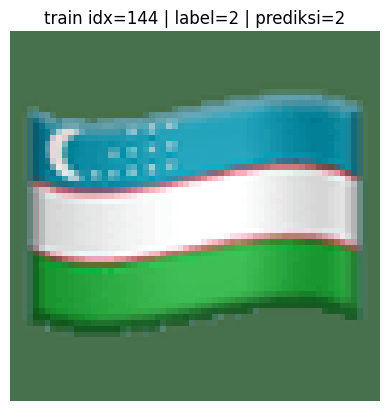

[TRAIN] idx=145 | size=64x64 | channels=3 | label=2 | prediksi=2


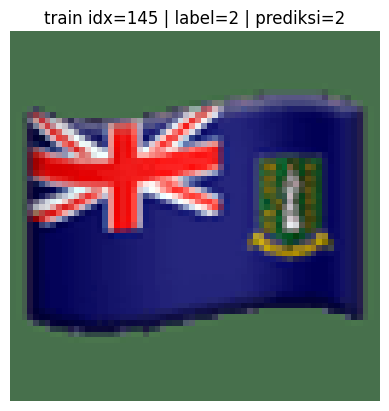

[TRAIN] idx=146 | size=64x64 | channels=3 | label=2 | prediksi=2


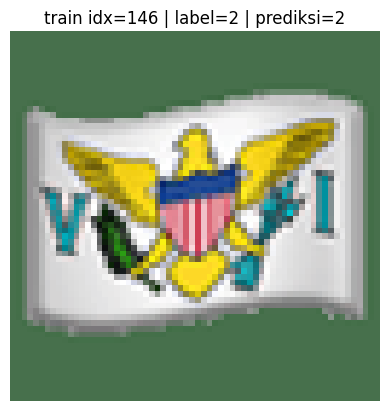

[TRAIN] idx=147 | size=64x64 | channels=3 | label=2 | prediksi=2


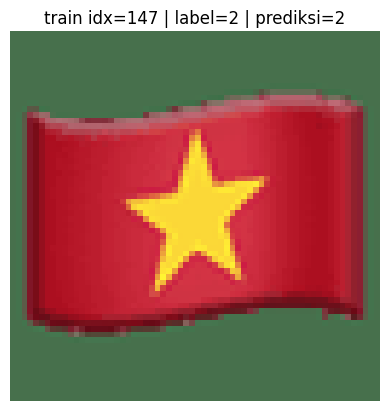

[TRAIN] idx=148 | size=64x64 | channels=3 | label=2 | prediksi=2


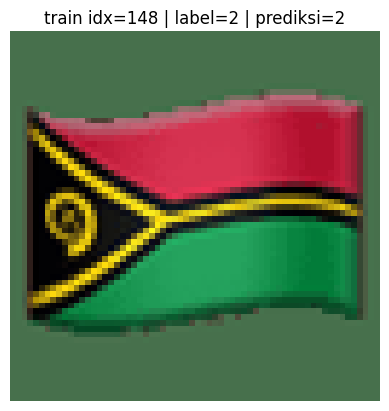

[TRAIN] idx=149 | size=64x64 | channels=3 | label=2 | prediksi=2


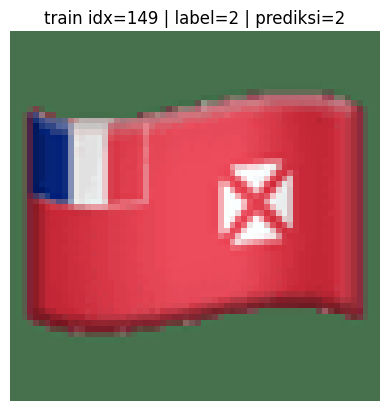

[TRAIN] idx=150 | size=64x64 | channels=3 | label=2 | prediksi=2


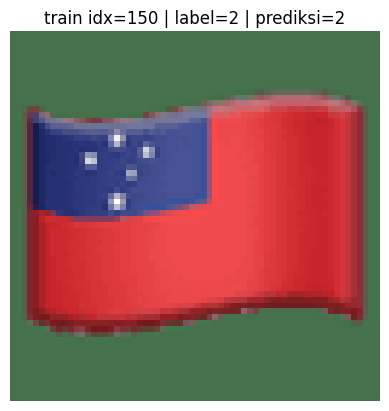

[TRAIN] idx=151 | size=64x64 | channels=3 | label=2 | prediksi=2


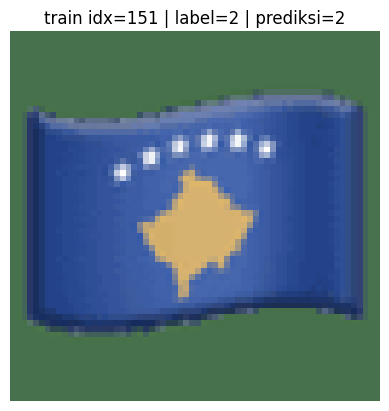

[TRAIN] idx=152 | size=64x64 | channels=3 | label=2 | prediksi=2


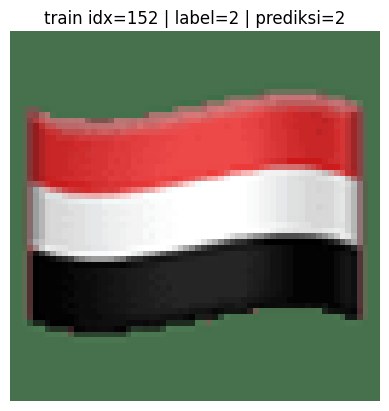

[TRAIN] idx=153 | size=64x64 | channels=3 | label=2 | prediksi=2


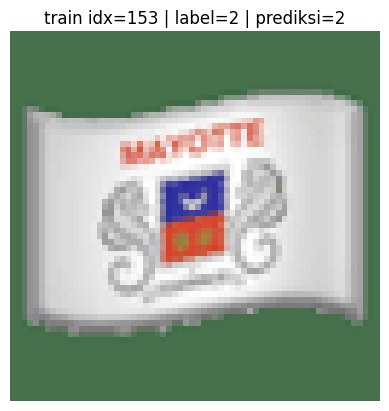

[TRAIN] idx=154 | size=64x64 | channels=3 | label=2 | prediksi=2


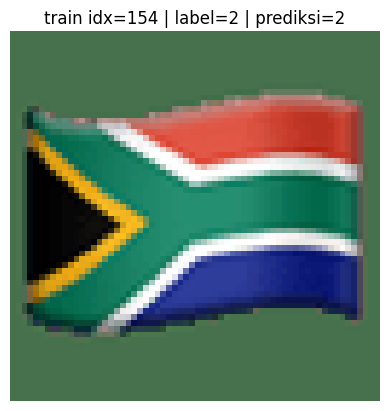

[TRAIN] idx=155 | size=64x64 | channels=3 | label=2 | prediksi=2


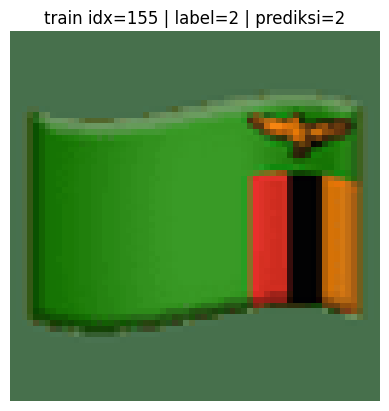

[TRAIN] idx=156 | size=64x64 | channels=3 | label=2 | prediksi=2


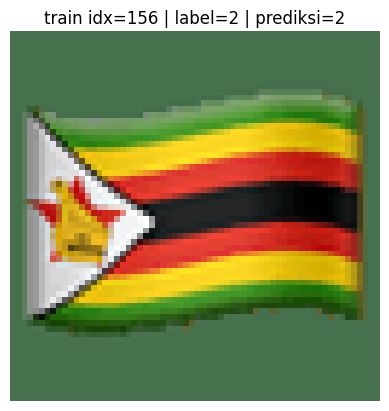

[TRAIN] idx=157 | size=64x64 | channels=3 | label=2 | prediksi=2


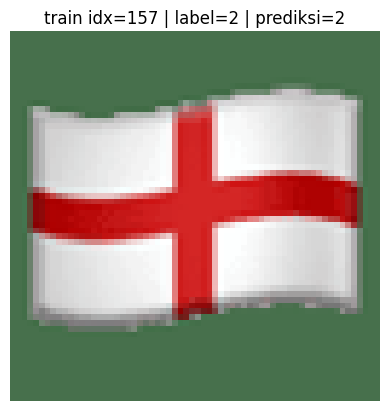

[TRAIN] idx=158 | size=64x64 | channels=3 | label=2 | prediksi=2


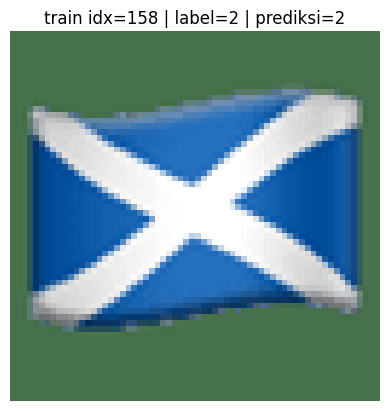

[TRAIN] idx=159 | size=64x64 | channels=3 | label=2 | prediksi=2


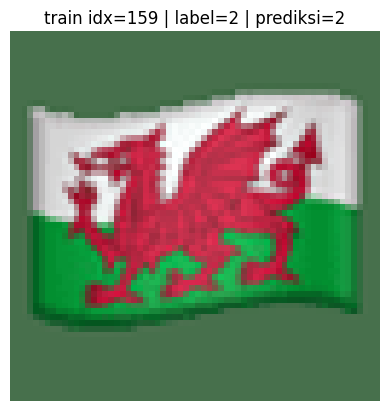

Evaluasi pada 160 sampel test:
Akurasi     : 0.9625
F1 Macro    : 0.9625


In [ ]:
# Template TRAIN (tanpa NumPy di kode Anda):
# - Mengiterasi contoh latih satu per satu
# - Mengonversi gambar menjadi list bersarang: img[baris][kolom] -> [R, G, B] (nilai 0..255)
# - Menampilkan informasi ukuran/kanal + visualisasi
# - Menyediakan tempat kosong untuk menulis fitur/keputusan Anda sendiri
#
# Catatan:
#   X_train: array gambar berukuran (N, H, W, 3) bertipe uint8
#   y_train: label berukuran (N,) bernilai {1, 2}

from emoji_train import X_train, y_train
import matplotlib.pyplot as plt

THRESH_N = 160  # batasi berapa banyak sampel yang diproses (agar cepat saat eksplorasi)

# (Opsional) list untuk menyimpan prediksi Anda (jika ingin mengevaluasi/submit nanti)
preds = []  # isi dengan 1 atau 2 untuk tiap sampel (panjangnya bebas di tahap eksplorasi)

N = min(THRESH_N, len(X_train))
for i in range(N):
    # Ambil satu gambar dan ubah ke list bersarang (tanpa bergantung pada NumPy di logika Anda)
    img = X_train[i].tolist()  # ukuran: H x W x 3, masing-masing piksel = [R, G, B] (0..255)

    # Ambil label (1 atau 2) untuk data TRAIN
    label = int(y_train[i])

    # Informasi struktur gambar
    H = len(img)                             # jumlah baris (tinggi)
    W = len(img[0]) if H > 0 else 0          # jumlah kolom (lebar)
    C = len(img[0][0]) if (H > 0 and W > 0) else 0  # jumlah kanal (harusnya 3 = RGB)

    # Memanggil fungsi `prediksi_gambar_img` yang Anda buat untuk memprediksi kelas gambar img.
    prediksi_label = prediksi_gambar_img(img)
    preds.append(prediksi_label)

    print(f"[TRAIN] idx={i} | size={H}x{W} | channels={C} | label={label} | prediksi={prediksi_label}")

    # (Opsional) Visualisasi untuk pengecekan cepat
    plt.imshow(img)
    plt.axis('off')
    plt.title(f"train idx={i} | label={label} | prediksi={prediksi_label}")
    plt.show()

# Anda bisa menggunakan variabel 'preds' untuk mengevaluasi TRAIN,
# dengan membandingkan 'preds' vs 'y_train'.

# ------------------------------
# CEK & EVALUASI
# ------------------------------
if len(preds) != N:
    raise RuntimeError(
        f"Prediksi belum lengkap: len(preds)={len(preds)} sementara N={N}. "
        "Silakan isi blok 'KODE ANDA MULAI DI SINI' untuk menghasilkan prediksi."
    )

acc, f1_macro = evaluate_binary_12(y_train[:N], preds)

print(f"Evaluasi pada {N} sampel test:")
print(f"Akurasi     : {acc:.4f}")
print(f"F1 Macro    : {f1_macro:.4f}")

<font color="red"><h2>PENILAIAN: Melakukan Prediksi Pada Data Uji</h2></font>

Jawaban Anda akan dinilai sebagian terhadap data uji yang terdiri dari 310 gambar emoji. Ekstraksi fitur dan aturan prediksi untuk sebuah gambar bisa diimplementasikan di fungsi `prediksi_gambar_img`, yang juga digunakan untuk memprediksi data latih.

**Catatan:**
1. **File pengujian hanya akan dibuka 1 jam sebelum kontes selesai!**
2. **Anda tidak perlu mengubah bagian kode di bawah ini, selama Anda mengimplementasikan fungsi** `prediksi_gambar_img` **di atas.** Kode di bawah ini akan otomatis berjalan dengan baik selama Anda mengimplementasikan fungsi `prediksi_gambar_img`.

/usr/local/lib/python3.12/dist-packages/gdown/__main__.py:139: FutureWarning: Option `--id` was deprecated in version 4.3.1 and will be removed in 5.0. You don't need to pass it anymore to use a file ID.
  warnings.warn(
Downloading...
From: https://drive.google.com/uc?id=1sgh5ofZ1Eg9J2TchSzdf1WOjB9PIeoO4
To: /content/OSNAI2025_privateGT.zip
100% 2.77M/2.77M [00:00<00:00, 210MB/s]
Archive:  OSNAI2025_privateGT.zip
  inflating: /content/label_map.json  
  inflating: /content/emoji_test_gt.py  
  inflating: /content/test_private_gt.npz  
  inflating: /content/build_stats_private.json  
[TEST] size=64x64 | channels=3 | label=2 | prediksi=2 | idx =0


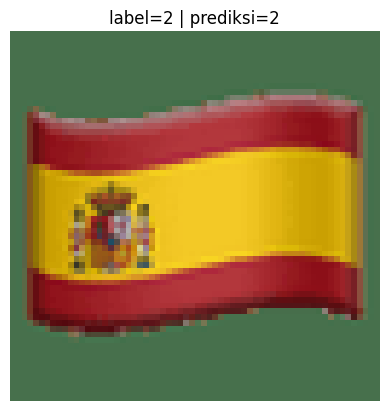

[TEST] size=64x64 | channels=3 | label=1 | prediksi=1 | idx =1


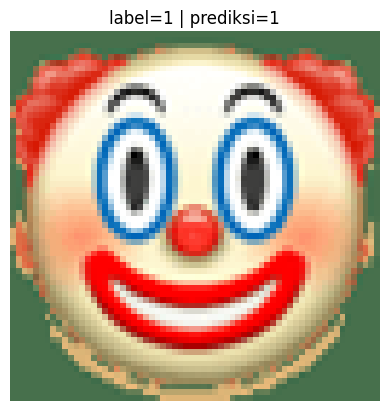

[TEST] size=64x64 | channels=3 | label=2 | prediksi=2 | idx =2


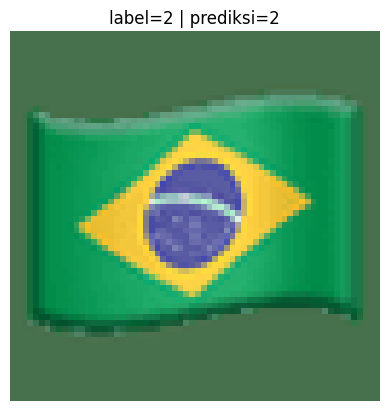

[TEST] size=64x64 | channels=3 | label=1 | prediksi=1 | idx =3


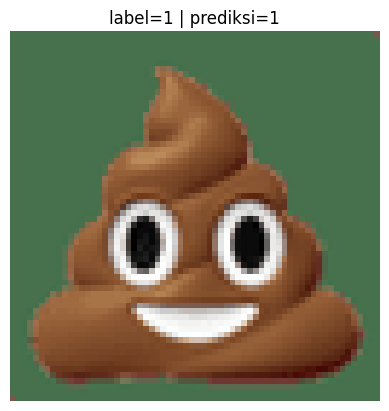

[TEST] size=64x64 | channels=3 | label=1 | prediksi=1 | idx =4


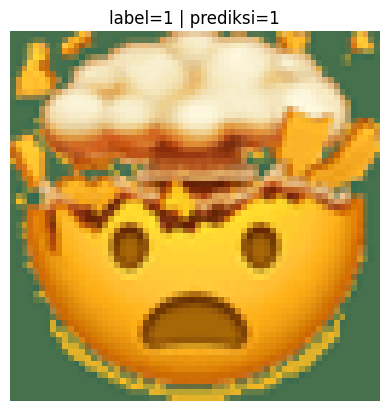

[TEST] size=64x64 | channels=3 | label=1 | prediksi=1 | idx =5


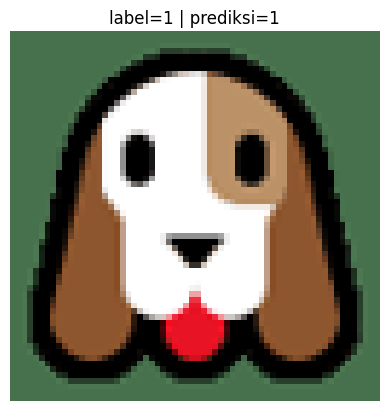

[TEST] size=64x64 | channels=3 | label=1 | prediksi=1 | idx =6


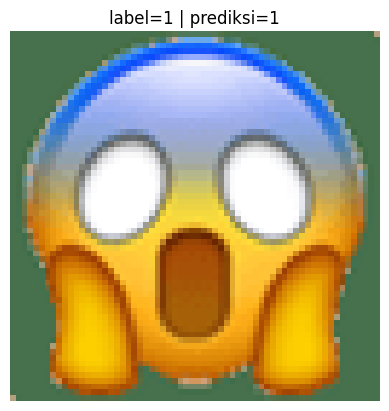

[TEST] size=64x64 | channels=3 | label=2 | prediksi=2 | idx =7


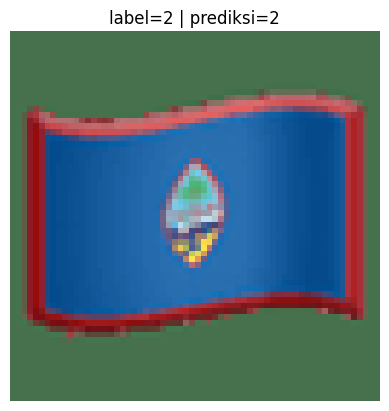

[TEST] size=64x64 | channels=3 | label=2 | prediksi=2 | idx =8


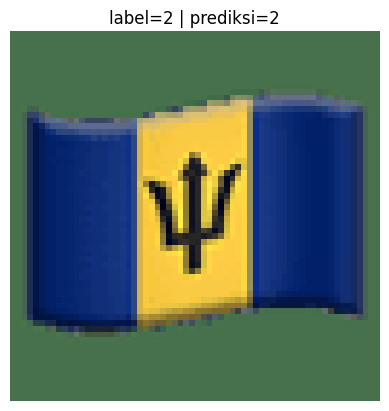

[TEST] size=64x64 | channels=3 | label=1 | prediksi=1 | idx =9


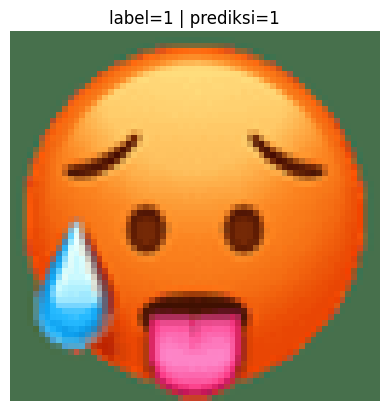

[TEST] size=64x64 | channels=3 | label=1 | prediksi=2 | idx =10


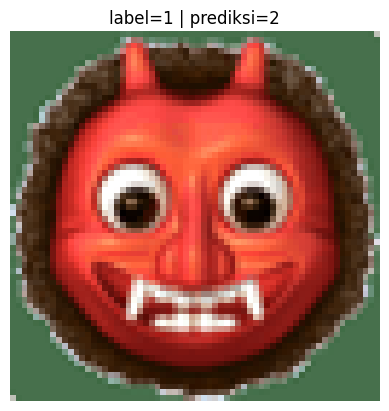

[TEST] size=64x64 | channels=3 | label=1 | prediksi=1 | idx =11


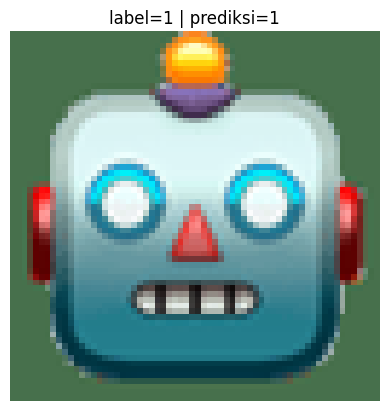

[TEST] size=64x64 | channels=3 | label=2 | prediksi=1 | idx =12


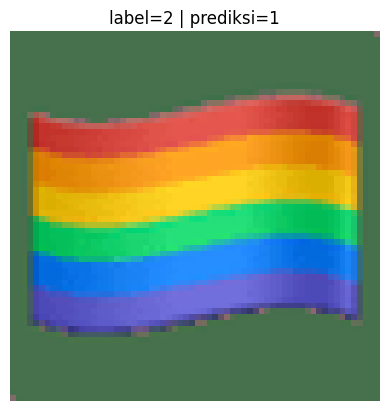

[TEST] size=64x64 | channels=3 | label=2 | prediksi=2 | idx =13


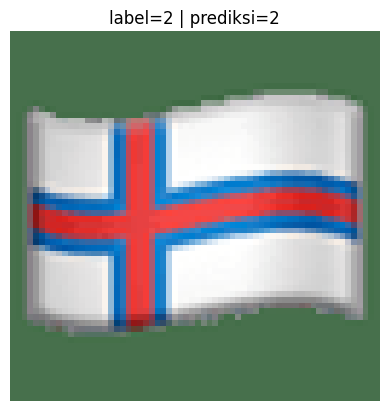

[TEST] size=64x64 | channels=3 | label=1 | prediksi=1 | idx =14


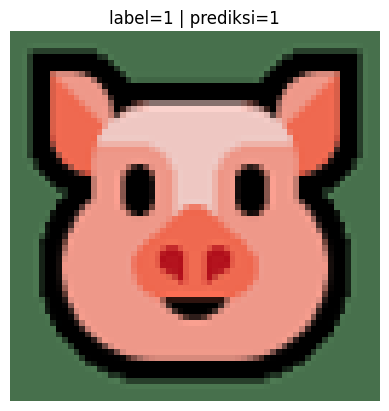

[TEST] size=64x64 | channels=3 | label=2 | prediksi=2 | idx =15


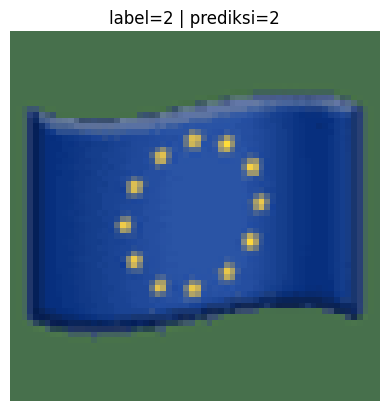

[TEST] size=64x64 | channels=3 | label=2 | prediksi=2 | idx =16


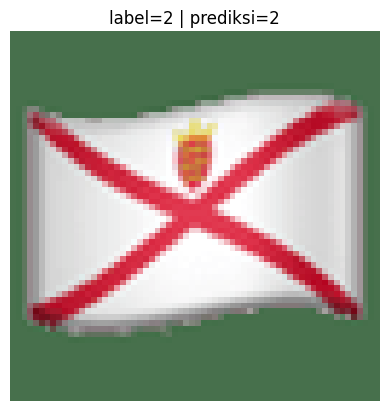

[TEST] size=64x64 | channels=3 | label=1 | prediksi=1 | idx =17


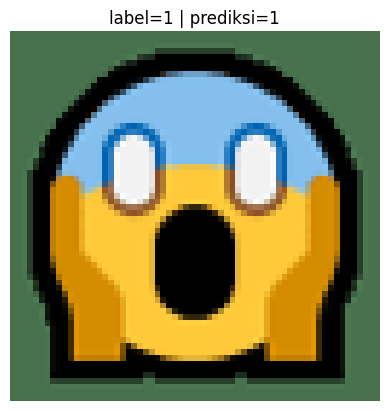

[TEST] size=64x64 | channels=3 | label=2 | prediksi=2 | idx =18


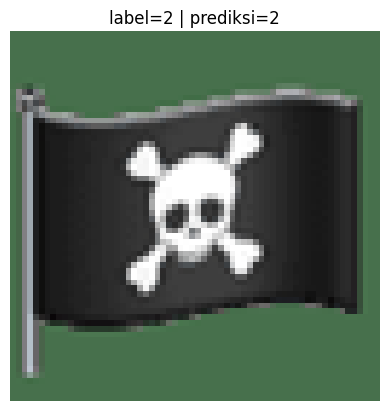

[TEST] size=64x64 | channels=3 | label=2 | prediksi=2 | idx =19


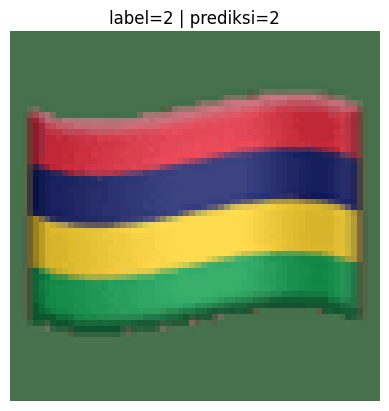

[TEST] size=64x64 | channels=3 | label=2 | prediksi=2 | idx =20


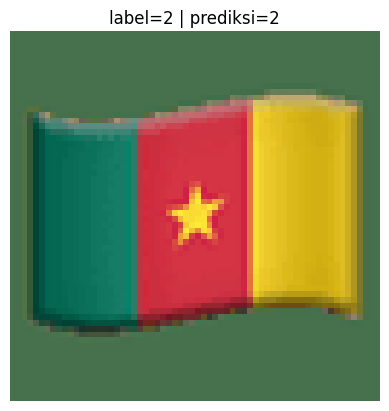

[TEST] size=64x64 | channels=3 | label=2 | prediksi=2 | idx =21


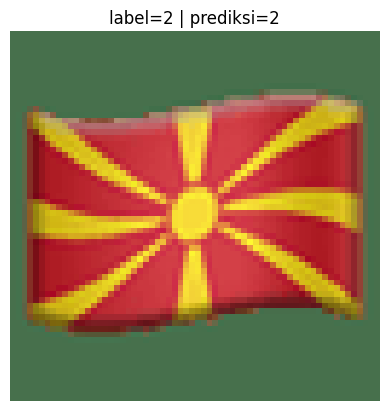

[TEST] size=64x64 | channels=3 | label=2 | prediksi=2 | idx =22


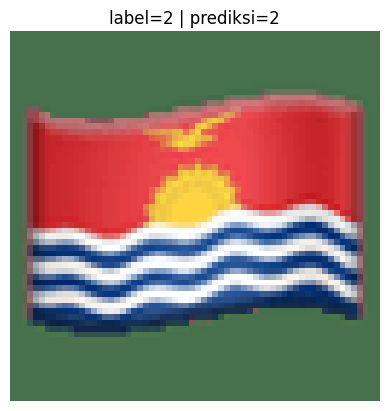

[TEST] size=64x64 | channels=3 | label=1 | prediksi=2 | idx =23


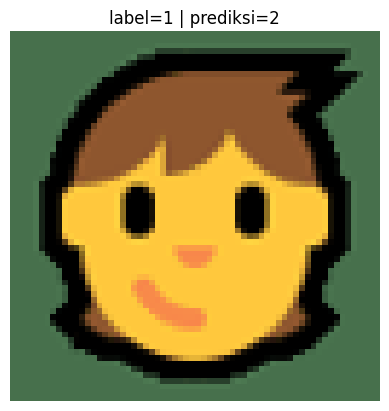

[TEST] size=64x64 | channels=3 | label=1 | prediksi=1 | idx =24


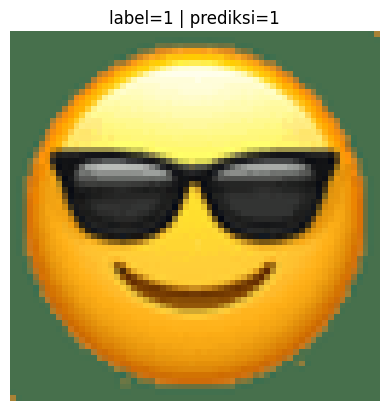

[TEST] size=64x64 | channels=3 | label=2 | prediksi=2 | idx =25


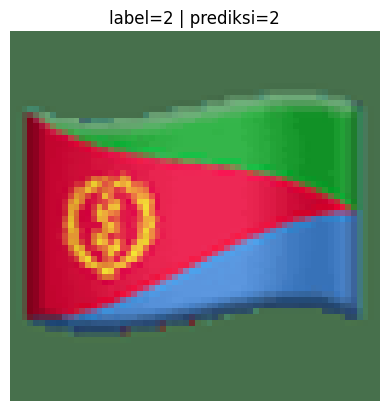

[TEST] size=64x64 | channels=3 | label=2 | prediksi=2 | idx =26


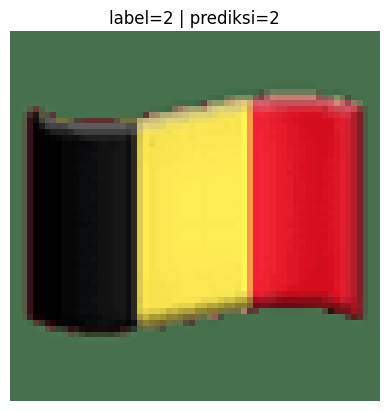

[TEST] size=64x64 | channels=3 | label=2 | prediksi=2 | idx =27


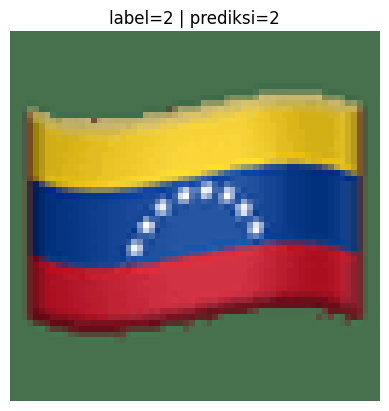

[TEST] size=64x64 | channels=3 | label=2 | prediksi=2 | idx =28


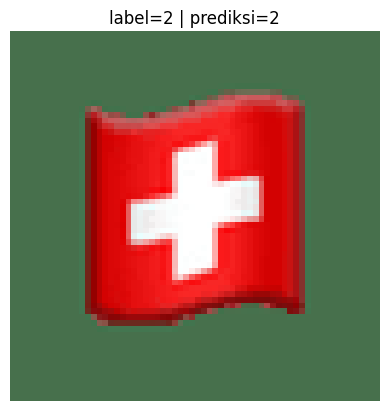

[TEST] size=64x64 | channels=3 | label=2 | prediksi=2 | idx =29


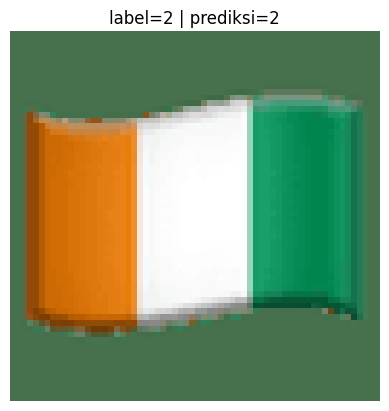

[TEST] size=64x64 | channels=3 | label=1 | prediksi=1 | idx =30


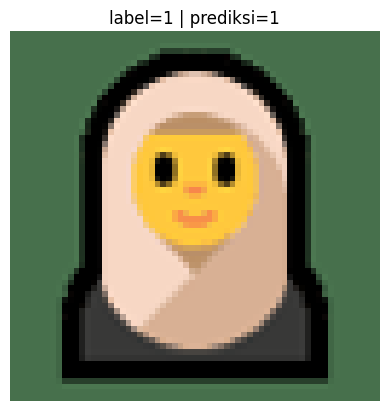

[TEST] size=64x64 | channels=3 | label=2 | prediksi=2 | idx =31


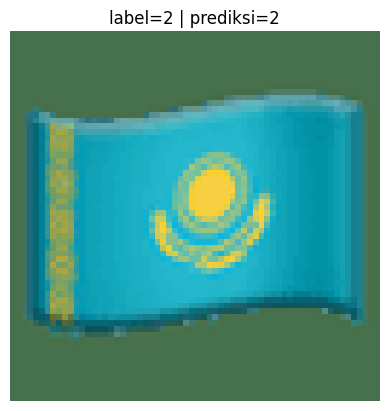

[TEST] size=64x64 | channels=3 | label=2 | prediksi=2 | idx =32


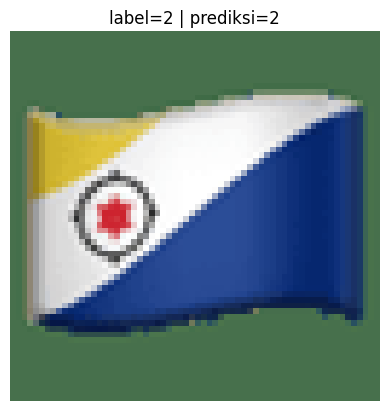

[TEST] size=64x64 | channels=3 | label=1 | prediksi=2 | idx =33


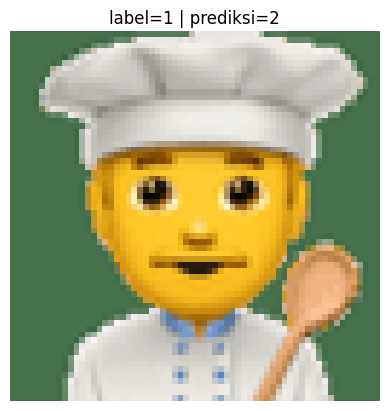

[TEST] size=64x64 | channels=3 | label=1 | prediksi=1 | idx =34


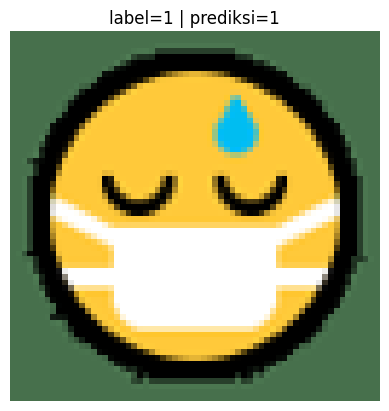

[TEST] size=64x64 | channels=3 | label=2 | prediksi=2 | idx =35


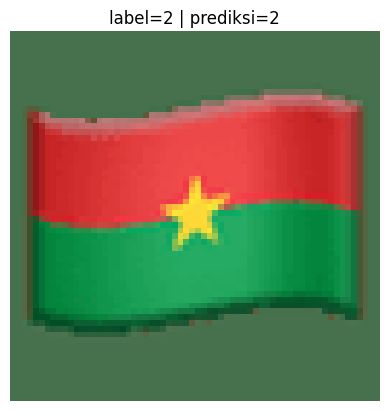

[TEST] size=64x64 | channels=3 | label=2 | prediksi=2 | idx =36


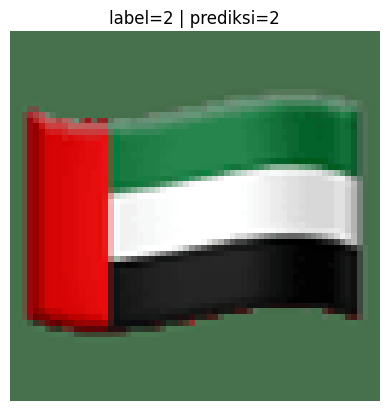

[TEST] size=64x64 | channels=3 | label=2 | prediksi=2 | idx =37


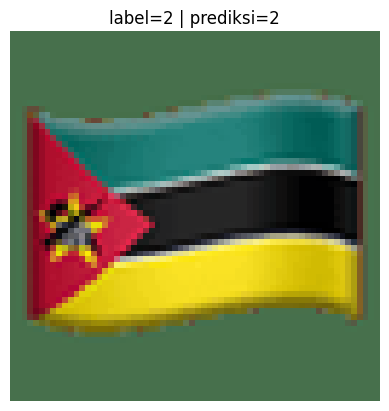

[TEST] size=64x64 | channels=3 | label=1 | prediksi=1 | idx =38


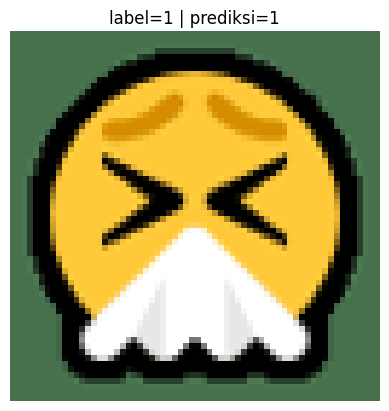

[TEST] size=64x64 | channels=3 | label=2 | prediksi=2 | idx =39


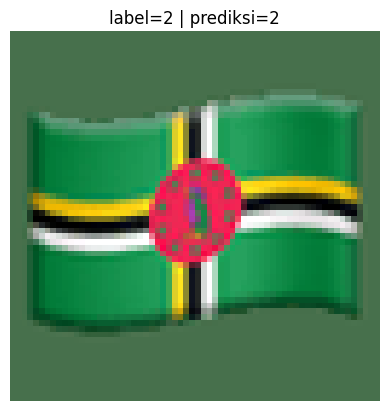

[TEST] size=64x64 | channels=3 | label=1 | prediksi=1 | idx =40


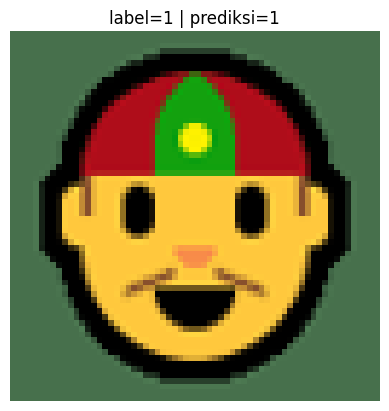

[TEST] size=64x64 | channels=3 | label=2 | prediksi=2 | idx =41


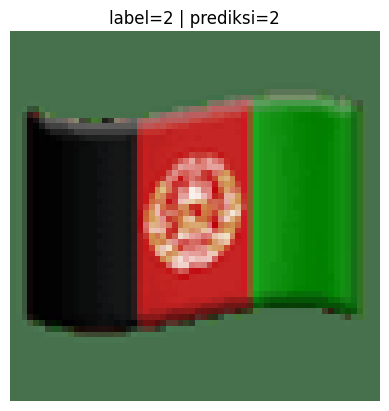

[TEST] size=64x64 | channels=3 | label=1 | prediksi=1 | idx =42


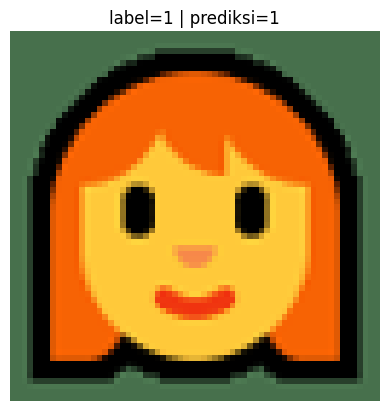

[TEST] size=64x64 | channels=3 | label=1 | prediksi=1 | idx =43


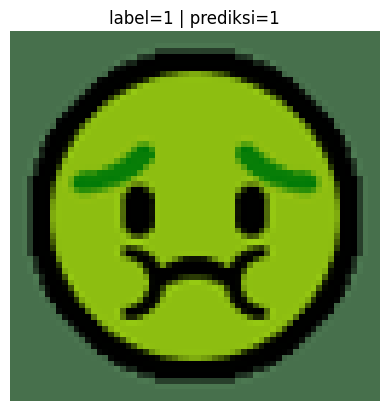

[TEST] size=64x64 | channels=3 | label=1 | prediksi=1 | idx =44


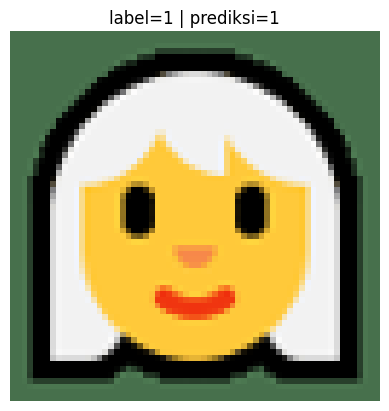

[TEST] size=64x64 | channels=3 | label=1 | prediksi=1 | idx =45


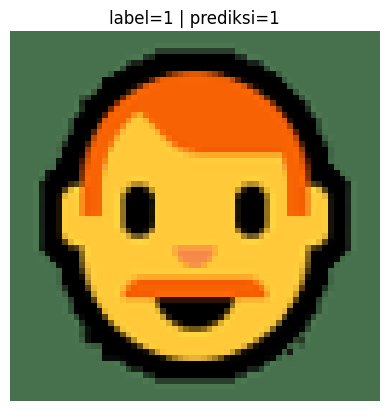

[TEST] size=64x64 | channels=3 | label=2 | prediksi=2 | idx =46


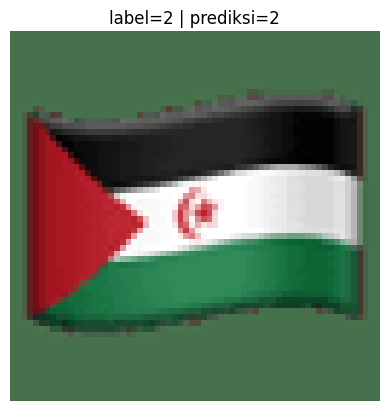

[TEST] size=64x64 | channels=3 | label=2 | prediksi=2 | idx =47


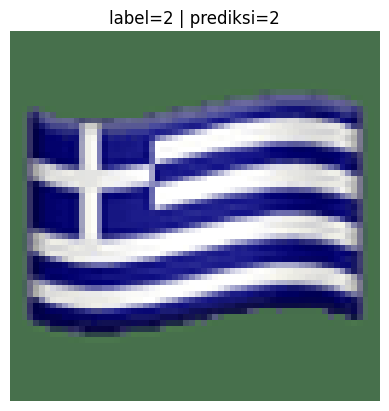

[TEST] size=64x64 | channels=3 | label=2 | prediksi=2 | idx =48


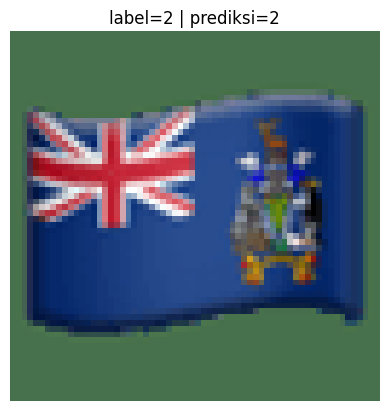

[TEST] size=64x64 | channels=3 | label=2 | prediksi=2 | idx =49


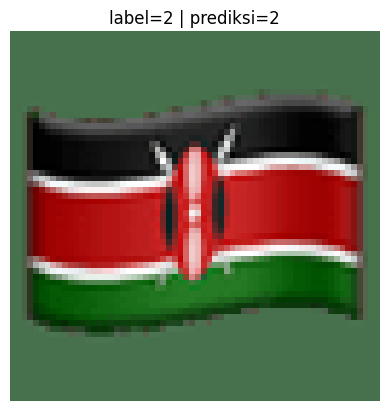

[TEST] size=64x64 | channels=3 | label=1 | prediksi=2 | idx =50


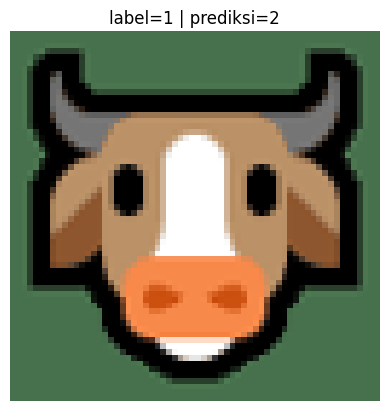

[TEST] size=64x64 | channels=3 | label=1 | prediksi=2 | idx =51


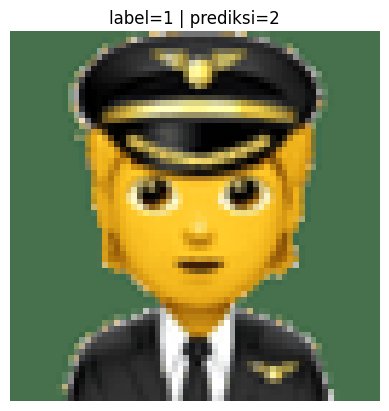

[TEST] size=64x64 | channels=3 | label=2 | prediksi=2 | idx =52


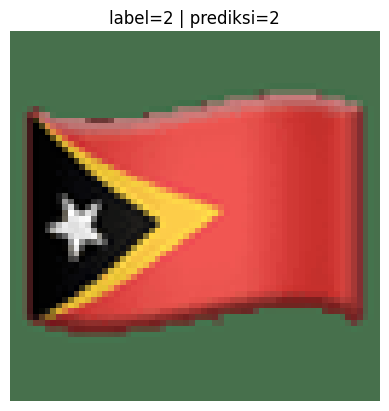

[TEST] size=64x64 | channels=3 | label=1 | prediksi=1 | idx =53


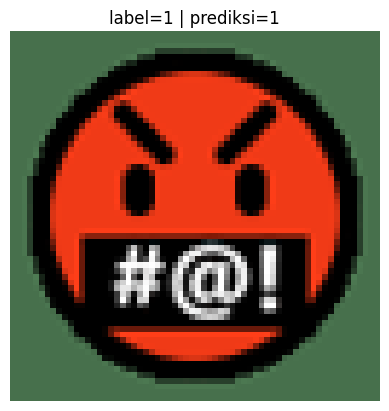

[TEST] size=64x64 | channels=3 | label=2 | prediksi=2 | idx =54


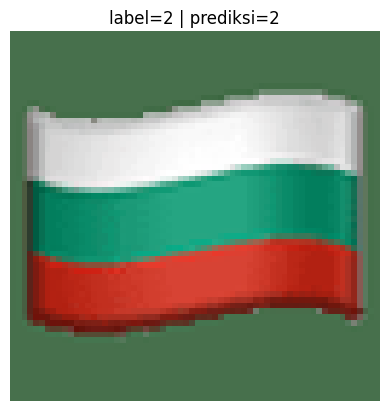

[TEST] size=64x64 | channels=3 | label=2 | prediksi=2 | idx =55


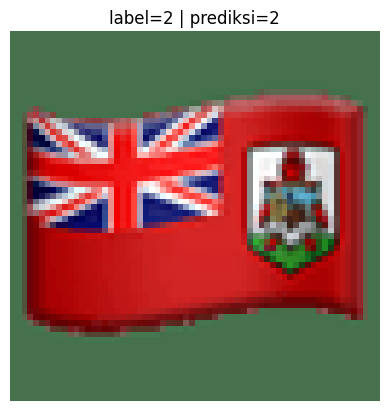

[TEST] size=64x64 | channels=3 | label=2 | prediksi=2 | idx =56


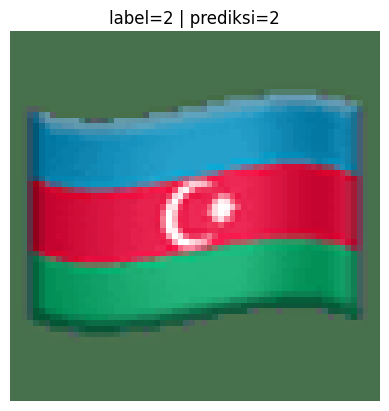

[TEST] size=64x64 | channels=3 | label=1 | prediksi=1 | idx =57


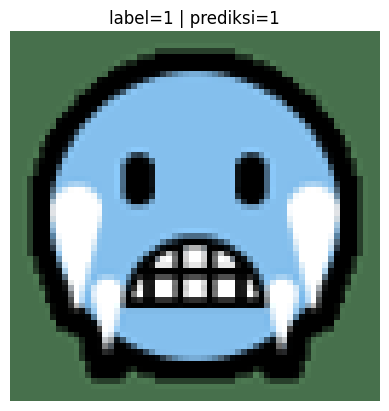

[TEST] size=64x64 | channels=3 | label=1 | prediksi=1 | idx =58


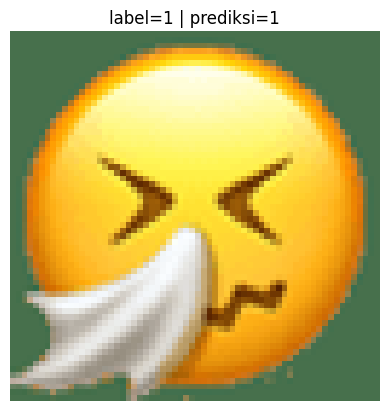

[TEST] size=64x64 | channels=3 | label=2 | prediksi=2 | idx =59


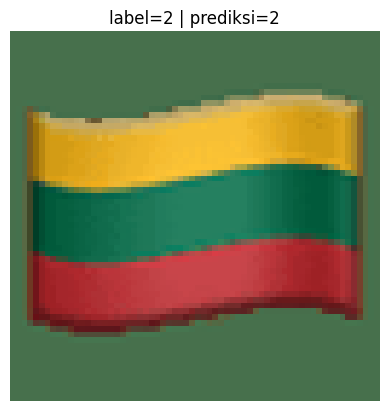

[TEST] size=64x64 | channels=3 | label=2 | prediksi=2 | idx =60


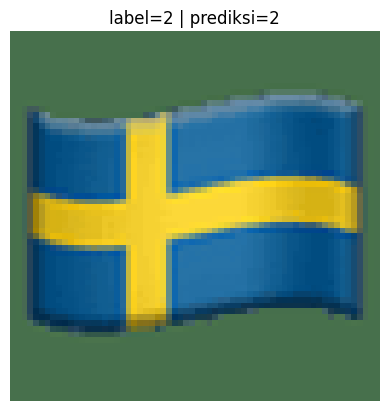

[TEST] size=64x64 | channels=3 | label=1 | prediksi=1 | idx =61


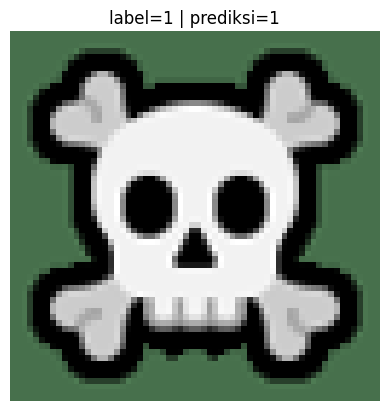

[TEST] size=64x64 | channels=3 | label=2 | prediksi=2 | idx =62


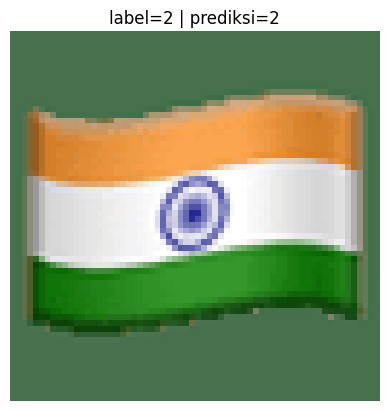

[TEST] size=64x64 | channels=3 | label=1 | prediksi=1 | idx =63


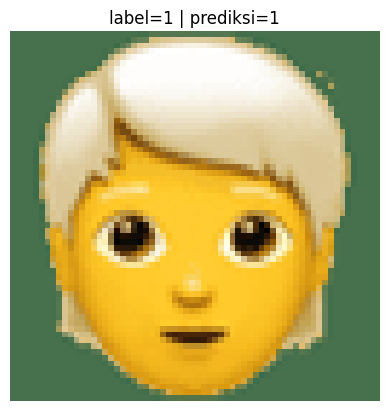

[TEST] size=64x64 | channels=3 | label=1 | prediksi=2 | idx =64


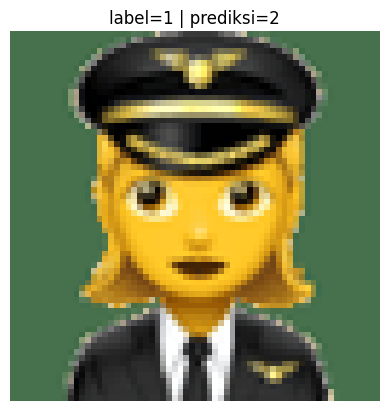

[TEST] size=64x64 | channels=3 | label=2 | prediksi=2 | idx =65


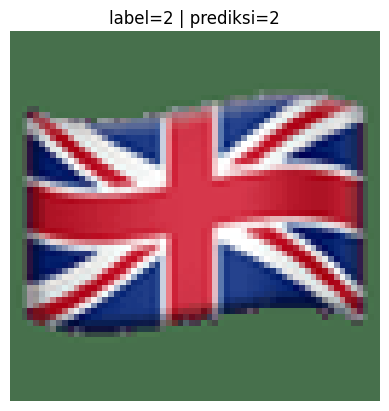

[TEST] size=64x64 | channels=3 | label=2 | prediksi=2 | idx =66


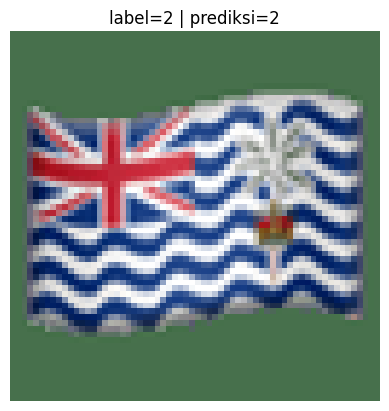

[TEST] size=64x64 | channels=3 | label=2 | prediksi=2 | idx =67


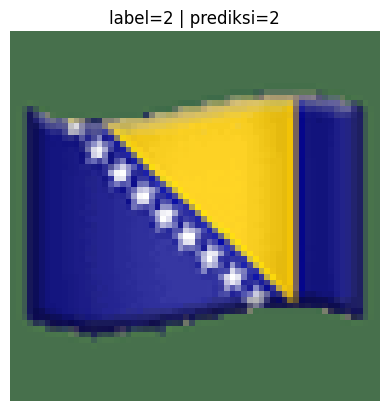

[TEST] size=64x64 | channels=3 | label=2 | prediksi=2 | idx =68


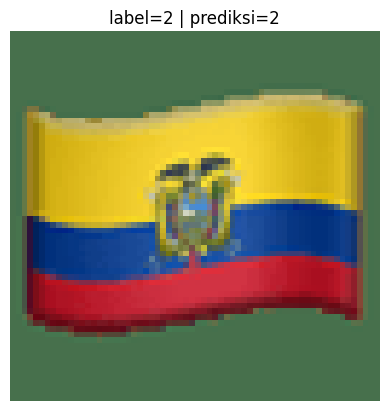

[TEST] size=64x64 | channels=3 | label=2 | prediksi=2 | idx =69


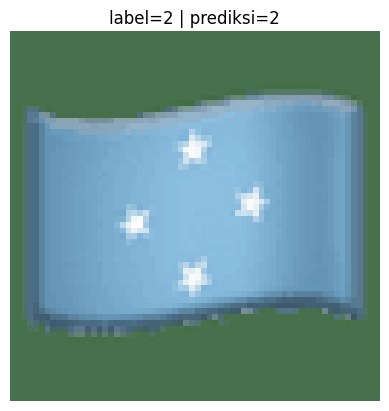

[TEST] size=64x64 | channels=3 | label=1 | prediksi=2 | idx =70


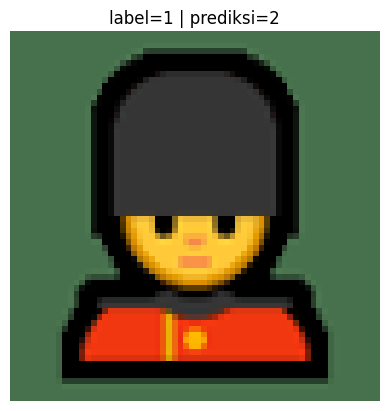

[TEST] size=64x64 | channels=3 | label=1 | prediksi=1 | idx =71


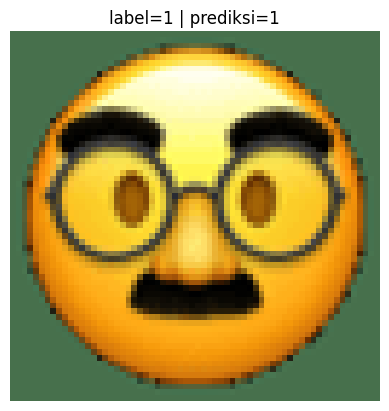

[TEST] size=64x64 | channels=3 | label=2 | prediksi=2 | idx =72


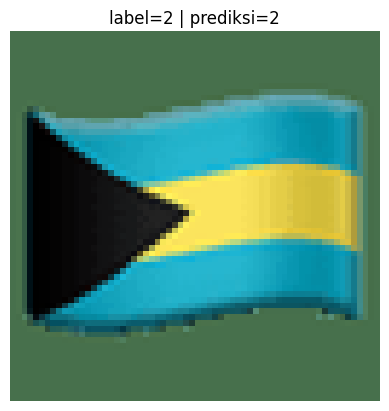

[TEST] size=64x64 | channels=3 | label=1 | prediksi=2 | idx =73


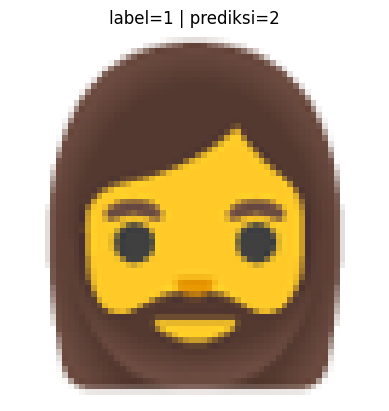

[TEST] size=64x64 | channels=3 | label=2 | prediksi=2 | idx =74


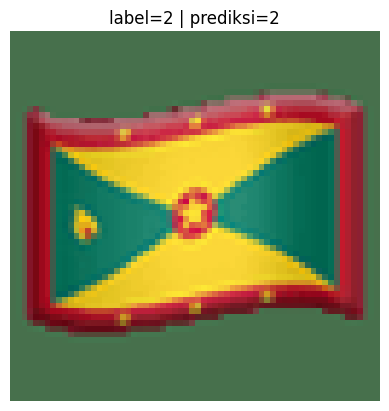

[TEST] size=64x64 | channels=3 | label=1 | prediksi=1 | idx =75


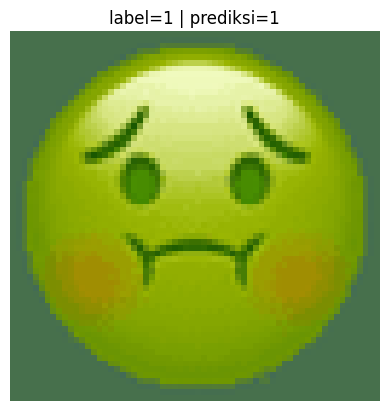

[TEST] size=64x64 | channels=3 | label=1 | prediksi=2 | idx =76


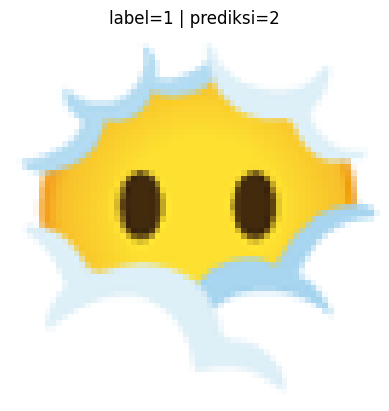

[TEST] size=64x64 | channels=3 | label=1 | prediksi=1 | idx =77


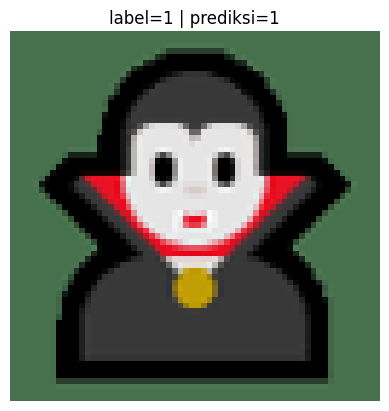

[TEST] size=64x64 | channels=3 | label=1 | prediksi=2 | idx =78


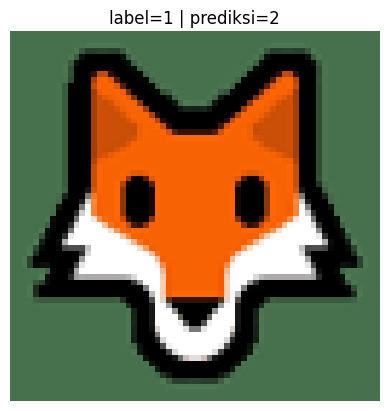

[TEST] size=64x64 | channels=3 | label=1 | prediksi=1 | idx =79


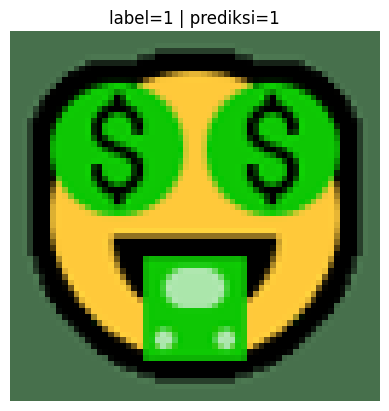

[TEST] size=64x64 | channels=3 | label=1 | prediksi=1 | idx =80


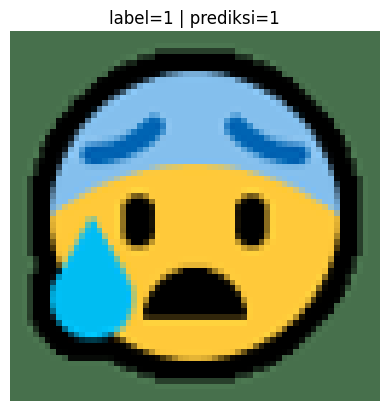

[TEST] size=64x64 | channels=3 | label=1 | prediksi=1 | idx =81


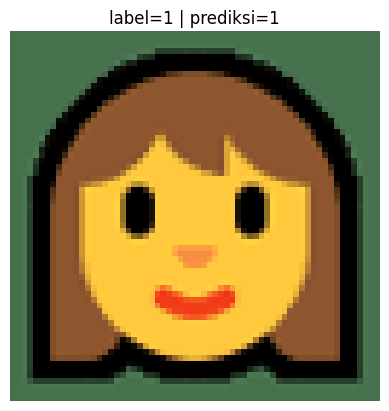

[TEST] size=64x64 | channels=3 | label=2 | prediksi=2 | idx =82


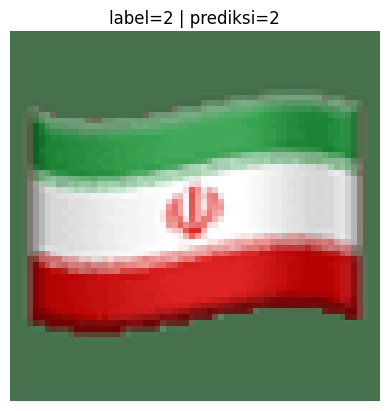

[TEST] size=64x64 | channels=3 | label=2 | prediksi=2 | idx =83


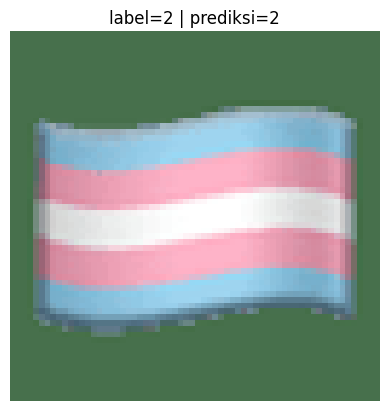

[TEST] size=64x64 | channels=3 | label=1 | prediksi=1 | idx =84


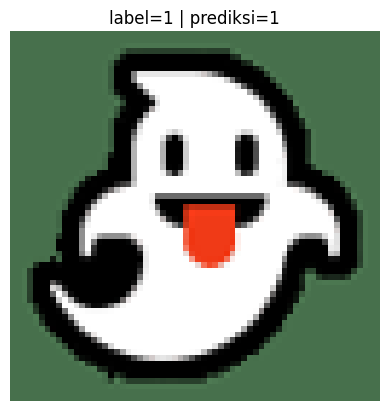

[TEST] size=64x64 | channels=3 | label=1 | prediksi=2 | idx =85


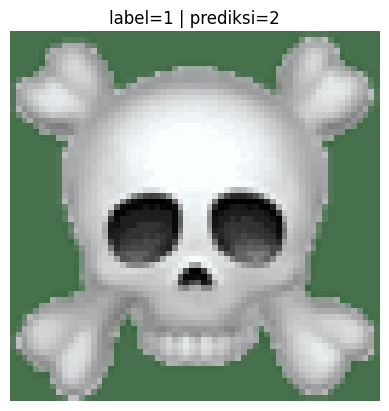

[TEST] size=64x64 | channels=3 | label=1 | prediksi=1 | idx =86


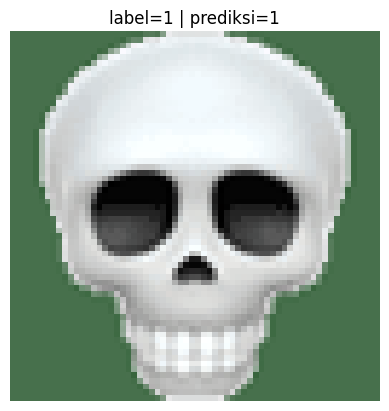

[TEST] size=64x64 | channels=3 | label=2 | prediksi=2 | idx =87


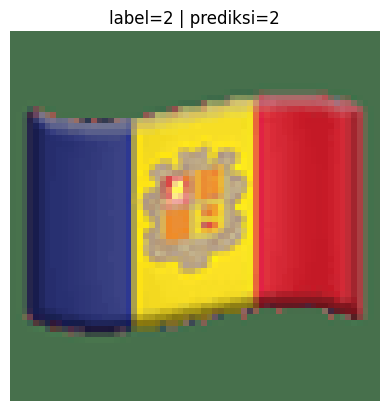

[TEST] size=64x64 | channels=3 | label=1 | prediksi=1 | idx =88


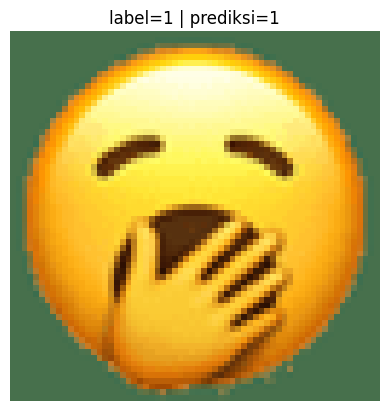

[TEST] size=64x64 | channels=3 | label=2 | prediksi=2 | idx =89


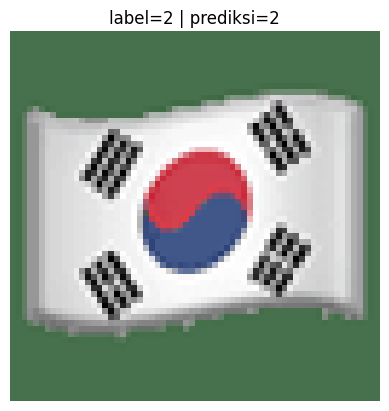

[TEST] size=64x64 | channels=3 | label=2 | prediksi=2 | idx =90


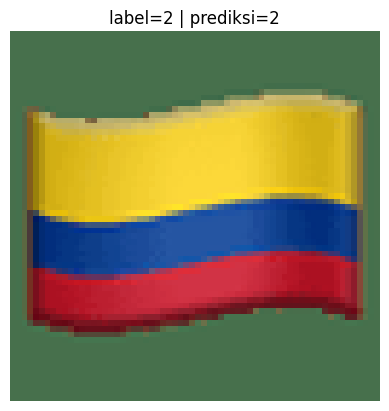

[TEST] size=64x64 | channels=3 | label=2 | prediksi=2 | idx =91


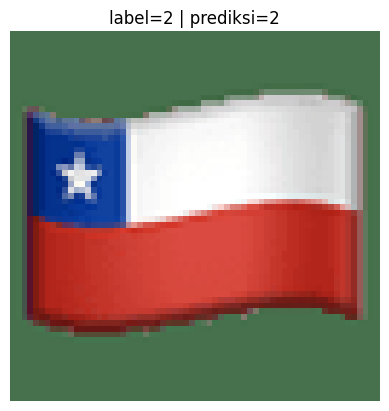

[TEST] size=64x64 | channels=3 | label=2 | prediksi=2 | idx =92


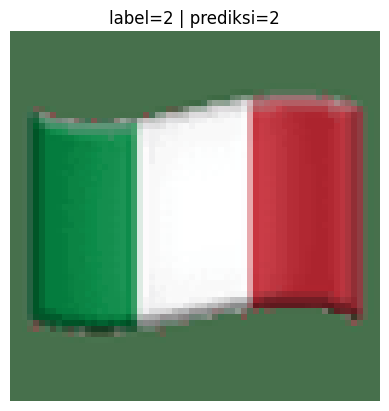

[TEST] size=64x64 | channels=3 | label=2 | prediksi=2 | idx =93


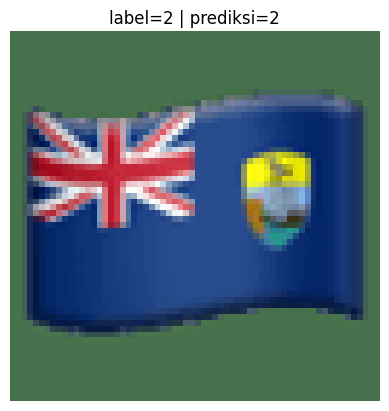

[TEST] size=64x64 | channels=3 | label=2 | prediksi=2 | idx =94


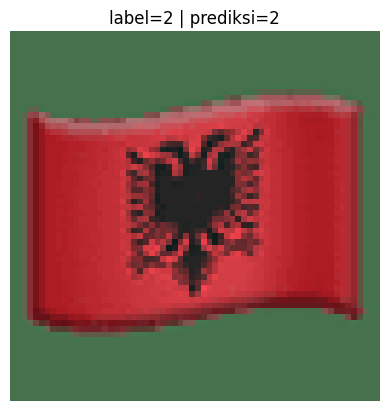

[TEST] size=64x64 | channels=3 | label=2 | prediksi=2 | idx =95


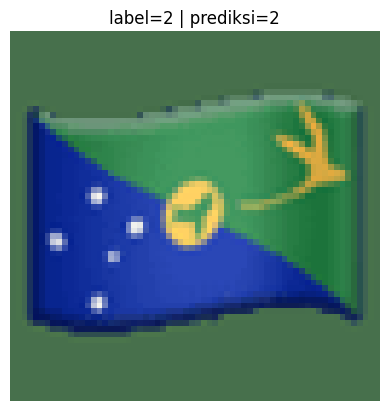

[TEST] size=64x64 | channels=3 | label=1 | prediksi=1 | idx =96


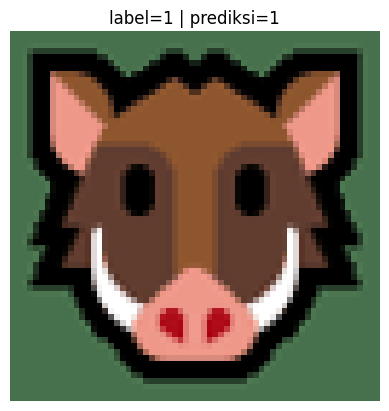

[TEST] size=64x64 | channels=3 | label=1 | prediksi=1 | idx =97


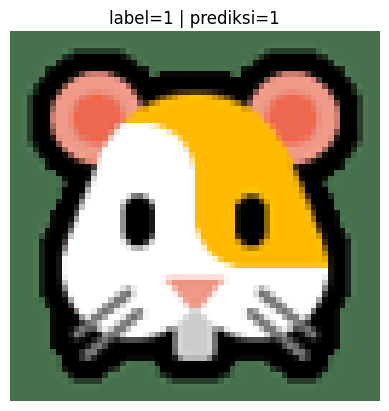

[TEST] size=64x64 | channels=3 | label=2 | prediksi=2 | idx =98


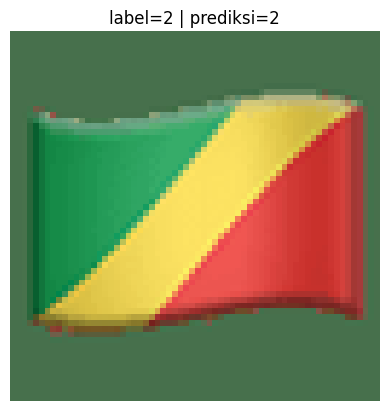

[TEST] size=64x64 | channels=3 | label=1 | prediksi=1 | idx =99


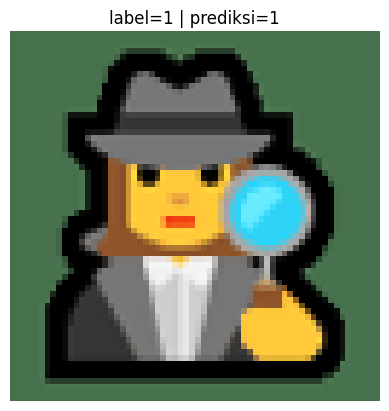

[TEST] size=64x64 | channels=3 | label=2 | prediksi=2 | idx =100


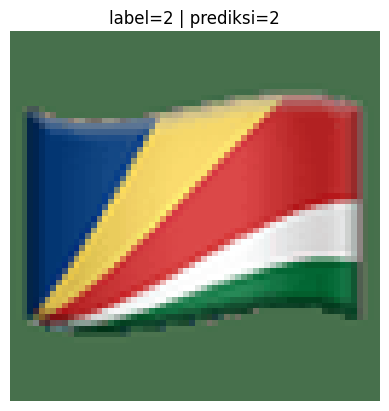

[TEST] size=64x64 | channels=3 | label=2 | prediksi=2 | idx =101


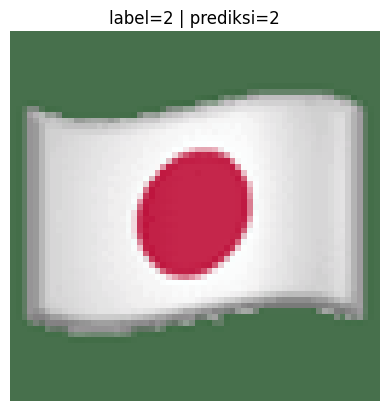

[TEST] size=64x64 | channels=3 | label=2 | prediksi=2 | idx =102


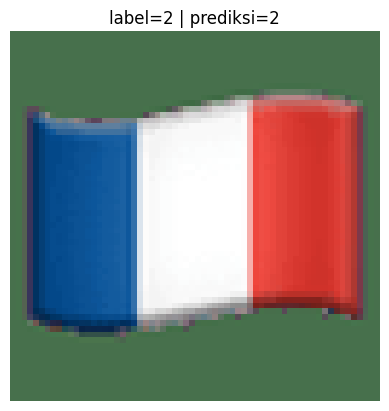

[TEST] size=64x64 | channels=3 | label=2 | prediksi=2 | idx =103


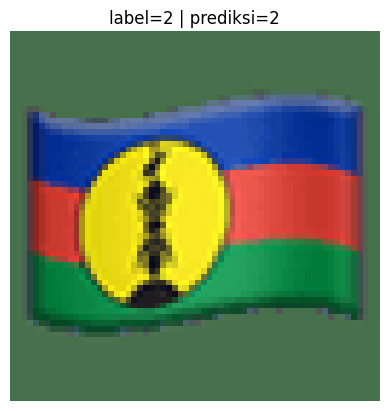

[TEST] size=64x64 | channels=3 | label=2 | prediksi=2 | idx =104


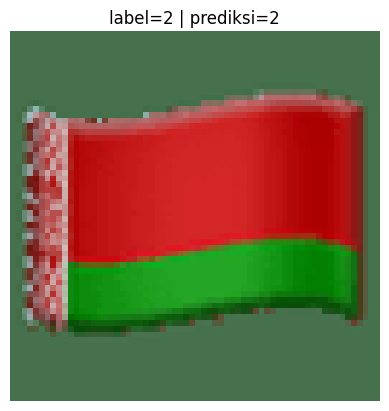

[TEST] size=64x64 | channels=3 | label=1 | prediksi=2 | idx =105


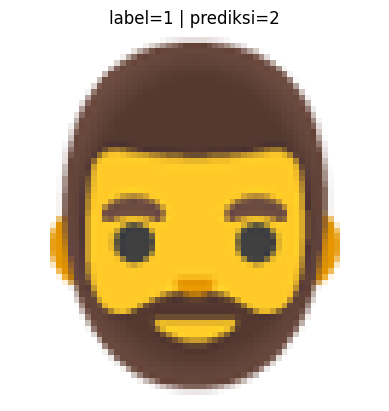

[TEST] size=64x64 | channels=3 | label=1 | prediksi=1 | idx =106


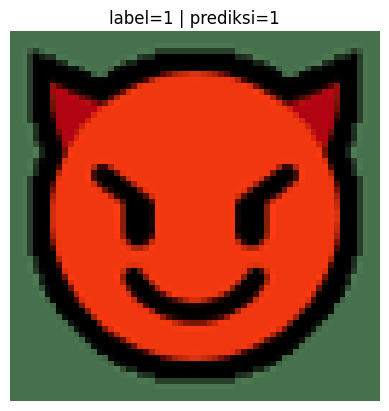

[TEST] size=64x64 | channels=3 | label=2 | prediksi=2 | idx =107


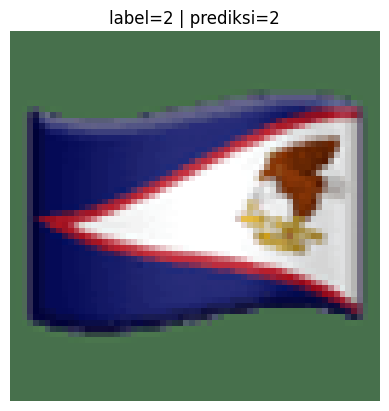

[TEST] size=64x64 | channels=3 | label=1 | prediksi=1 | idx =108


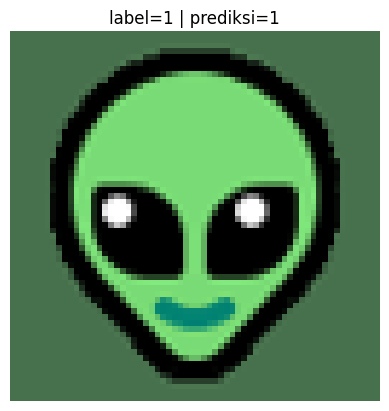

[TEST] size=64x64 | channels=3 | label=2 | prediksi=2 | idx =109


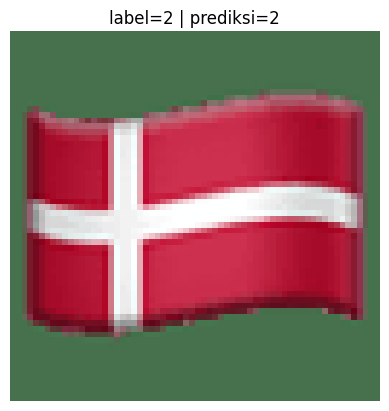

[TEST] size=64x64 | channels=3 | label=1 | prediksi=2 | idx =110


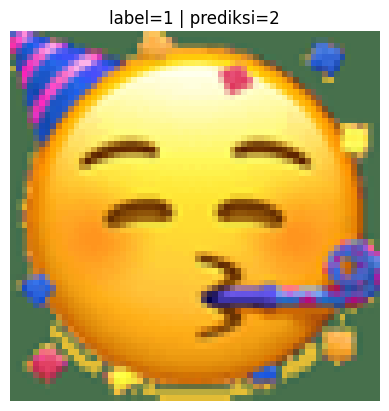

[TEST] size=64x64 | channels=3 | label=1 | prediksi=1 | idx =111


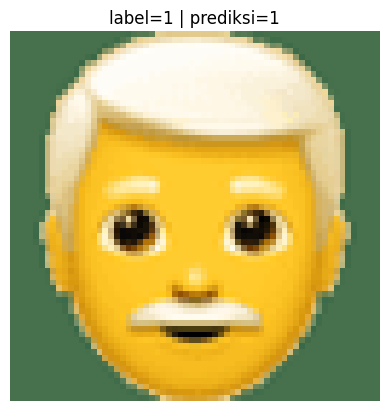

[TEST] size=64x64 | channels=3 | label=2 | prediksi=2 | idx =112


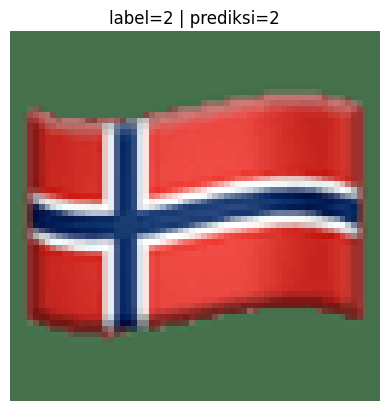

[TEST] size=64x64 | channels=3 | label=1 | prediksi=1 | idx =113


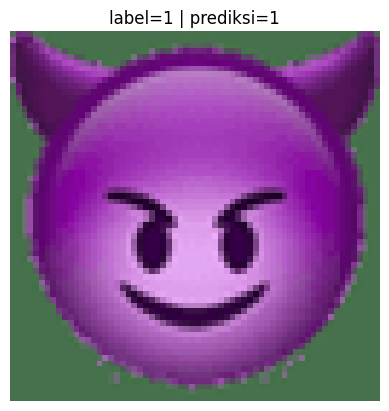

[TEST] size=64x64 | channels=3 | label=1 | prediksi=1 | idx =114


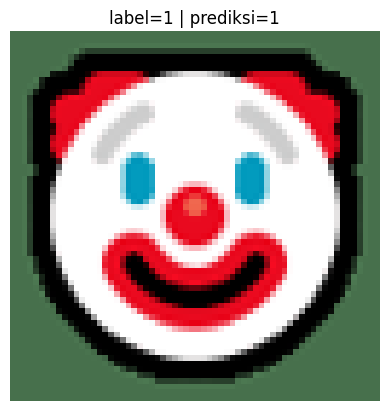

[TEST] size=64x64 | channels=3 | label=2 | prediksi=2 | idx =115


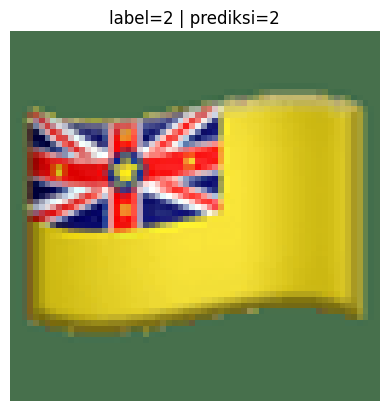

[TEST] size=64x64 | channels=3 | label=1 | prediksi=2 | idx =116


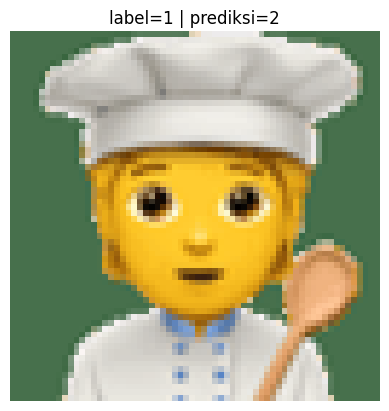

[TEST] size=64x64 | channels=3 | label=1 | prediksi=2 | idx =117


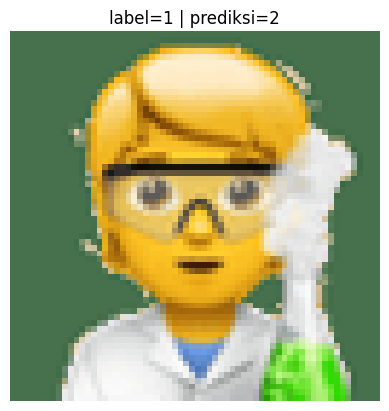

[TEST] size=64x64 | channels=3 | label=1 | prediksi=2 | idx =118


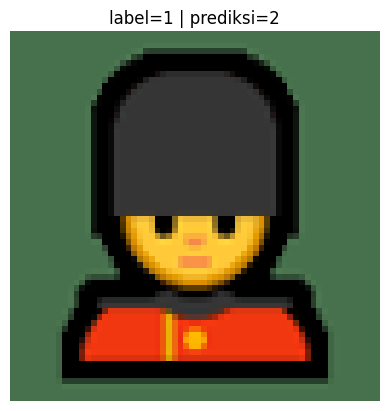

[TEST] size=64x64 | channels=3 | label=1 | prediksi=1 | idx =119


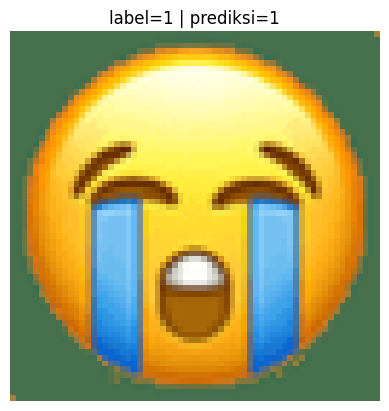

[TEST] size=64x64 | channels=3 | label=2 | prediksi=2 | idx =120


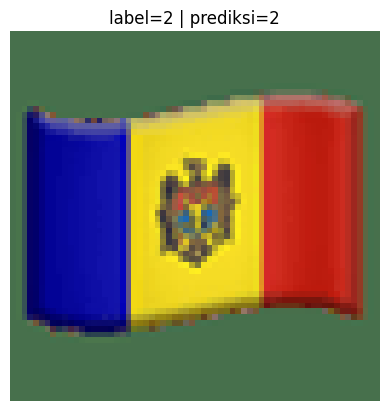

[TEST] size=64x64 | channels=3 | label=2 | prediksi=2 | idx =121


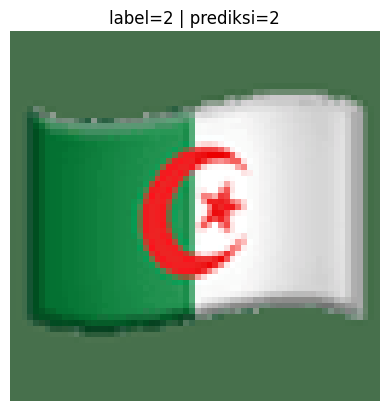

[TEST] size=64x64 | channels=3 | label=2 | prediksi=2 | idx =122


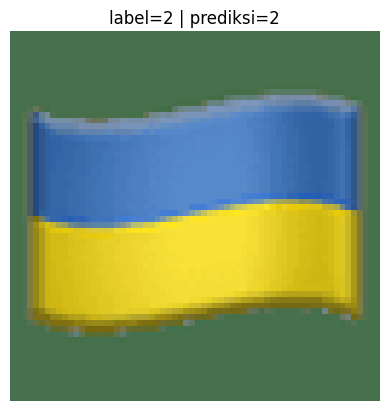

[TEST] size=64x64 | channels=3 | label=2 | prediksi=2 | idx =123


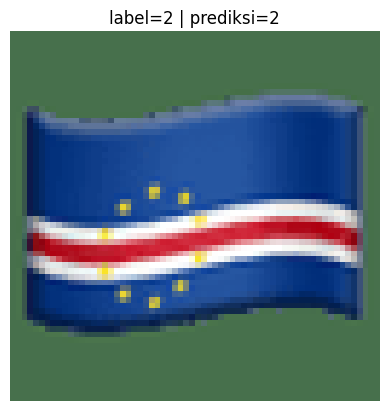

[TEST] size=64x64 | channels=3 | label=2 | prediksi=2 | idx =124


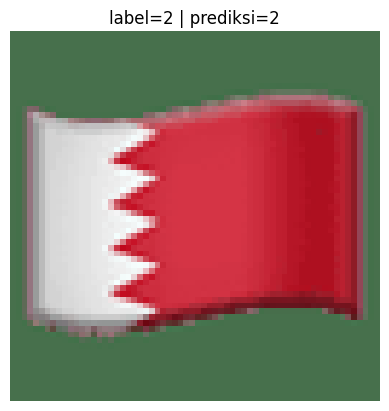

[TEST] size=64x64 | channels=3 | label=2 | prediksi=2 | idx =125


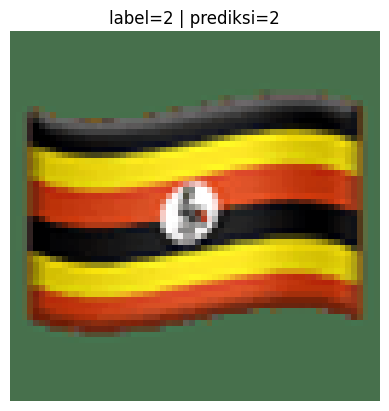

[TEST] size=64x64 | channels=3 | label=1 | prediksi=1 | idx =126


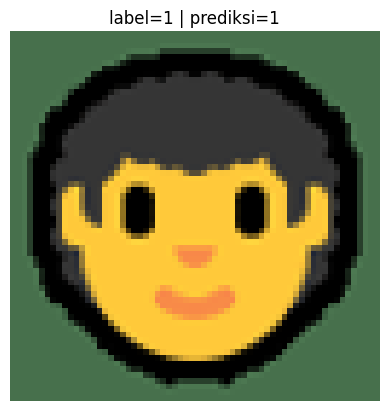

[TEST] size=64x64 | channels=3 | label=2 | prediksi=2 | idx =127


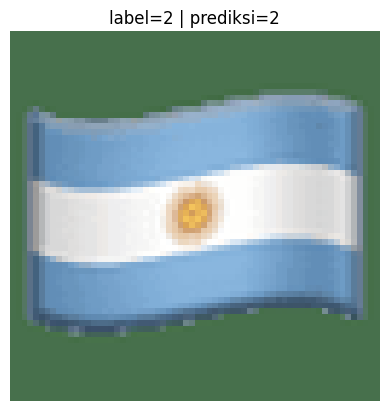

[TEST] size=64x64 | channels=3 | label=2 | prediksi=2 | idx =128


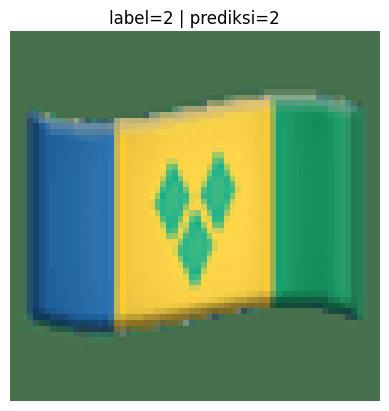

[TEST] size=64x64 | channels=3 | label=1 | prediksi=1 | idx =129


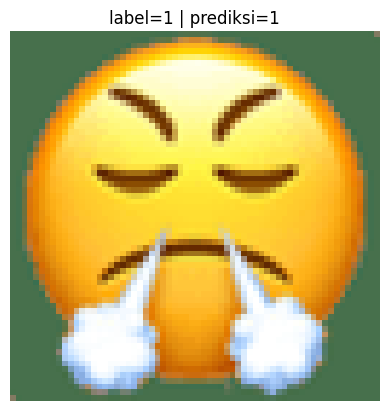

[TEST] size=64x64 | channels=3 | label=1 | prediksi=1 | idx =130


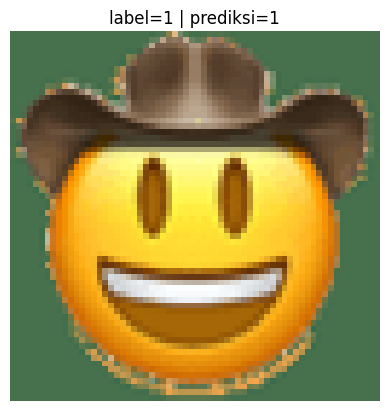

[TEST] size=64x64 | channels=3 | label=2 | prediksi=2 | idx =131


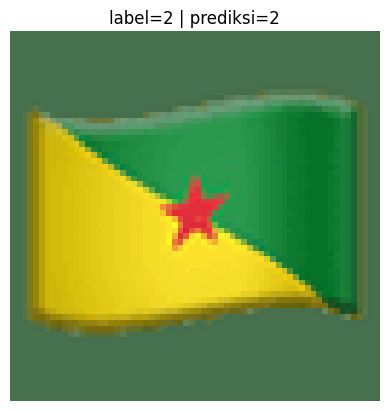

[TEST] size=64x64 | channels=3 | label=2 | prediksi=2 | idx =132


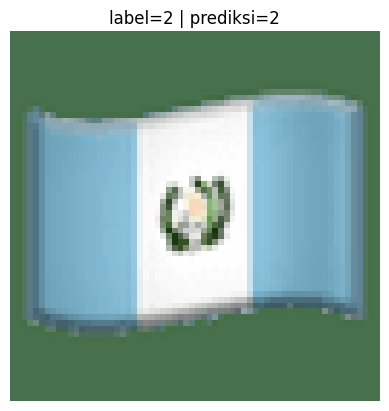

[TEST] size=64x64 | channels=3 | label=1 | prediksi=1 | idx =133


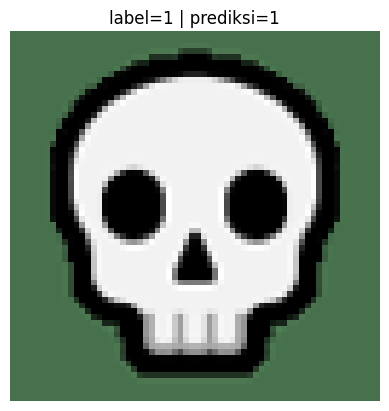

[TEST] size=64x64 | channels=3 | label=1 | prediksi=1 | idx =134


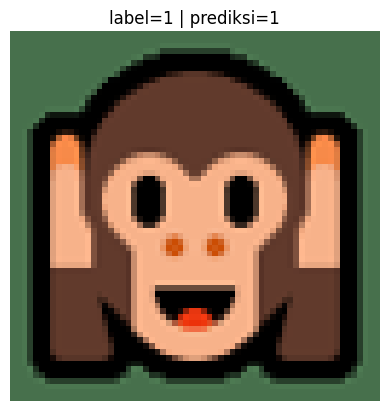

[TEST] size=64x64 | channels=3 | label=2 | prediksi=2 | idx =135


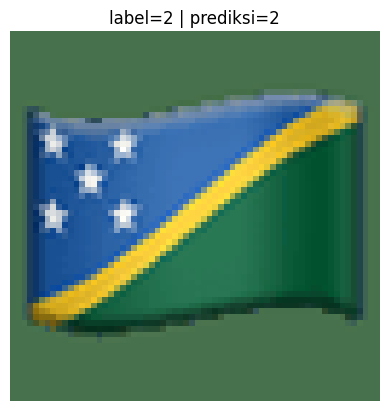

[TEST] size=64x64 | channels=3 | label=2 | prediksi=2 | idx =136


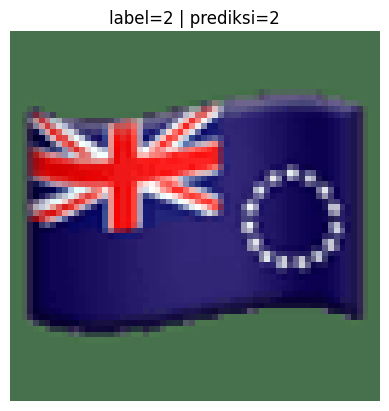

[TEST] size=64x64 | channels=3 | label=2 | prediksi=2 | idx =137


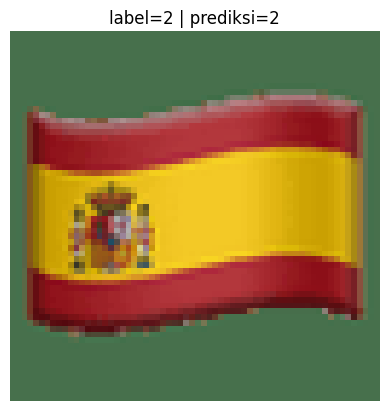

[TEST] size=64x64 | channels=3 | label=2 | prediksi=2 | idx =138


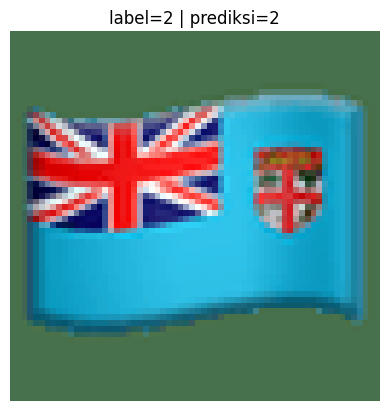

[TEST] size=64x64 | channels=3 | label=2 | prediksi=2 | idx =139


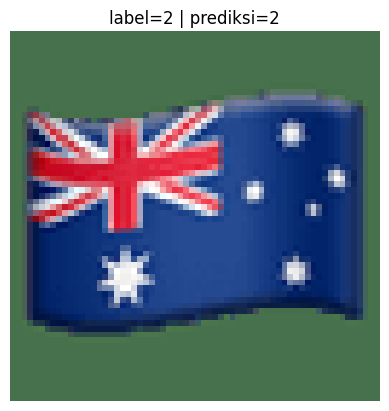

[TEST] size=64x64 | channels=3 | label=2 | prediksi=2 | idx =140


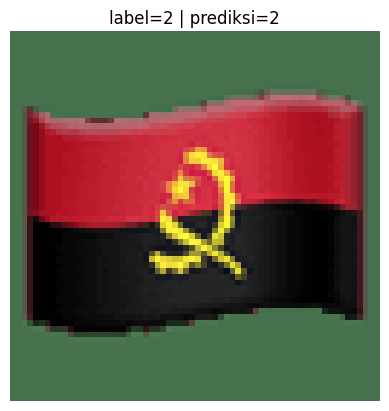

[TEST] size=64x64 | channels=3 | label=2 | prediksi=2 | idx =141


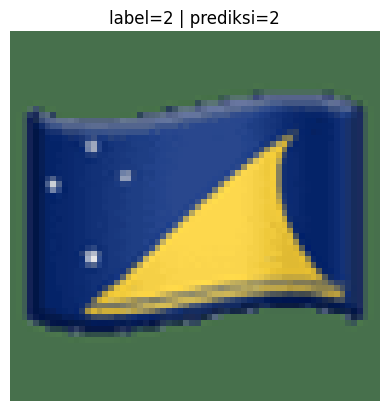

[TEST] size=64x64 | channels=3 | label=2 | prediksi=2 | idx =142


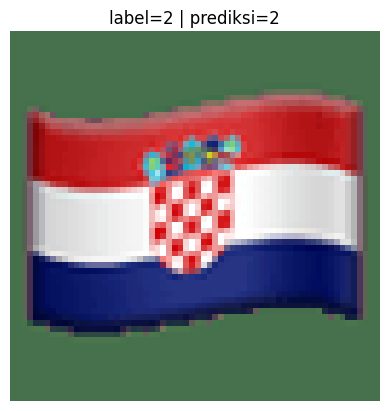

[TEST] size=64x64 | channels=3 | label=2 | prediksi=2 | idx =143


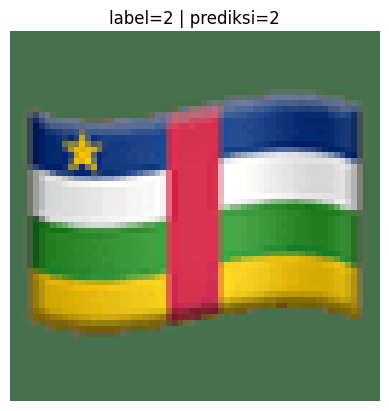

[TEST] size=64x64 | channels=3 | label=2 | prediksi=2 | idx =144


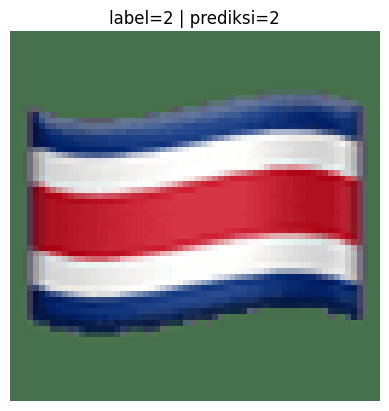

[TEST] size=64x64 | channels=3 | label=2 | prediksi=2 | idx =145


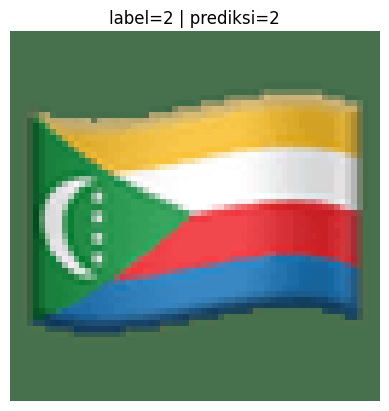

[TEST] size=64x64 | channels=3 | label=1 | prediksi=2 | idx =146


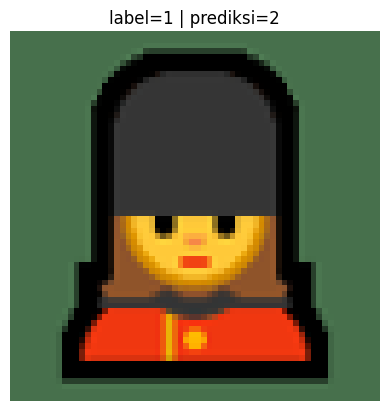

[TEST] size=64x64 | channels=3 | label=2 | prediksi=2 | idx =147


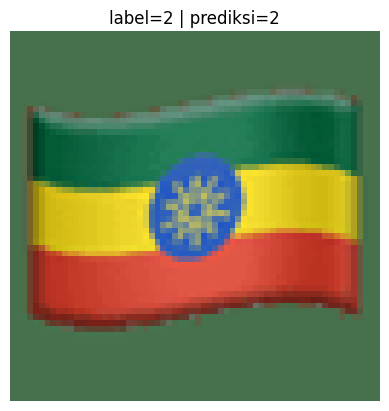

[TEST] size=64x64 | channels=3 | label=2 | prediksi=2 | idx =148


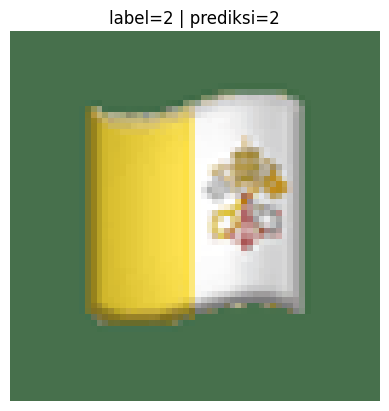

[TEST] size=64x64 | channels=3 | label=2 | prediksi=2 | idx =149


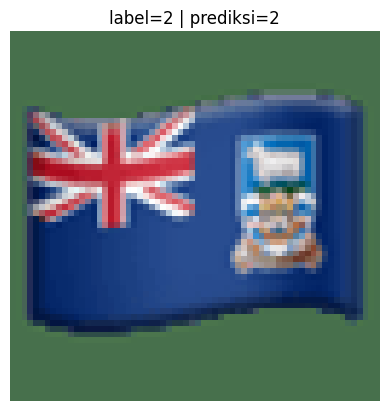

[TEST] size=64x64 | channels=3 | label=2 | prediksi=2 | idx =150


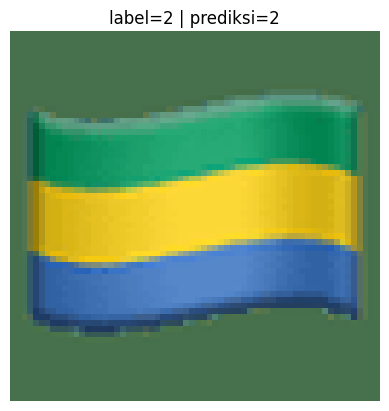

[TEST] size=64x64 | channels=3 | label=1 | prediksi=1 | idx =151


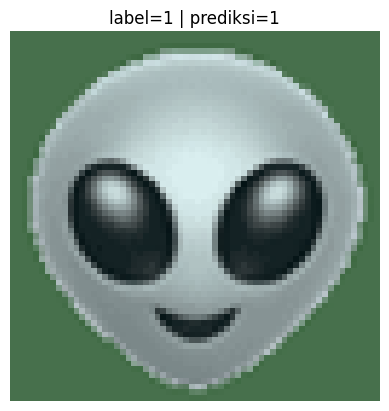

[TEST] size=64x64 | channels=3 | label=2 | prediksi=2 | idx =152


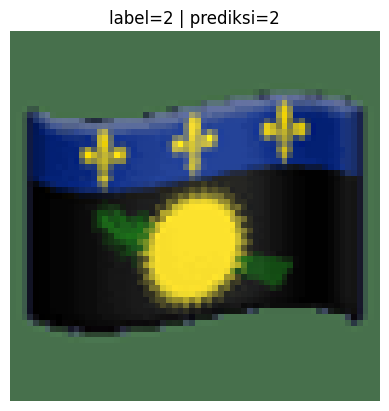

[TEST] size=64x64 | channels=3 | label=2 | prediksi=2 | idx =153


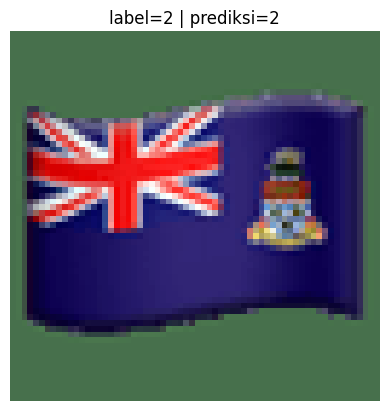

[TEST] size=64x64 | channels=3 | label=1 | prediksi=1 | idx =154


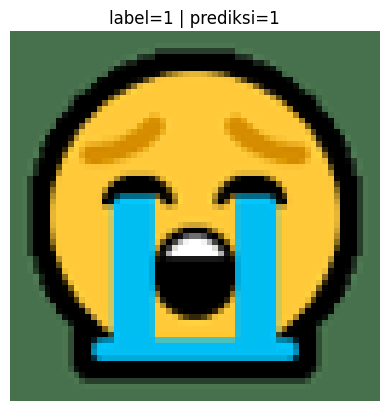

[TEST] size=64x64 | channels=3 | label=2 | prediksi=2 | idx =155


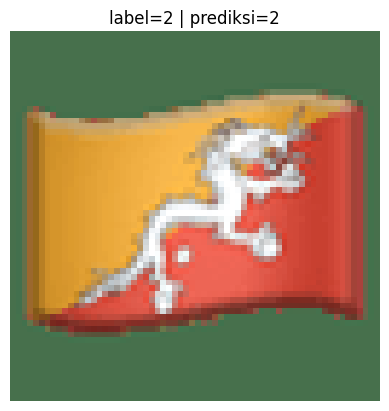

[TEST] size=64x64 | channels=3 | label=1 | prediksi=1 | idx =156


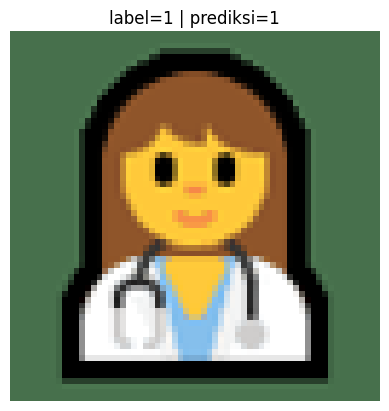

[TEST] size=64x64 | channels=3 | label=1 | prediksi=1 | idx =157


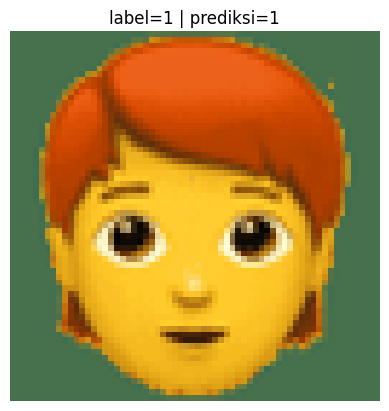

[TEST] size=64x64 | channels=3 | label=1 | prediksi=1 | idx =158


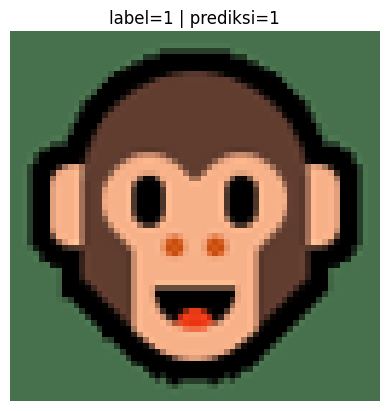

[TEST] size=64x64 | channels=3 | label=2 | prediksi=2 | idx =159


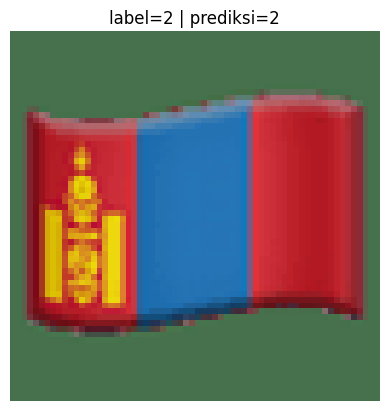

[TEST] size=64x64 | channels=3 | label=2 | prediksi=2 | idx =160


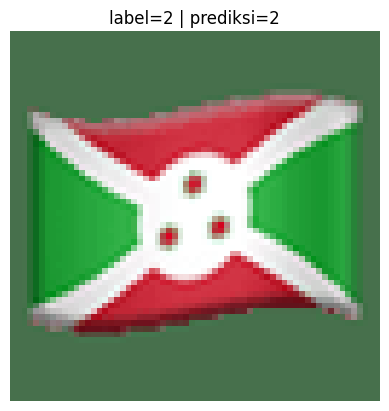

[TEST] size=64x64 | channels=3 | label=1 | prediksi=2 | idx =161


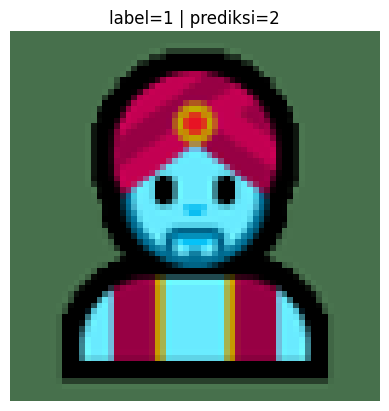

[TEST] size=64x64 | channels=3 | label=1 | prediksi=1 | idx =162


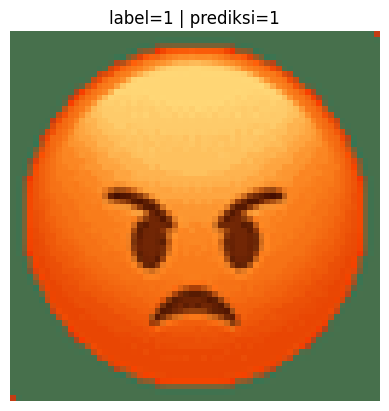

[TEST] size=64x64 | channels=3 | label=2 | prediksi=2 | idx =163


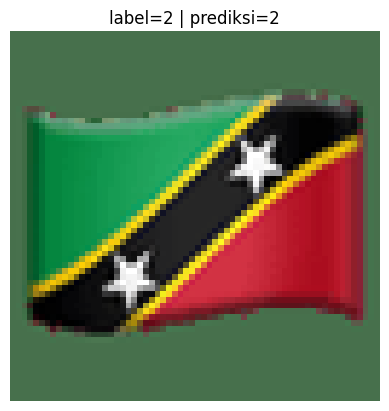

[TEST] size=64x64 | channels=3 | label=2 | prediksi=2 | idx =164


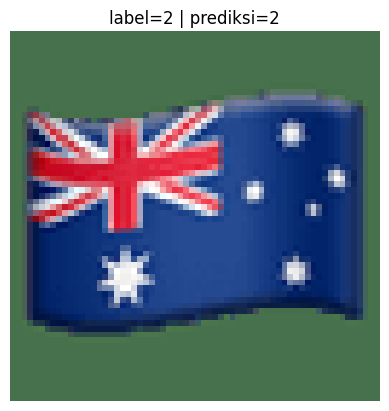

[TEST] size=64x64 | channels=3 | label=1 | prediksi=1 | idx =165


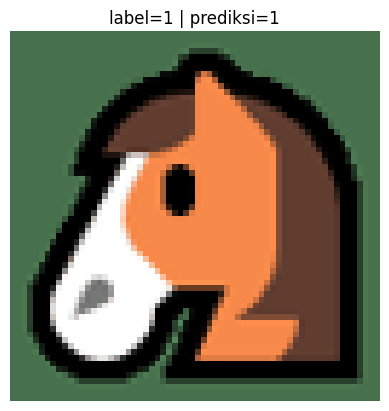

[TEST] size=64x64 | channels=3 | label=2 | prediksi=2 | idx =166


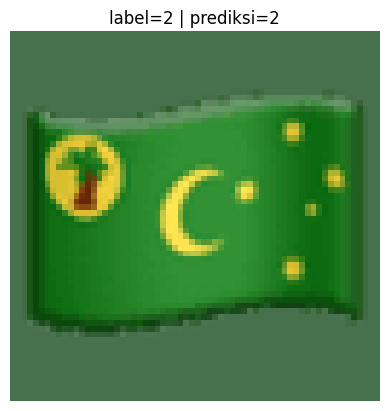

[TEST] size=64x64 | channels=3 | label=1 | prediksi=1 | idx =167


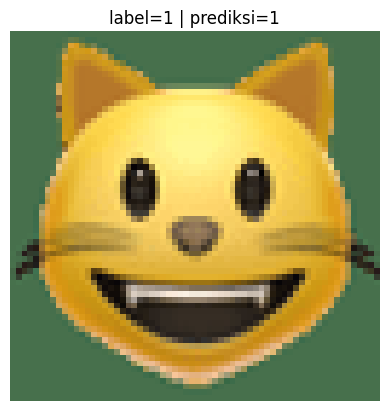

[TEST] size=64x64 | channels=3 | label=1 | prediksi=1 | idx =168


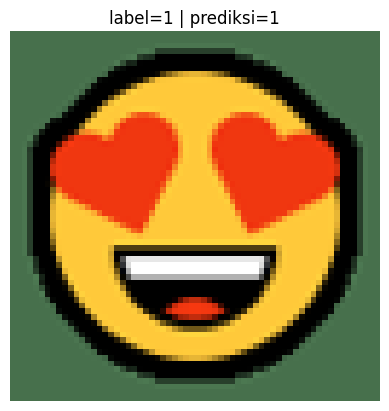

[TEST] size=64x64 | channels=3 | label=2 | prediksi=2 | idx =169


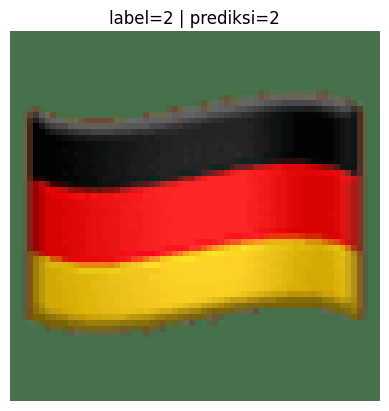

[TEST] size=64x64 | channels=3 | label=2 | prediksi=2 | idx =170


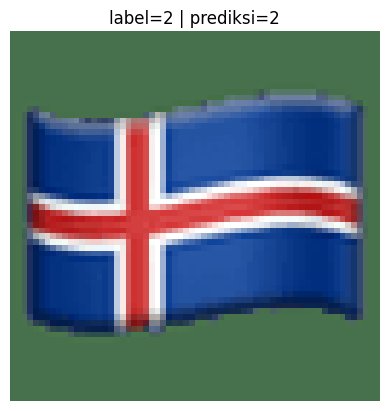

[TEST] size=64x64 | channels=3 | label=2 | prediksi=2 | idx =171


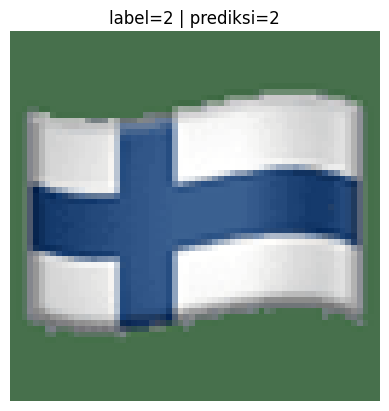

[TEST] size=64x64 | channels=3 | label=1 | prediksi=1 | idx =172


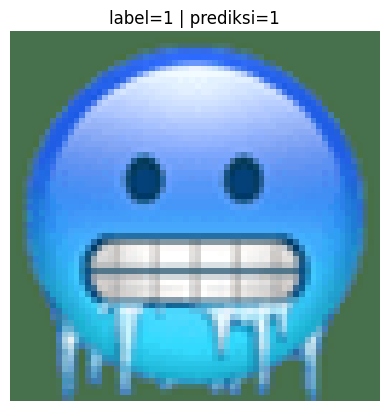

[TEST] size=64x64 | channels=3 | label=1 | prediksi=2 | idx =173


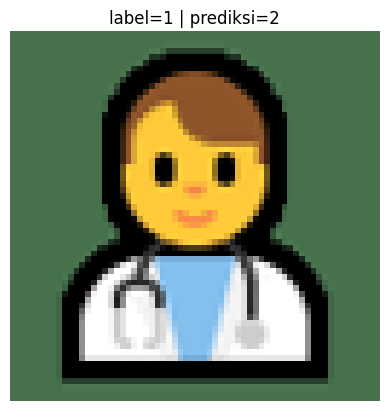

[TEST] size=64x64 | channels=3 | label=2 | prediksi=2 | idx =174


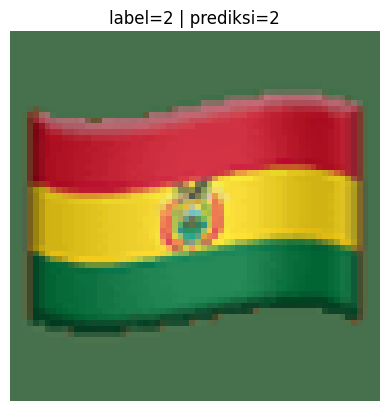

[TEST] size=64x64 | channels=3 | label=1 | prediksi=1 | idx =175


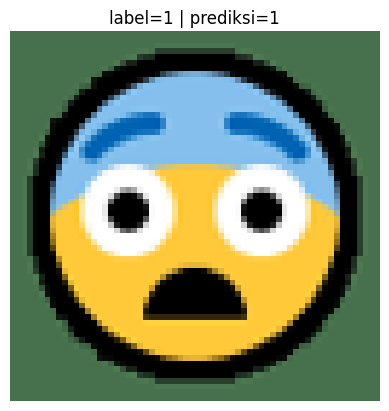

[TEST] size=64x64 | channels=3 | label=2 | prediksi=2 | idx =176


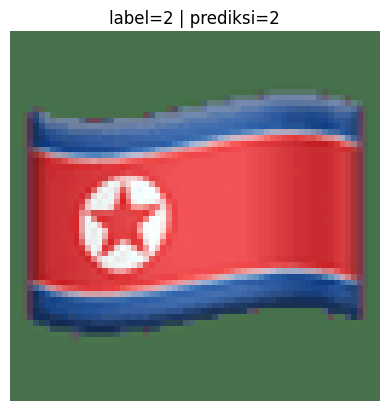

[TEST] size=64x64 | channels=3 | label=2 | prediksi=2 | idx =177


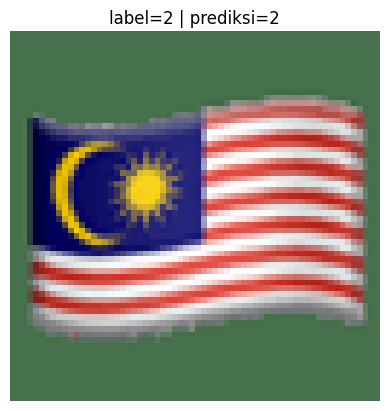

[TEST] size=64x64 | channels=3 | label=1 | prediksi=2 | idx =178


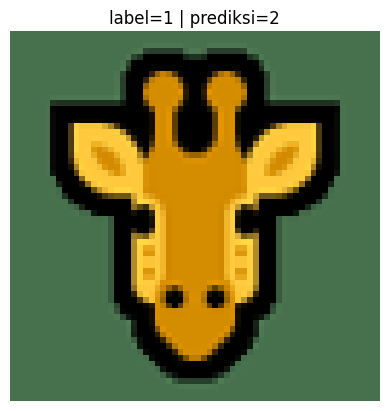

[TEST] size=64x64 | channels=3 | label=2 | prediksi=2 | idx =179


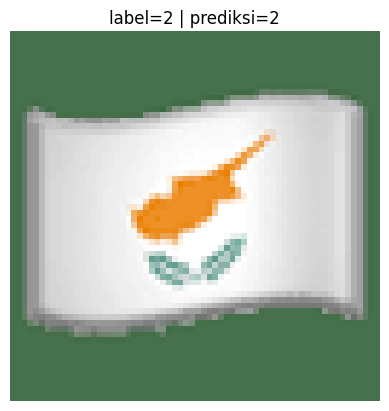

[TEST] size=64x64 | channels=3 | label=1 | prediksi=1 | idx =180


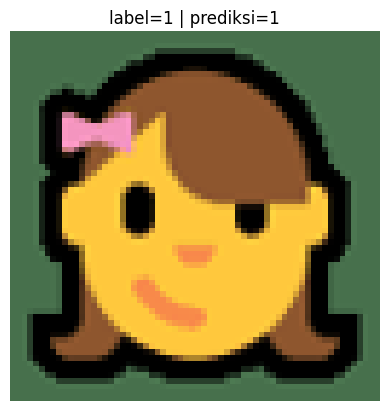

[TEST] size=64x64 | channels=3 | label=2 | prediksi=2 | idx =181


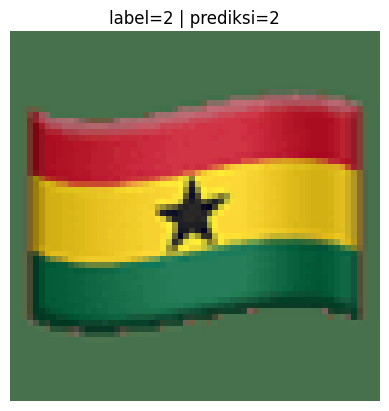

[TEST] size=64x64 | channels=3 | label=2 | prediksi=2 | idx =182


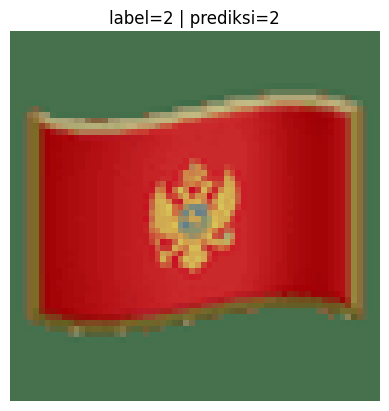

[TEST] size=64x64 | channels=3 | label=1 | prediksi=1 | idx =183


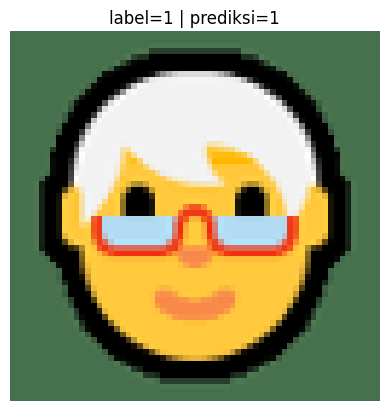

[TEST] size=64x64 | channels=3 | label=1 | prediksi=1 | idx =184


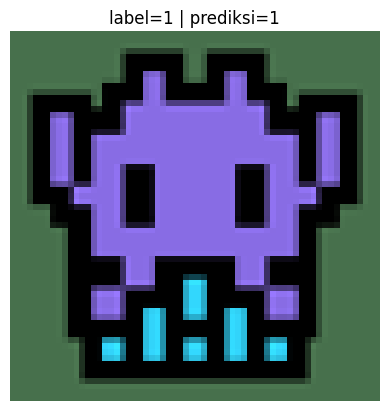

[TEST] size=64x64 | channels=3 | label=1 | prediksi=1 | idx =185


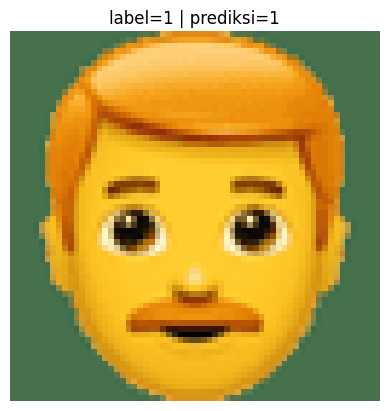

[TEST] size=64x64 | channels=3 | label=1 | prediksi=1 | idx =186


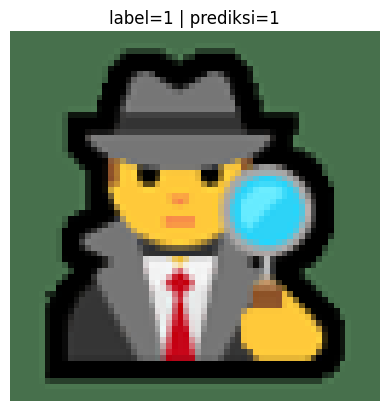

[TEST] size=64x64 | channels=3 | label=1 | prediksi=1 | idx =187


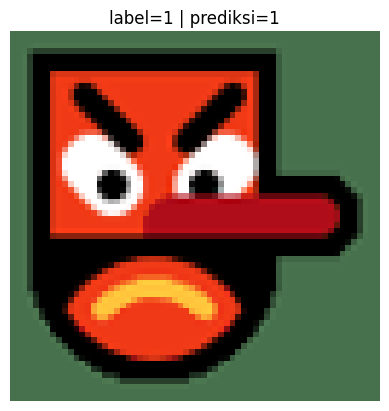

[TEST] size=64x64 | channels=3 | label=2 | prediksi=2 | idx =188


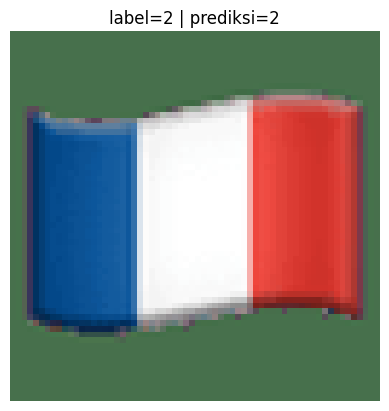

[TEST] size=64x64 | channels=3 | label=1 | prediksi=1 | idx =189


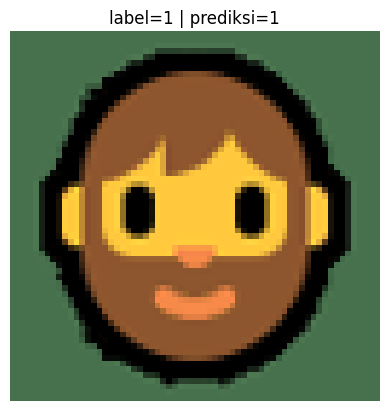

[TEST] size=64x64 | channels=3 | label=2 | prediksi=2 | idx =190


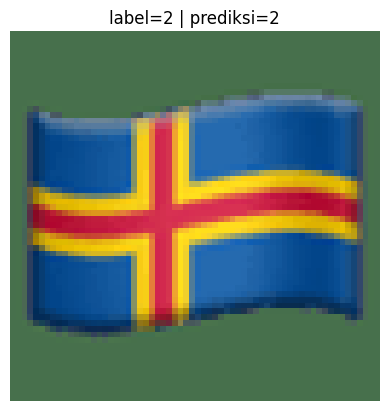

[TEST] size=64x64 | channels=3 | label=2 | prediksi=2 | idx =191


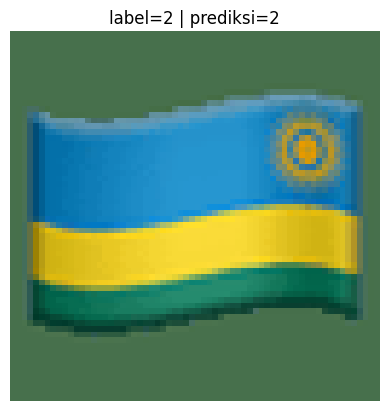

[TEST] size=64x64 | channels=3 | label=1 | prediksi=1 | idx =192


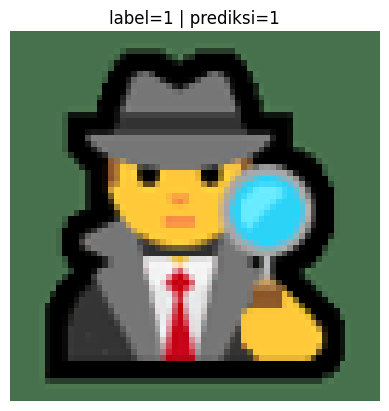

[TEST] size=64x64 | channels=3 | label=1 | prediksi=1 | idx =193


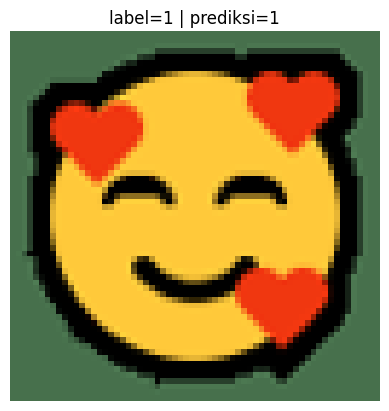

[TEST] size=64x64 | channels=3 | label=1 | prediksi=1 | idx =194


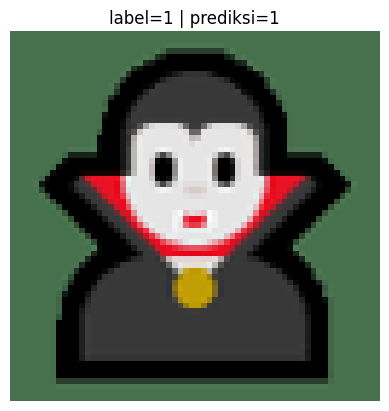

[TEST] size=64x64 | channels=3 | label=2 | prediksi=2 | idx =195


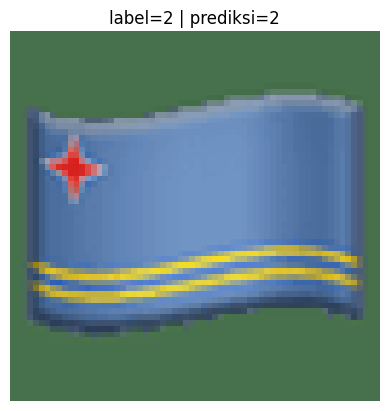

[TEST] size=64x64 | channels=3 | label=1 | prediksi=2 | idx =196


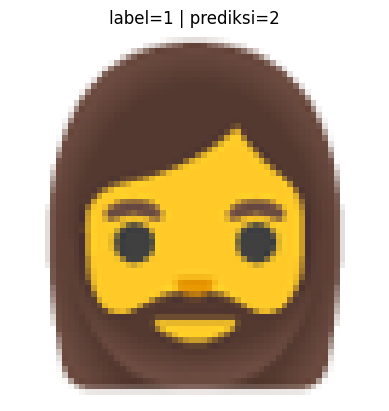

[TEST] size=64x64 | channels=3 | label=1 | prediksi=1 | idx =197


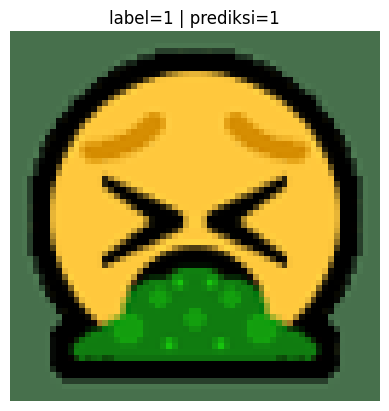

[TEST] size=64x64 | channels=3 | label=2 | prediksi=2 | idx =198


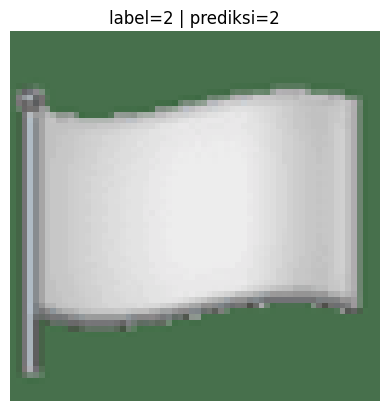

[TEST] size=64x64 | channels=3 | label=2 | prediksi=2 | idx =199


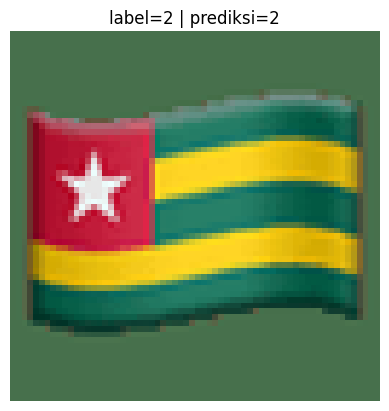

[TEST] size=64x64 | channels=3 | label=2 | prediksi=2 | idx =200


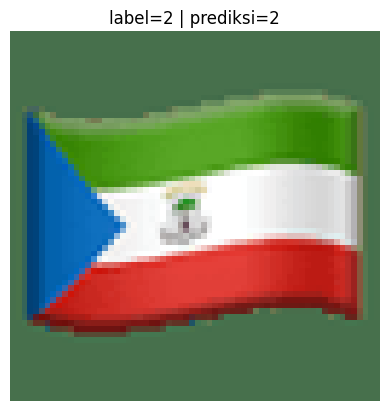

[TEST] size=64x64 | channels=3 | label=1 | prediksi=1 | idx =201


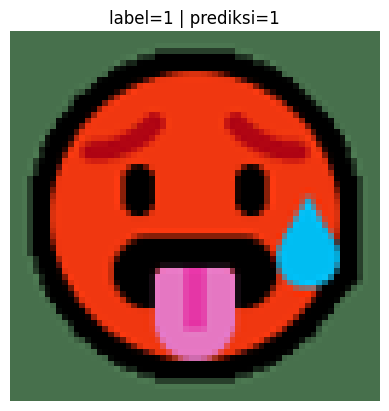

[TEST] size=64x64 | channels=3 | label=1 | prediksi=1 | idx =202


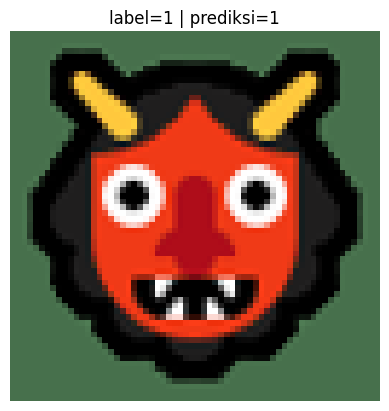

[TEST] size=64x64 | channels=3 | label=1 | prediksi=1 | idx =203


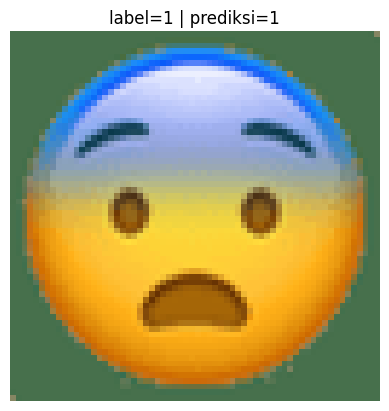

[TEST] size=64x64 | channels=3 | label=1 | prediksi=2 | idx =204


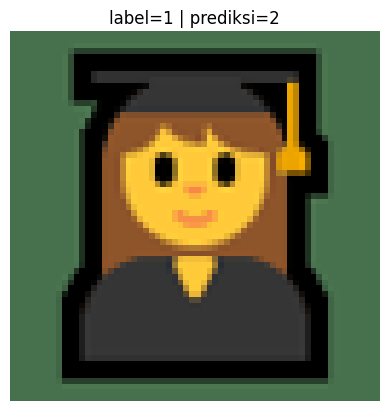

[TEST] size=64x64 | channels=3 | label=2 | prediksi=2 | idx =205


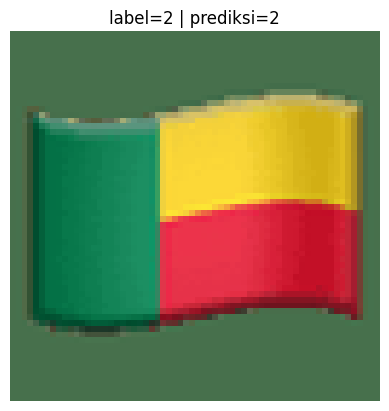

[TEST] size=64x64 | channels=3 | label=2 | prediksi=2 | idx =206


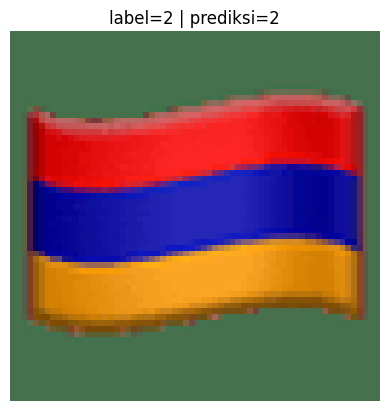

[TEST] size=64x64 | channels=3 | label=1 | prediksi=1 | idx =207


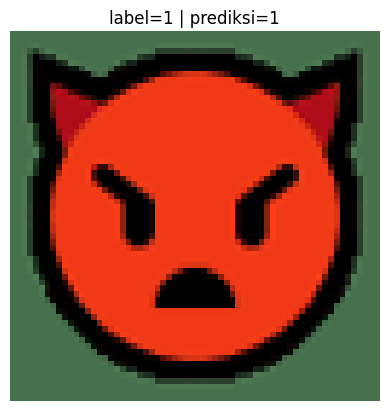

[TEST] size=64x64 | channels=3 | label=2 | prediksi=2 | idx =208


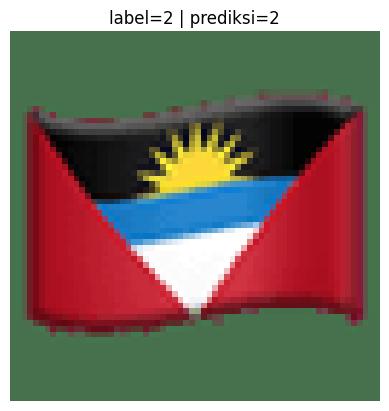

[TEST] size=64x64 | channels=3 | label=2 | prediksi=2 | idx =209


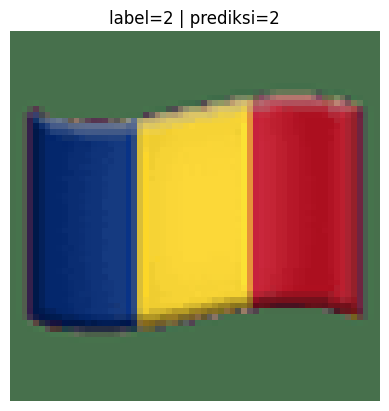

[TEST] size=64x64 | channels=3 | label=1 | prediksi=1 | idx =210


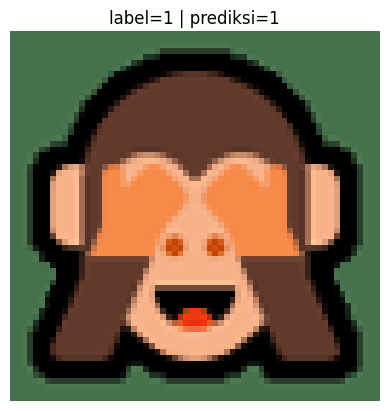

[TEST] size=64x64 | channels=3 | label=2 | prediksi=2 | idx =211


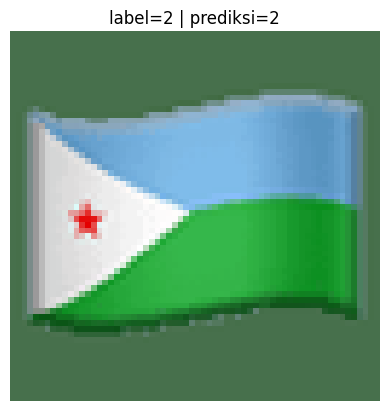

[TEST] size=64x64 | channels=3 | label=1 | prediksi=1 | idx =212


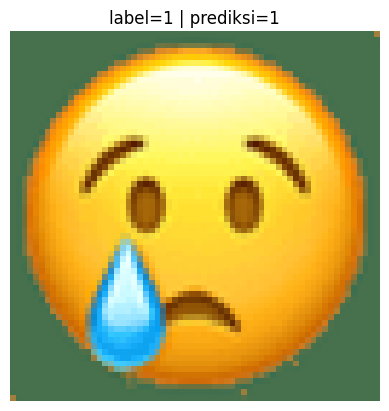

[TEST] size=64x64 | channels=3 | label=1 | prediksi=1 | idx =213


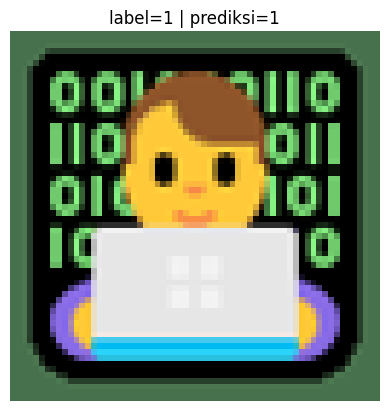

[TEST] size=64x64 | channels=3 | label=1 | prediksi=2 | idx =214


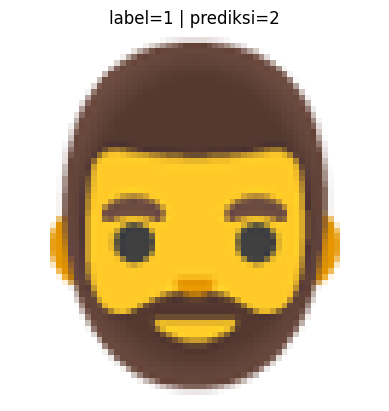

[TEST] size=64x64 | channels=3 | label=2 | prediksi=2 | idx =215


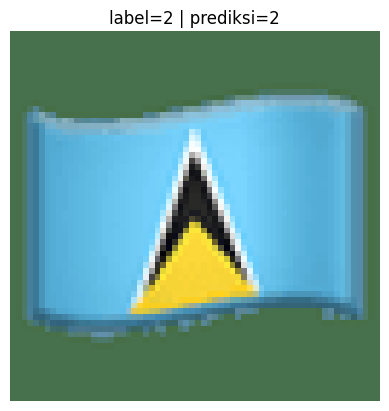

[TEST] size=64x64 | channels=3 | label=2 | prediksi=2 | idx =216


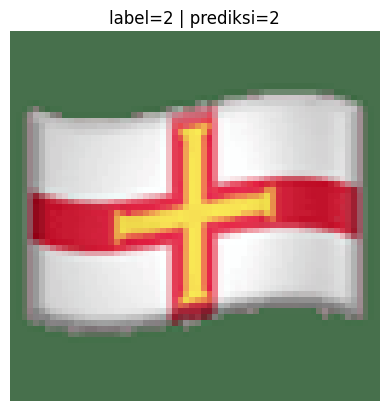

[TEST] size=64x64 | channels=3 | label=2 | prediksi=2 | idx =217


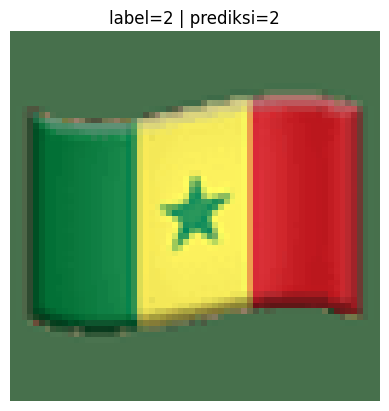

[TEST] size=64x64 | channels=3 | label=1 | prediksi=1 | idx =218


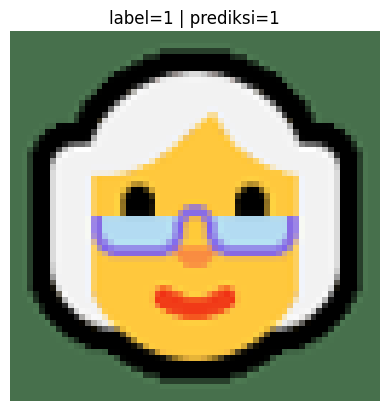

[TEST] size=64x64 | channels=3 | label=1 | prediksi=1 | idx =219


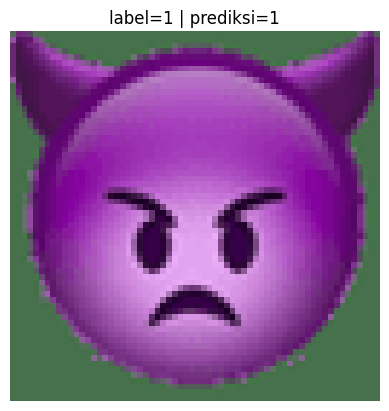

[TEST] size=64x64 | channels=3 | label=2 | prediksi=2 | idx =220


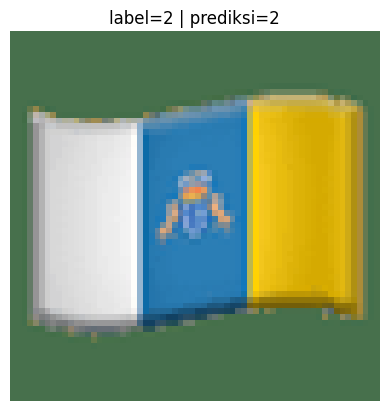

[TEST] size=64x64 | channels=3 | label=2 | prediksi=2 | idx =221


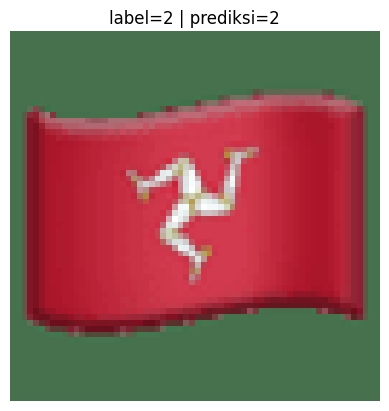

[TEST] size=64x64 | channels=3 | label=2 | prediksi=2 | idx =222


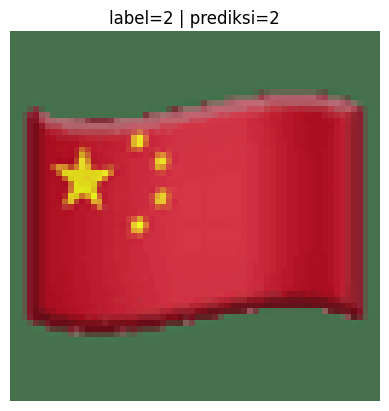

[TEST] size=64x64 | channels=3 | label=2 | prediksi=2 | idx =223


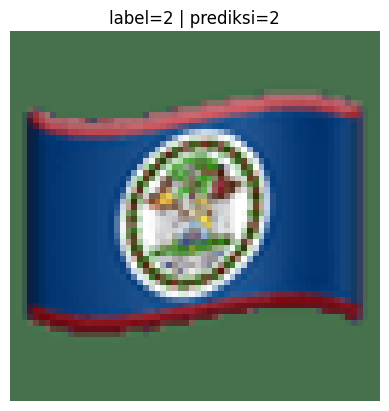

[TEST] size=64x64 | channels=3 | label=2 | prediksi=2 | idx =224


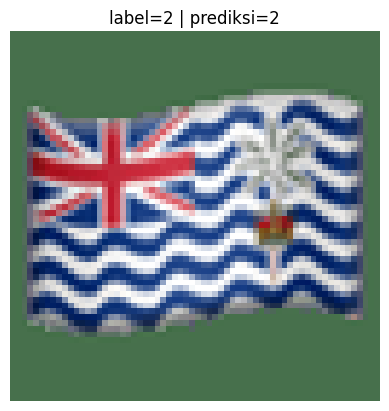

[TEST] size=64x64 | channels=3 | label=2 | prediksi=2 | idx =225


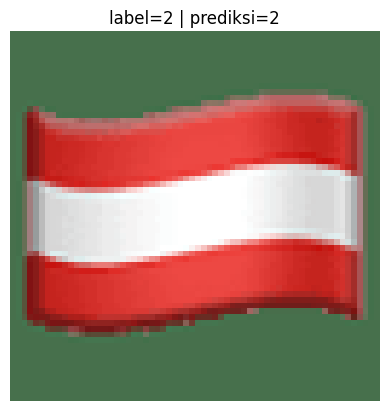

[TEST] size=64x64 | channels=3 | label=2 | prediksi=2 | idx =226


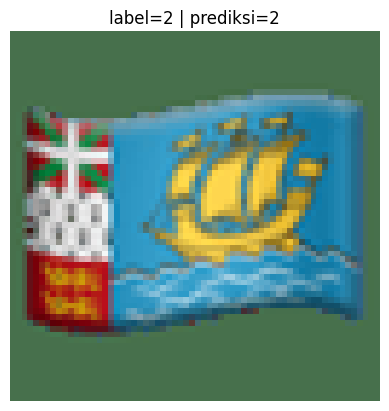

[TEST] size=64x64 | channels=3 | label=1 | prediksi=1 | idx =227


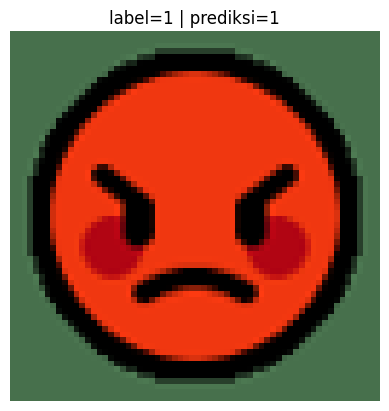

[TEST] size=64x64 | channels=3 | label=1 | prediksi=1 | idx =228


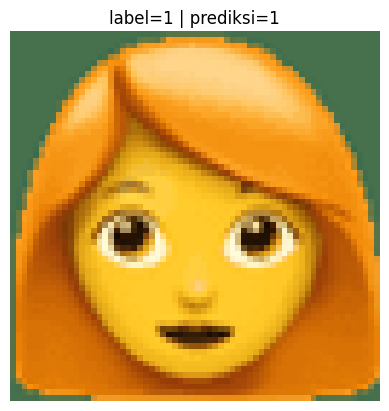

[TEST] size=64x64 | channels=3 | label=2 | prediksi=2 | idx =229


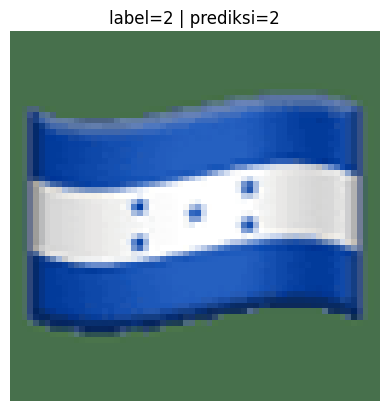

[TEST] size=64x64 | channels=3 | label=1 | prediksi=1 | idx =230


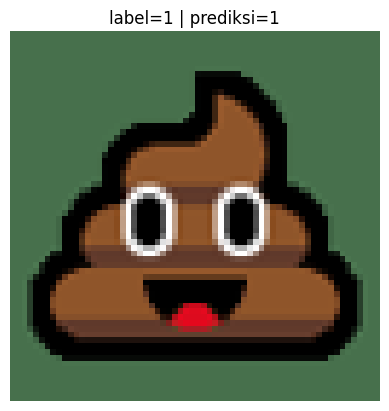

[TEST] size=64x64 | channels=3 | label=2 | prediksi=2 | idx =231


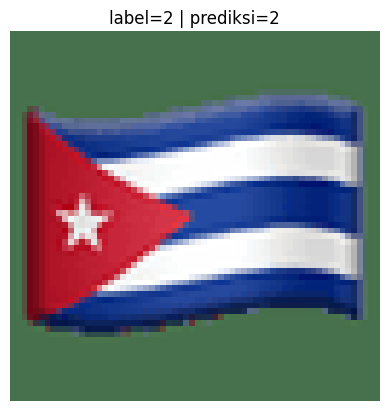

[TEST] size=64x64 | channels=3 | label=1 | prediksi=1 | idx =232


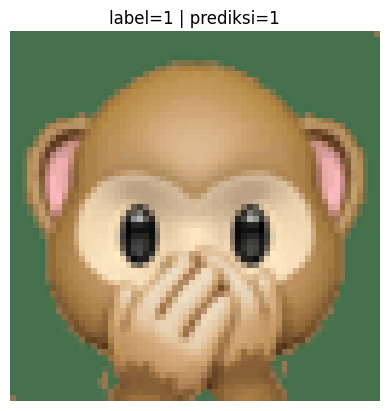

[TEST] size=64x64 | channels=3 | label=2 | prediksi=2 | idx =233


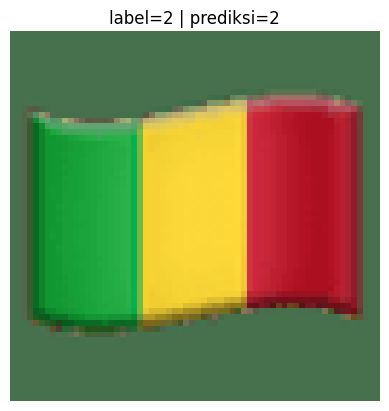

[TEST] size=64x64 | channels=3 | label=2 | prediksi=2 | idx =234


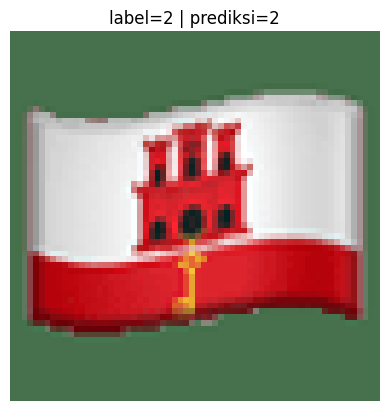

[TEST] size=64x64 | channels=3 | label=1 | prediksi=1 | idx =235


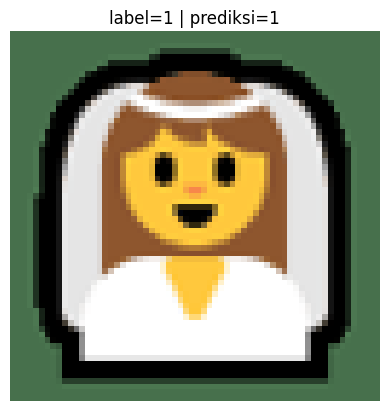

[TEST] size=64x64 | channels=3 | label=1 | prediksi=1 | idx =236


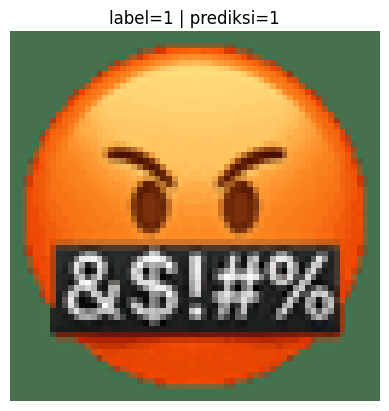

[TEST] size=64x64 | channels=3 | label=2 | prediksi=2 | idx =237


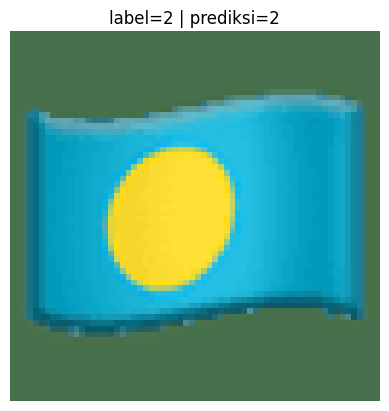

[TEST] size=64x64 | channels=3 | label=2 | prediksi=2 | idx =238


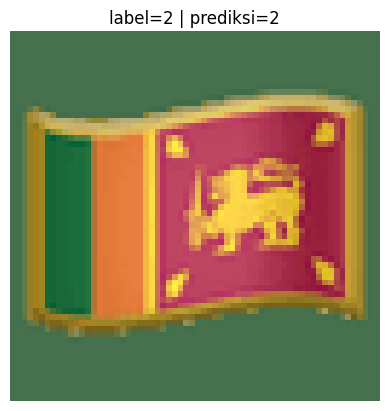

[TEST] size=64x64 | channels=3 | label=2 | prediksi=2 | idx =239


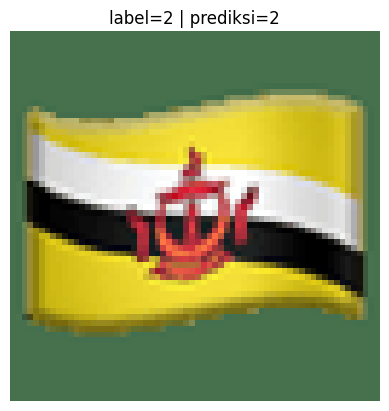

[TEST] size=64x64 | channels=3 | label=2 | prediksi=2 | idx =240


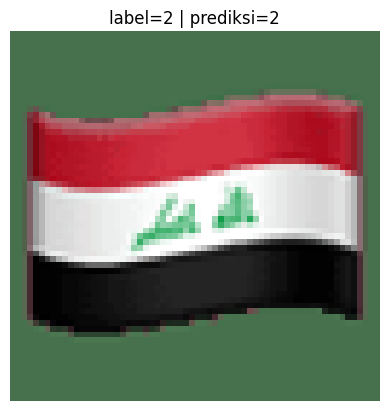

[TEST] size=64x64 | channels=3 | label=1 | prediksi=1 | idx =241


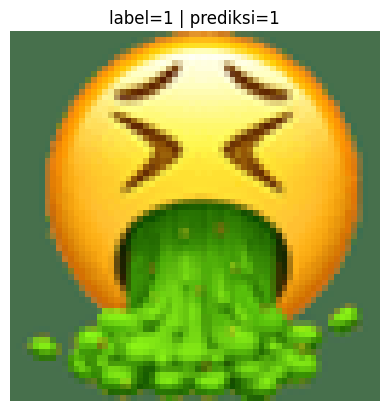

[TEST] size=64x64 | channels=3 | label=1 | prediksi=1 | idx =242


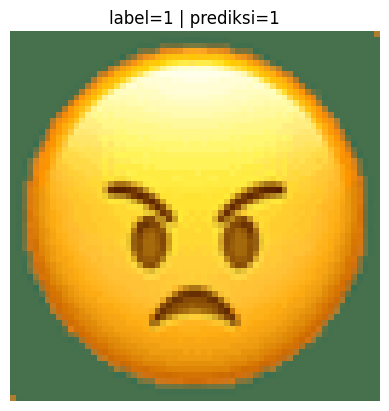

[TEST] size=64x64 | channels=3 | label=1 | prediksi=1 | idx =243


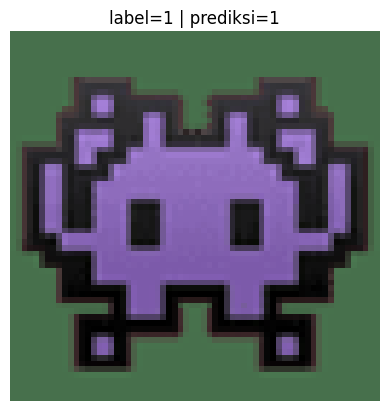

[TEST] size=64x64 | channels=3 | label=2 | prediksi=2 | idx =244


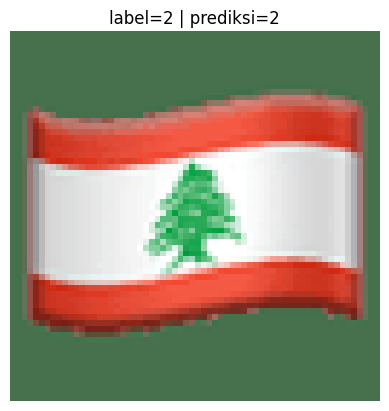

[TEST] size=64x64 | channels=3 | label=2 | prediksi=2 | idx =245


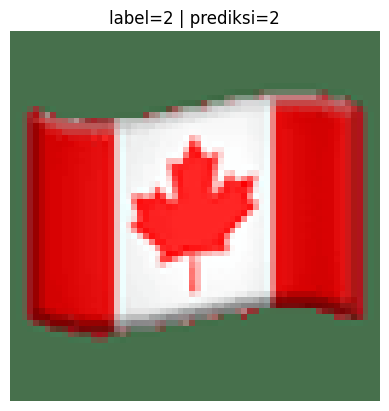

[TEST] size=64x64 | channels=3 | label=2 | prediksi=2 | idx =246


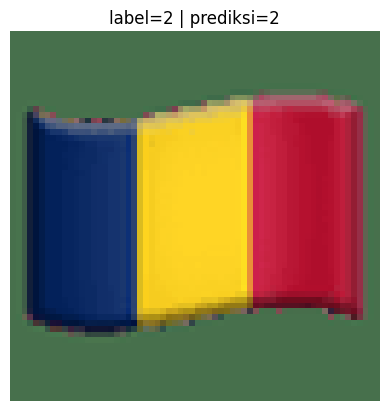

[TEST] size=64x64 | channels=3 | label=1 | prediksi=2 | idx =247


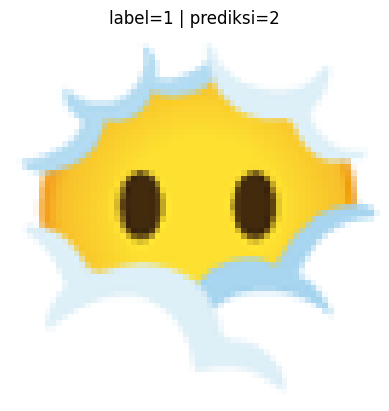

[TEST] size=64x64 | channels=3 | label=1 | prediksi=2 | idx =248


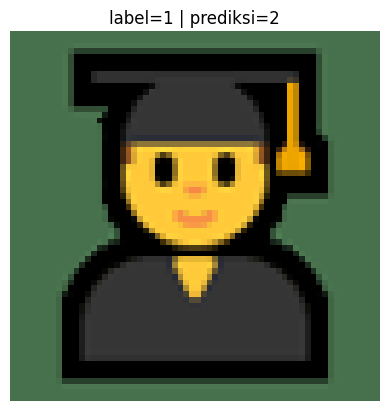

[TEST] size=64x64 | channels=3 | label=1 | prediksi=1 | idx =249


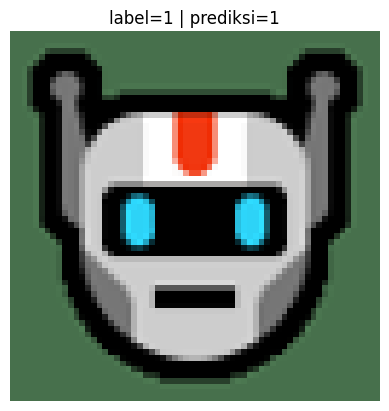

[TEST] size=64x64 | channels=3 | label=2 | prediksi=2 | idx =250


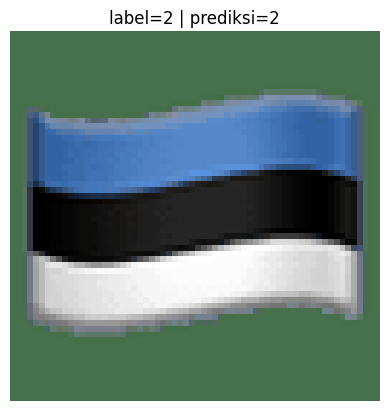

[TEST] size=64x64 | channels=3 | label=2 | prediksi=2 | idx =251


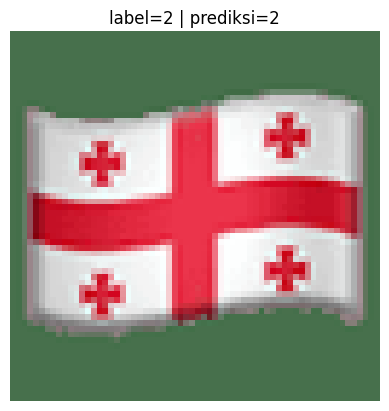

[TEST] size=64x64 | channels=3 | label=2 | prediksi=2 | idx =252


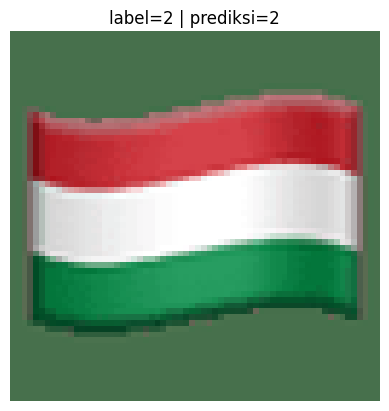

[TEST] size=64x64 | channels=3 | label=1 | prediksi=2 | idx =253


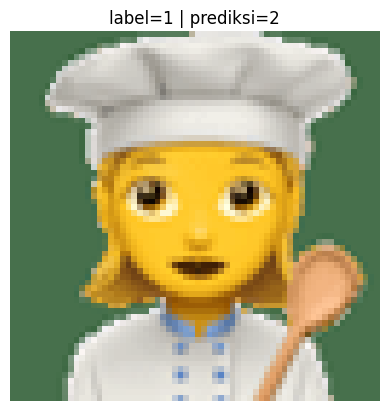

[TEST] size=64x64 | channels=3 | label=2 | prediksi=2 | idx =254


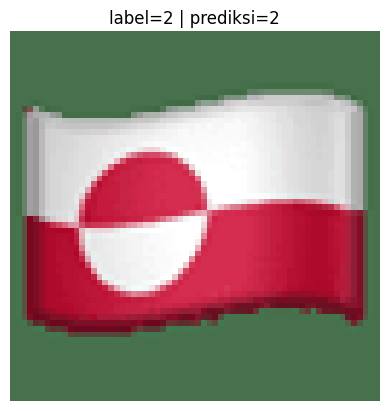

[TEST] size=64x64 | channels=3 | label=2 | prediksi=2 | idx =255


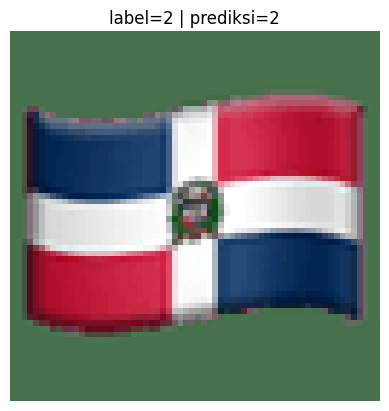

[TEST] size=64x64 | channels=3 | label=1 | prediksi=1 | idx =256


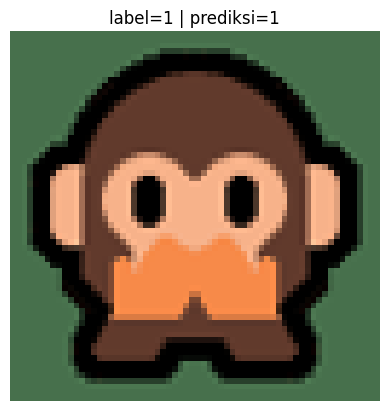

[TEST] size=64x64 | channels=3 | label=2 | prediksi=2 | idx =257


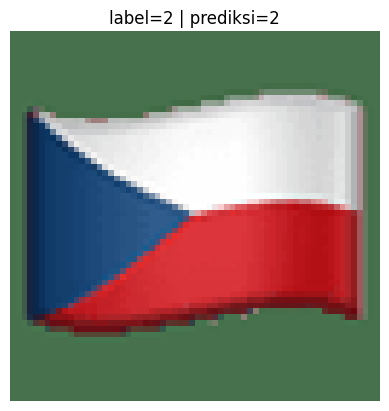

[TEST] size=64x64 | channels=3 | label=1 | prediksi=1 | idx =258


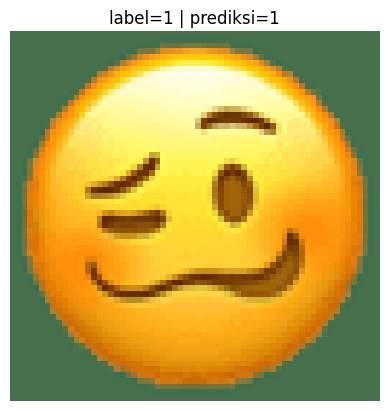

[TEST] size=64x64 | channels=3 | label=2 | prediksi=2 | idx =259


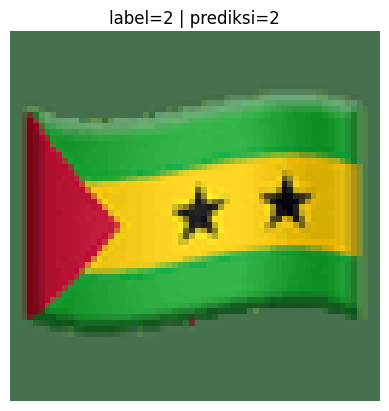

[TEST] size=64x64 | channels=3 | label=1 | prediksi=1 | idx =260


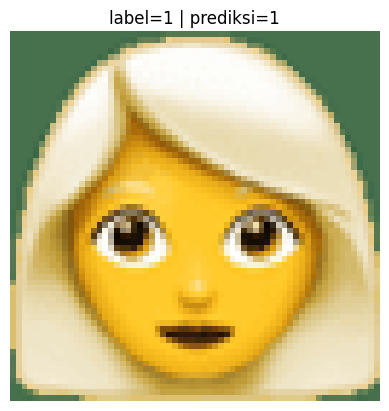

[TEST] size=64x64 | channels=3 | label=2 | prediksi=2 | idx =261


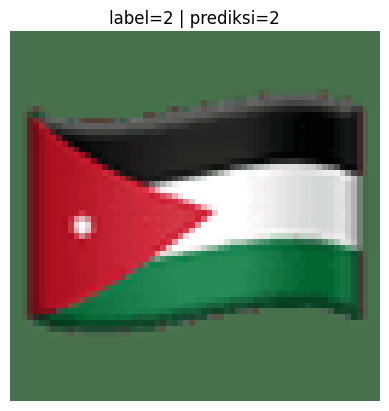

[TEST] size=64x64 | channels=3 | label=2 | prediksi=2 | idx =262


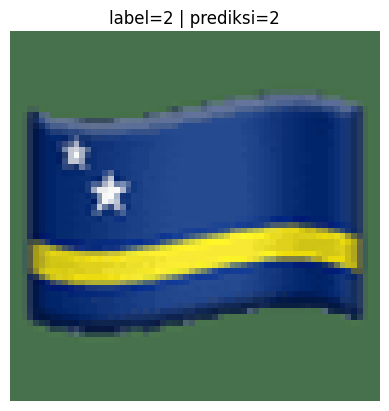

[TEST] size=64x64 | channels=3 | label=2 | prediksi=2 | idx =263


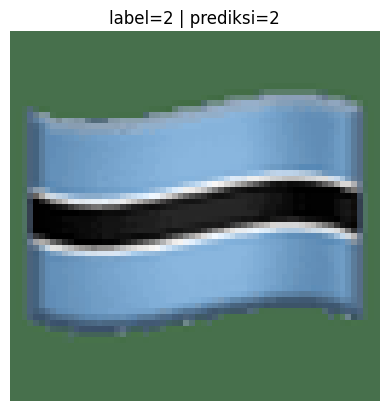

[TEST] size=64x64 | channels=3 | label=1 | prediksi=1 | idx =264


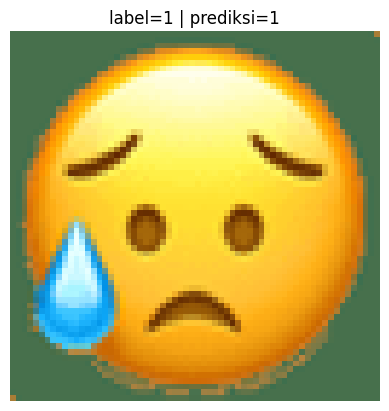

[TEST] size=64x64 | channels=3 | label=1 | prediksi=2 | idx =265


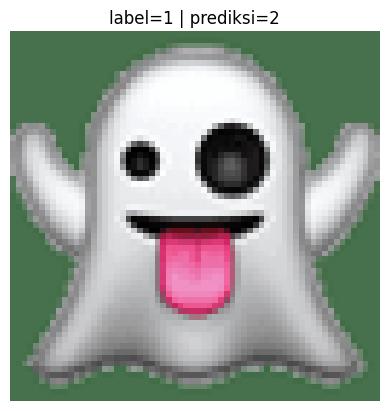

[TEST] size=64x64 | channels=3 | label=1 | prediksi=1 | idx =266


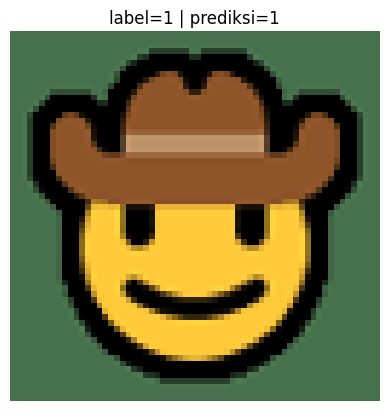

[TEST] size=64x64 | channels=3 | label=1 | prediksi=1 | idx =267


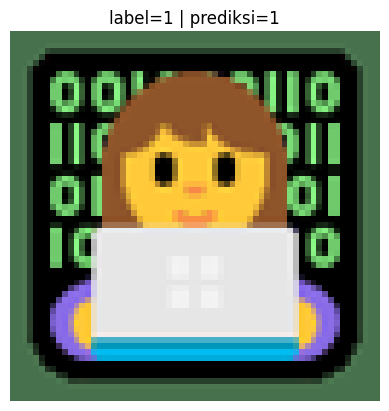

[TEST] size=64x64 | channels=3 | label=2 | prediksi=2 | idx =268


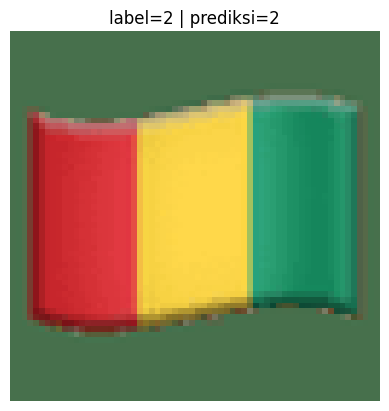

[TEST] size=64x64 | channels=3 | label=1 | prediksi=1 | idx =269


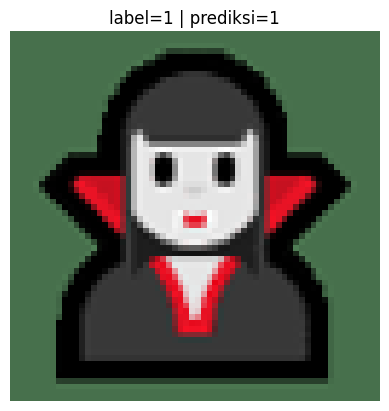

[TEST] size=64x64 | channels=3 | label=2 | prediksi=2 | idx =270


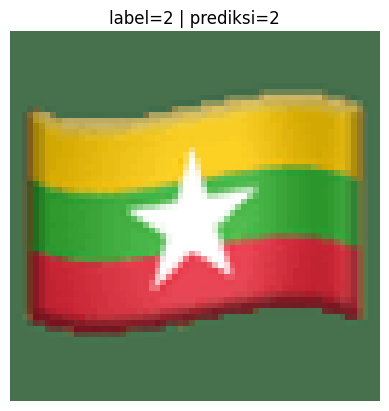

[TEST] size=64x64 | channels=3 | label=2 | prediksi=2 | idx =271


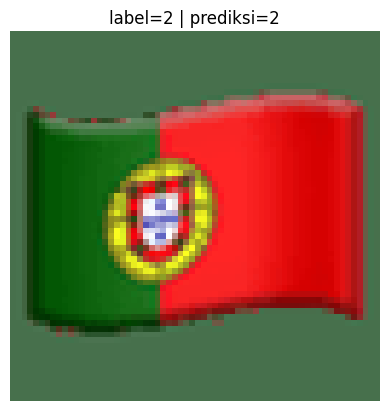

[TEST] size=64x64 | channels=3 | label=2 | prediksi=2 | idx =272


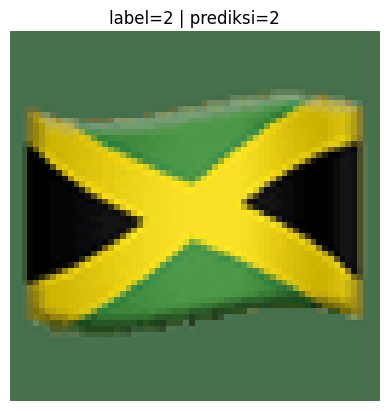

[TEST] size=64x64 | channels=3 | label=1 | prediksi=1 | idx =273


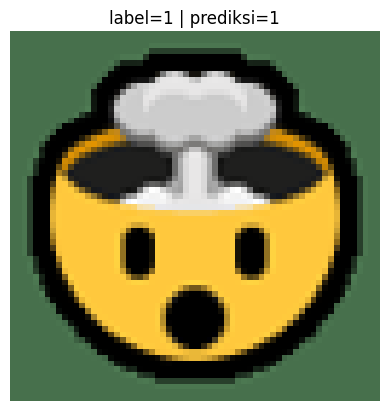

[TEST] size=64x64 | channels=3 | label=2 | prediksi=2 | idx =274


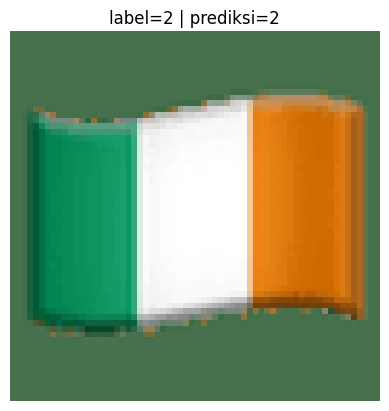

[TEST] size=64x64 | channels=3 | label=1 | prediksi=1 | idx =275


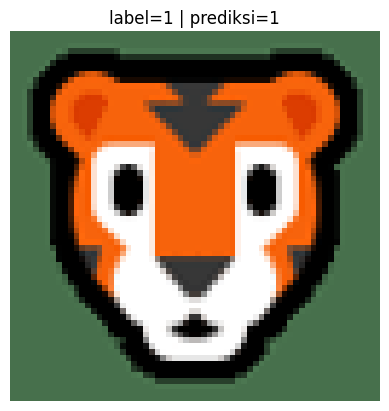

[TEST] size=64x64 | channels=3 | label=2 | prediksi=2 | idx =276


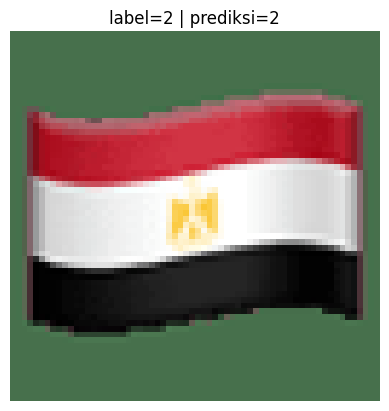

[TEST] size=64x64 | channels=3 | label=1 | prediksi=1 | idx =277


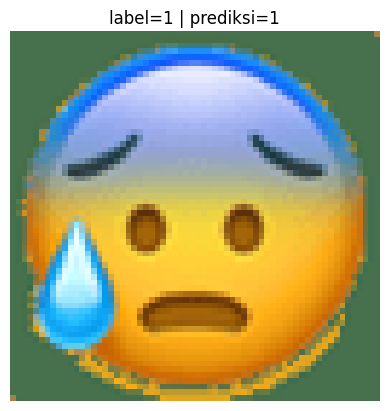

[TEST] size=64x64 | channels=3 | label=1 | prediksi=1 | idx =278


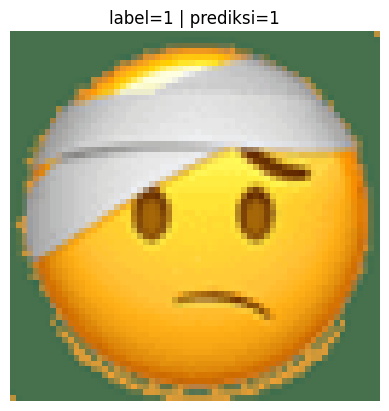

[TEST] size=64x64 | channels=3 | label=2 | prediksi=2 | idx =279


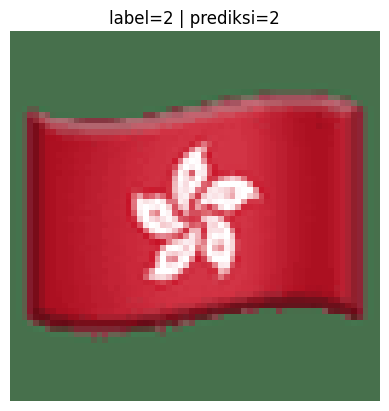

[TEST] size=64x64 | channels=3 | label=2 | prediksi=2 | idx =280


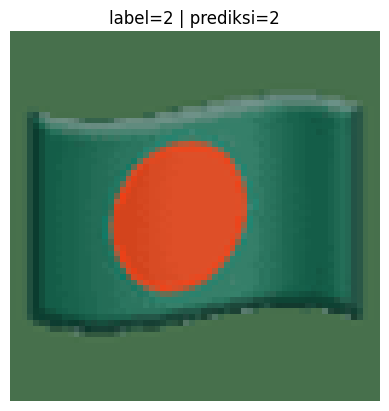

[TEST] size=64x64 | channels=3 | label=2 | prediksi=2 | idx =281


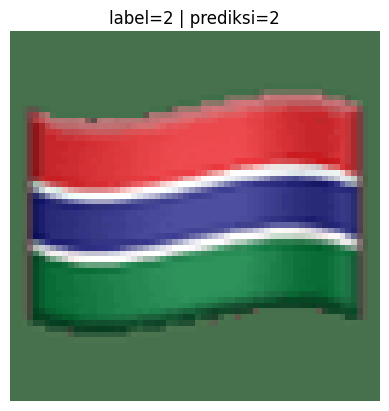

[TEST] size=64x64 | channels=3 | label=2 | prediksi=2 | idx =282


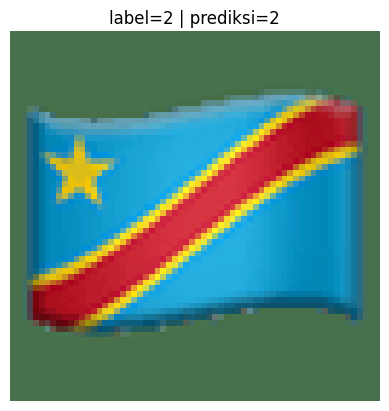

[TEST] size=64x64 | channels=3 | label=1 | prediksi=1 | idx =283


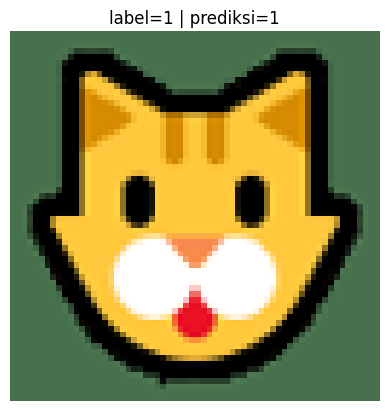

[TEST] size=64x64 | channels=3 | label=2 | prediksi=2 | idx =284


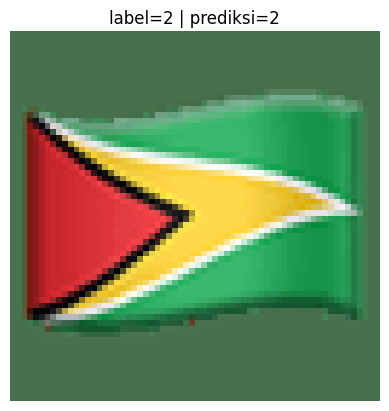

[TEST] size=64x64 | channels=3 | label=2 | prediksi=2 | idx =285


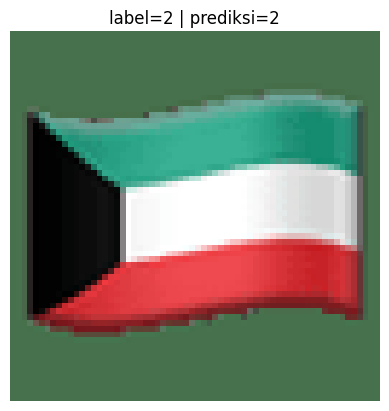

[TEST] size=64x64 | channels=3 | label=2 | prediksi=2 | idx =286


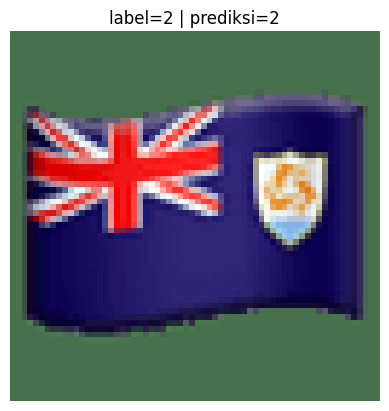

[TEST] size=64x64 | channels=3 | label=2 | prediksi=2 | idx =287


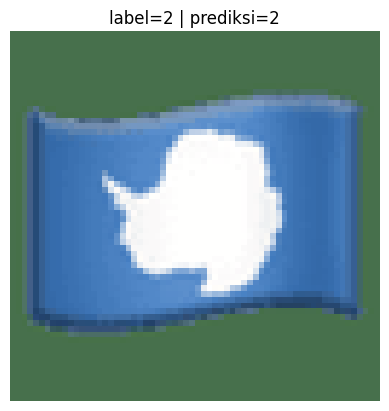

[TEST] size=64x64 | channels=3 | label=2 | prediksi=2 | idx =288


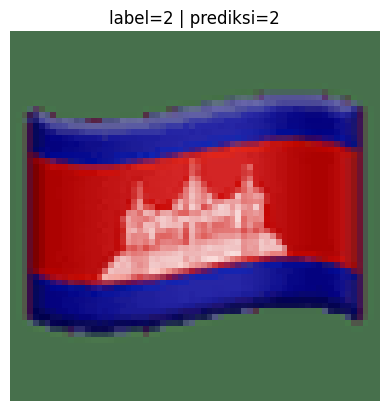

[TEST] size=64x64 | channels=3 | label=1 | prediksi=1 | idx =289


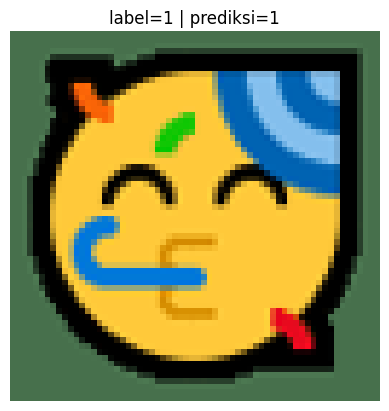

[TEST] size=64x64 | channels=3 | label=1 | prediksi=1 | idx =290


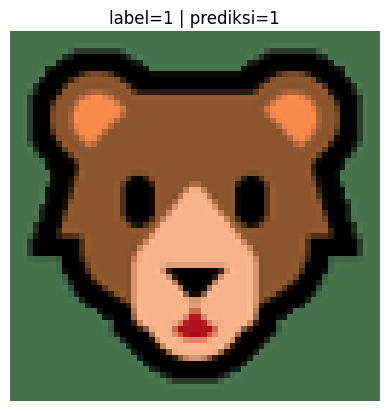

[TEST] size=64x64 | channels=3 | label=1 | prediksi=1 | idx =291


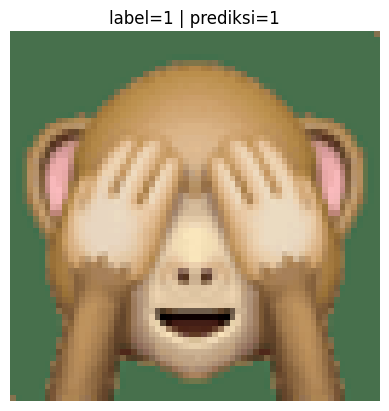

[TEST] size=64x64 | channels=3 | label=1 | prediksi=2 | idx =292


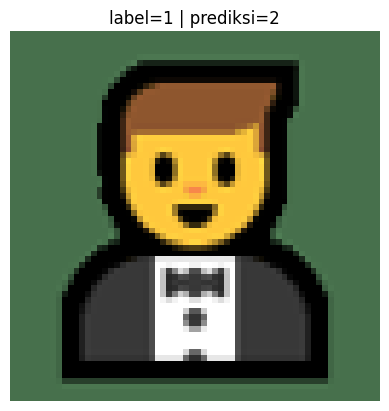

[TEST] size=64x64 | channels=3 | label=2 | prediksi=2 | idx =293


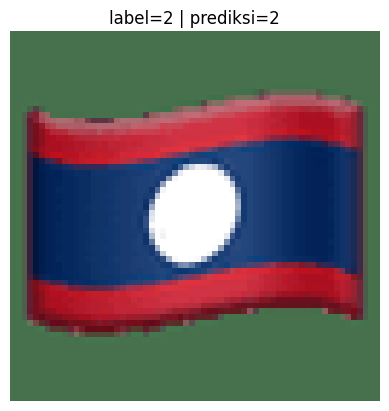

[TEST] size=64x64 | channels=3 | label=1 | prediksi=2 | idx =294


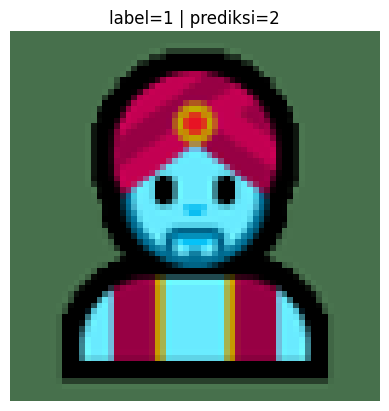

[TEST] size=64x64 | channels=3 | label=2 | prediksi=2 | idx =295


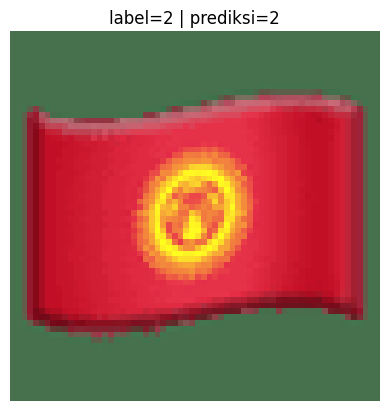

[TEST] size=64x64 | channels=3 | label=2 | prediksi=2 | idx =296


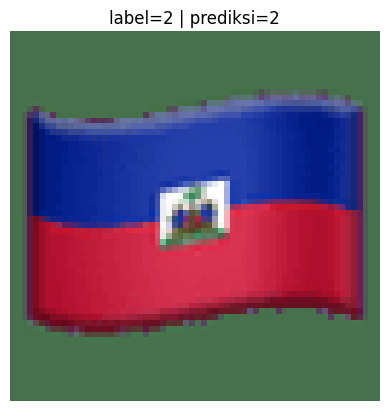

[TEST] size=64x64 | channels=3 | label=1 | prediksi=1 | idx =297


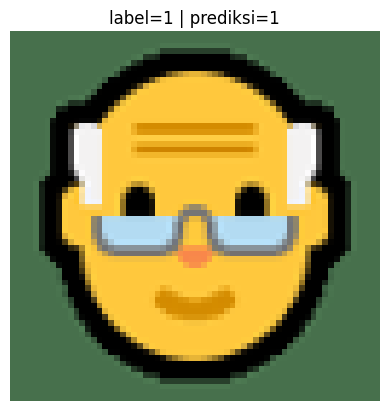

[TEST] size=64x64 | channels=3 | label=1 | prediksi=1 | idx =298


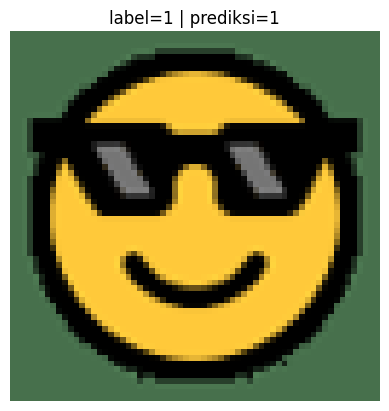

[TEST] size=64x64 | channels=3 | label=1 | prediksi=1 | idx =299


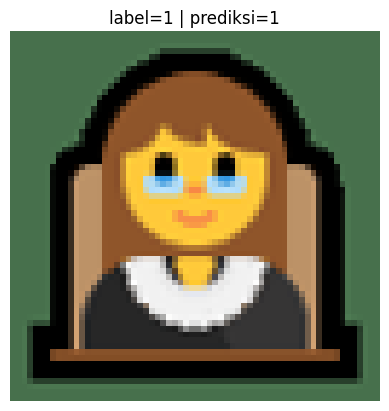

[TEST] size=64x64 | channels=3 | label=2 | prediksi=2 | idx =300


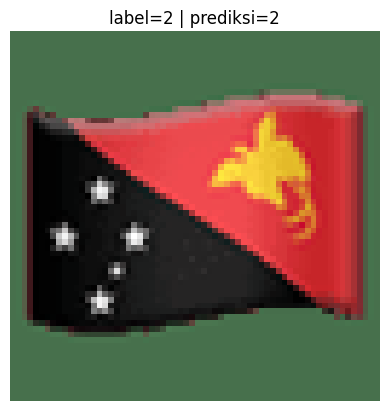

[TEST] size=64x64 | channels=3 | label=1 | prediksi=1 | idx =301


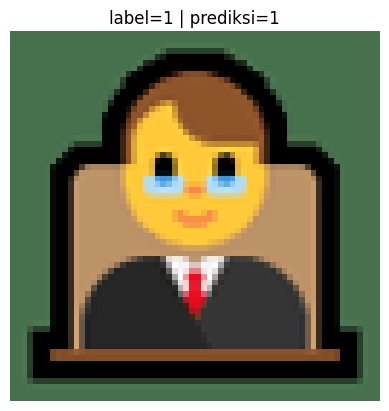

[TEST] size=64x64 | channels=3 | label=1 | prediksi=2 | idx =302


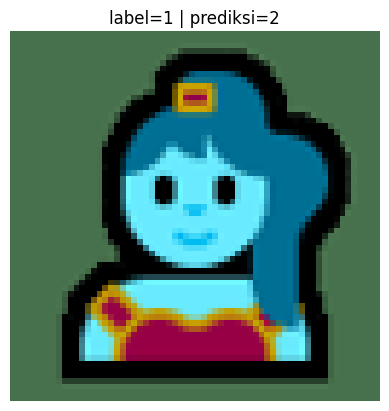

[TEST] size=64x64 | channels=3 | label=2 | prediksi=2 | idx =303


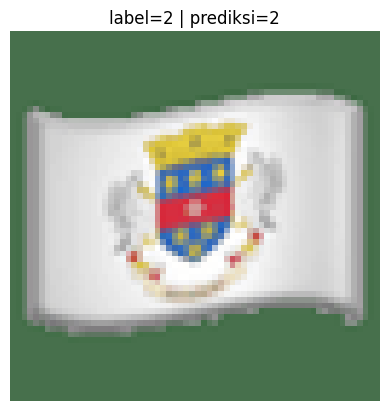

[TEST] size=64x64 | channels=3 | label=1 | prediksi=1 | idx =304


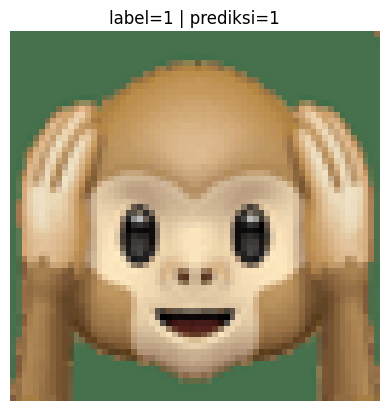

[TEST] size=64x64 | channels=3 | label=2 | prediksi=2 | idx =305


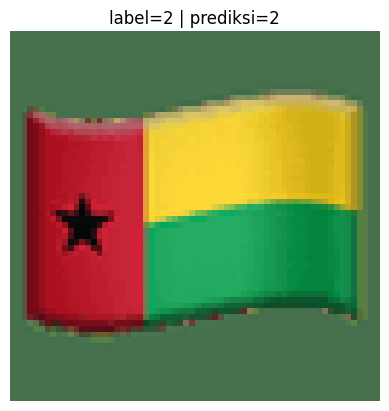

[TEST] size=64x64 | channels=3 | label=2 | prediksi=2 | idx =306


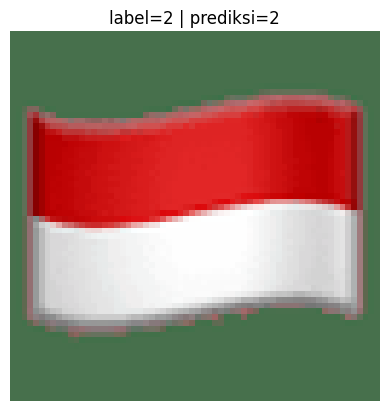

[TEST] size=64x64 | channels=3 | label=1 | prediksi=1 | idx =307


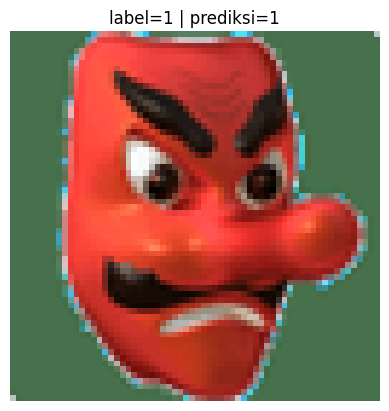

[TEST] size=64x64 | channels=3 | label=1 | prediksi=1 | idx =308


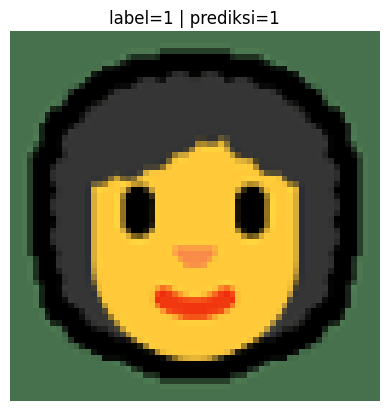

[TEST] size=64x64 | channels=3 | label=1 | prediksi=2 | idx =309


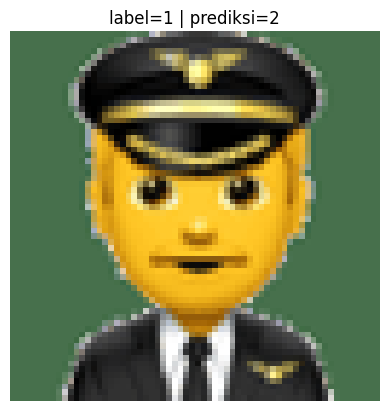

Evaluasi pada 310 sampel test:
Akurasi     : 0.8968
F1 Macro    : 0.8928


In [ ]:
# Template TRAIN (tanpa NumPy di kode Anda):
# - Mengiterasi contoh latih satu per satu
# - Mengonversi gambar menjadi list bersarang: img[baris][kolom] -> [R, G, B] (nilai 0..255)
# - Menampilkan informasi ukuran/kanal + visualisasi
# - Menyediakan tempat kosong untuk menulis fitur/keputusan Anda sendiri

FILE_ID = "1sgh5ofZ1Eg9J2TchSzdf1WOjB9PIeoO4"  # WITHOUT THE KEYS
!gdown --id {FILE_ID} -O OSNAI2025_privateGT.zip
!unzip -o OSNAI2025_privateGT.zip -d /content/

# Import path
import sys
sys.path.append("/content/OSNAI2025_pack")

from emoji_test_gt import X_test, y_test  # private ground-truth module

import matplotlib.pyplot as plt

THRESH_N = 310  # batasi berapa banyak sampel yang diproses (agar cepat saat eksplorasi)

# (Opsional) list untuk menyimpan prediksi Anda (jika ingin mengevaluasi/submit nanti)
preds = []  # isi dengan 1 atau 2 untuk tiap sampel (panjangnya bebas di tahap eksplorasi)

N = min(THRESH_N, len(X_test))
for i in range(N):
    # Ambil satu gambar dan ubah ke list bersarang (tanpa bergantung pada NumPy di logika Anda)
    img = X_test[i].tolist()  # ukuran: H x W x 3, masing-masing piksel = [R, G, B] (0..255)

    # Ambil label (1 atau 2) untuk data TRAIN
    label = int(y_test[i])

    # Informasi struktur gambar
    H = len(img)                             # jumlah baris (tinggi)
    W = len(img[0]) if H > 0 else 0          # jumlah kolom (lebar)
    C = len(img[0][0]) if (H > 0 and W > 0) else 0  # jumlah kanal (harusnya 3 = RGB)

    # Memanggil fungsi `prediksi_gambar_img` yang Anda buat untuk memprediksi kelas gambar img.
    prediksi_label = prediksi_gambar_img(img)
    preds.append(prediksi_label)

    # (Opsional) Visualisasi untuk pengecekan cepat
    print(f"[TEST] size={H}x{W} | channels={C} | label={label} | prediksi={prediksi_label} | idx ={i}")
    plt.imshow(img)
    plt.axis('off')
    plt.title(f"label={label} | prediksi={prediksi_label}")
    plt.show()

# Anda bisa menggunakan variabel 'preds' untuk mengevaluasi TRAIN,
# dengan membandingkan 'preds' vs 'y_test'.

# ------------------------------
# CEK & EVALUASI
# ------------------------------
if len(preds) != N:
    raise RuntimeError(
        f"Prediksi belum lengkap: len(preds)={len(preds)} sementara N={N}. "
        "Silakan isi blok 'KODE ANDA MULAI DI SINI' untuk menghasilkan prediksi."
    )

acc, f1_macro = evaluate_binary_12(y_test[:N], preds)

print(f"Evaluasi pada {N} sampel test:")
print(f"Akurasi     : {acc:.4f}")
print(f"F1 Macro    : {f1_macro:.4f}")

# Penilaian

Peserta dengan akurasi terbaik akan mendapatkan nilai sempurna (100).
Baseline akurasi adalah 50%. Peserta dengan performa akurasi sama atau lebih kecil dari baseline akan mendapatkan 0.

Selain itu, peserta mendapatkan nilai yang dinormalisasi:

100 * (akurasi_peserta - baseline) / (best_peserta - baseline)

Baseline adalah 50%